# QUBO Portfolio Optimization (NSE / BSE)
This notebook builds a discretized-weight QUBO for a Markowitz-style portfolio (binary-encode weights per asset).
It fetches Indian stock data via `yfinance`, constructs the QUBO $f(x)=\lambda x^T\Sigma x - \mu^T x + P(\sum_i w_i - 1)^2$
solves the binary optimization with an available sampler, and visualizes results.

In [2]:
%pip install -q yfinance dimod neal matplotlib seaborn pandas numpy

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement neal (from versions: none)

[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for neal


In [3]:
import warnings
warnings.filterwarnings('ignore')
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import dimod
from math import sqrt

In [4]:
# User-editable: choose tickers (Yahoo format). Use .NS for NSE or .BO for BSE.
tickers = [
    'RELIANCE.NS',
    'TCS.NS',
    'INFY.NS',
    'HDFCBANK.NS',
    'ITC.NS',
    'HINDUNILVR.NS'
]
start_date = '2022-01-01'
end_date = None  # None for today

In [5]:
# Robust per-ticker downloader and normalization
from collections import OrderedDict
def download_prices(ticker_list, start, end=None):
    results = OrderedDict()
    failed = []
    for t in ticker_list:
        try:
            raw_t = yf.download(t, start=start, end=end, progress=False)
        except Exception as e:
            failed.append((t, str(e)))
            continue
        if raw_t is None or getattr(raw_t, 'empty', False):
            failed.append((t, 'no data'))
            continue
        # prefer Adj Close / Close and coerce to a Series named by ticker
        ser = None
        try:
            if hasattr(raw_t, 'columns') and getattr(raw_t.columns, 'nlevels', 1) > 1:
                lvl0 = raw_t.columns.get_level_values(0)
                if 'Adj Close' in lvl0:
                    s = raw_t['Adj Close']
                elif 'Close' in lvl0:
                    s = raw_t['Close']
                else:
                    s = raw_t.copy()
                    s.columns = s.columns.get_level_values(-1)
                if isinstance(s, pd.DataFrame):
                    if t in s.columns:
                        ser = s[t]
                    else:
                        ser = s.iloc[:, -1]
                else:
                    ser = s
            else:
                if isinstance(raw_t, pd.DataFrame):
                    if 'Adj Close' in raw_t.columns:
                        ser = raw_t['Adj Close']
                    elif 'Close' in raw_t.columns:
                        ser = raw_t['Close']
                    else:
                        ser = raw_t.iloc[:, -1]
                else:
                    ser = raw_t
        except Exception:
            failed.append((t, 'parsing error'))
            continue
        if ser is None or getattr(ser, 'empty', False):
            failed.append((t, 'empty series'))
            continue
        ser = ser.rename(t)
        results[t] = ser
    if not results:
        print('No tickers returned usable data. Failed:', failed)
        return pd.DataFrame()
    prices_df = pd.concat(list(results.values()), axis=1)
    prices_df = prices_df.dropna(axis=1, how='all')
    prices_df = prices_df.fillna(method='ffill').dropna()
    print(f'Downloaded {len(prices_df.columns)} tickers; failed: {len(failed)}')
    if failed:
        print('Failed tickers (sample):', [f[0] for f in failed][:10])
    return prices_df
# perform download for the user-selected tickers
prices = download_prices(tickers, start_date, end_date)
if prices.empty:
    raise RuntimeError('No price data available after downloading tickers. See earlier prints for failures')
# ensure simple string column names
prices.columns = [str(c) for c in prices.columns]
prices.tail()

Downloaded 6 tickers; failed: 0


,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ITC.NS,HINDUNILVR.NS
Date,,,,,,
2026-09-24,1219.199951,2087.000000,1014.500000,728.900024,268.000000,1933.500000
2026-09-25,1226.000000,2082.000000,1000.200012,735.599976,269.000000,1942.900024
2026-09-28,1197.599976,2070.699951,1003.200012,719.049988,265.200012,1896.000000
2026-09-29,1182.000000,2032.400024,1015.400024,722.700012,265.100006,1863.800049
2026-09-30,1190.400024,2087.800049,1016.599976,715.299988,265.850006,1880.500000


In [6]:
# Compute daily returns, annualize mean and covariance
returns = prices.pct_change().dropna()
mu = returns.mean() * 252  # annualized expected returns
Sigma = returns.cov() * 252  # annualized covariance
assets = list(mu.index)
n = len(assets)
print(f'Found {n} assets:', assets)

Found 6 assets: ['RELIANCE.NS', 'TCS.NS', 'INFY.NS', 'HDFCBANK.NS', 'ITC.NS', 'HINDUNILVR.NS']


In [7]:
# Discretized weight encoding (binary weights per asset)
bits_per_asset = 3  # number of binary bits per asset (adjust resolution)
delta = 1.0 / (2**bits_per_asset - 1)  # resolution so max weight ~1.0
lambda_risk = 0.5
# Heuristic penalty: try symmetric eigenvalues; fallback on safe heuristics if convergence fails
Sigma_sym = (Sigma + Sigma.T) / 2.0
Sigma_clean = np.nan_to_num(Sigma_sym, nan=0.0, posinf=1e10, neginf=-1e10)
# Guard against empty covariance (no returns / bad download). Use safe fallback if empty
if Sigma_clean.size == 0 or Sigma_clean.shape[0] == 0:
    print('Warning: empty covariance matrix (Sigma). Using default maxeig=1.0')
    maxeig = 1.0
else:
    try:
        ev = np.linalg.eigvalsh(Sigma_clean)
        if ev.size == 0:
            raise ValueError('empty eigenvalues')
        maxeig = float(ev.max())
    except Exception:
        try:
            ev2 = np.linalg.eigvals(Sigma_clean)
            if ev2.size == 0:
                raise ValueError('empty eigenvalues2')
            maxeig = float(np.max(np.abs(ev2)))
        except Exception:
            # final fallback: use max variance or max absolute entry (or 1.0 if still empty)
            if Sigma_clean.size == 0:
                maxeig = 1.0
            else:
                maxeig = float(max(np.max(np.abs(np.diag(Sigma_clean))), np.max(np.abs(Sigma_clean))))
P = max(1.0, maxeig * 5.0)  # heuristic penalty (see notes)
# Build variable list and coefficient for each binary variable
vars = []  # list of (asset_index, bit)
coef = {}  # variable -> coefficient in weight representation
for i in range(n):
    for b in range(bits_per_asset):
        name = f'x_{i}_{b}'
        vars.append((i, b))
        coef[name] = float(delta * (2 ** b))
# Build linear and quadratic dictionaries for BQM
from collections import defaultdict
linear = defaultdict(float)
quadratic = defaultdict(float)
offset = P * 1.0  # from penalty constant term (sum w - 1)^2 expands to +1
# Return term linear contributions and budget linear term (-2*P*coef)
for i in range(n):
    for b in range(bits_per_asset):
        name = f'x_{i}_{b}'
        linear[name] += -float(mu[assets[i]] * coef[name]) - 2.0 * P * coef[name]
# Risk and penalty quadratic (and diagonal) contributions
for i in range(n):
    for b in range(bits_per_asset):
        name_u = f'x_{i}_{b}'
        for j in range(n):
            for c in range(bits_per_asset):
                name_v = f'x_{j}_{c}'
                contrib = float(lambda_risk * Sigma.iloc[i, j] * coef[name_u] * coef[name_v] + P * coef[name_u] * coef[name_v])
                if name_u == name_v:
                    linear[name_u] += contrib
                else:
                    # keep key ordering consistent (u,v) with u<v-like ordering
                    key = (name_u, name_v) if name_u < name_v else (name_v, name_u)
                    quadratic[key] += contrib
# Construct BQM
bqm = dimod.BinaryQuadraticModel(dict(linear), dict(quadratic), float(offset), vartype=dimod.BINARY)
print('BQM built — binary vars:', len(vars), 'bits_per_asset:', bits_per_asset, 'offset:', offset)

BQM built — binary vars: 18 bits_per_asset: 3 offset: 1.0


In [8]:
# Solve the BQM: small problems use ExactSolver, otherwise use Simulated Annealing
try:
    # determine variable count in a safe way
    if hasattr(bqm, 'num_variables'):
        nvars = bqm.num_variables
    else:
        try:
            nvars = len(bqm.variables)
        except Exception:
            nvars = sum(1 for _ in bqm)
    if nvars <= 20:
        sampler = dimod.ExactSolver()
        sampleset = sampler.sample(bqm)
    else:
        try:
            import neal
            sampler = neal.SimulatedAnnealingSampler()
            sampleset = sampler.sample(bqm, num_reads=1000)
        except Exception:
            # fallback to ExactSolver if neal not available
            sampler = dimod.ExactSolver()
            sampleset = sampler.sample(bqm)
except Exception as e:
    print('Sampler error, falling back to ExactSolver:', e)
    sampler = dimod.ExactSolver()
    sampleset = sampler.sample(bqm)
# Take best sample
best = sampleset.first
solution = best.sample
energy = best.energy
print('Raw sample energy:', energy)
# Decode weights per asset
weights = np.zeros(n)
for i in range(n):
    w = 0.0
    for b in range(bits_per_asset):
        var = f'x_{i}_{b}'
        if solution.get(var, 0) == 1:
            w += coef[var]
    weights[i] = w
# Normalize to budget 1 (in case penalty not exact)
if weights.sum() > 0:
    weights = weights / weights.sum()
# Create a mapping asset->weight
asset_weights = dict(zip(assets, weights))
asset_weights, float(weights.sum())

Raw sample energy: -0.09269297178892172


({'RELIANCE.NS': np.float64(0.0),
  'TCS.NS': np.float64(0.0),
  'INFY.NS': np.float64(0.0),
  'HDFCBANK.NS': np.float64(0.0),
  'ITC.NS': np.float64(1.0),
  'HINDUNILVR.NS': np.float64(0.0)},
 1.0)

In [9]:
# Compute portfolio metrics from decoded weights
w = weights
port_return = float(np.dot(w, mu.values))
port_vol = float(sqrt(w @ Sigma.values @ w))
print(f'Portfolio annual return: {port_return:.2%}, vol: {port_vol:.2%}')
# Show non-zero asset weights
[(assets[i], float(w[i])) for i in range(n) if w[i] > 1e-6]

Portfolio annual return: 11.09%, vol: 19.11%


[('ITC.NS', 1.0)]

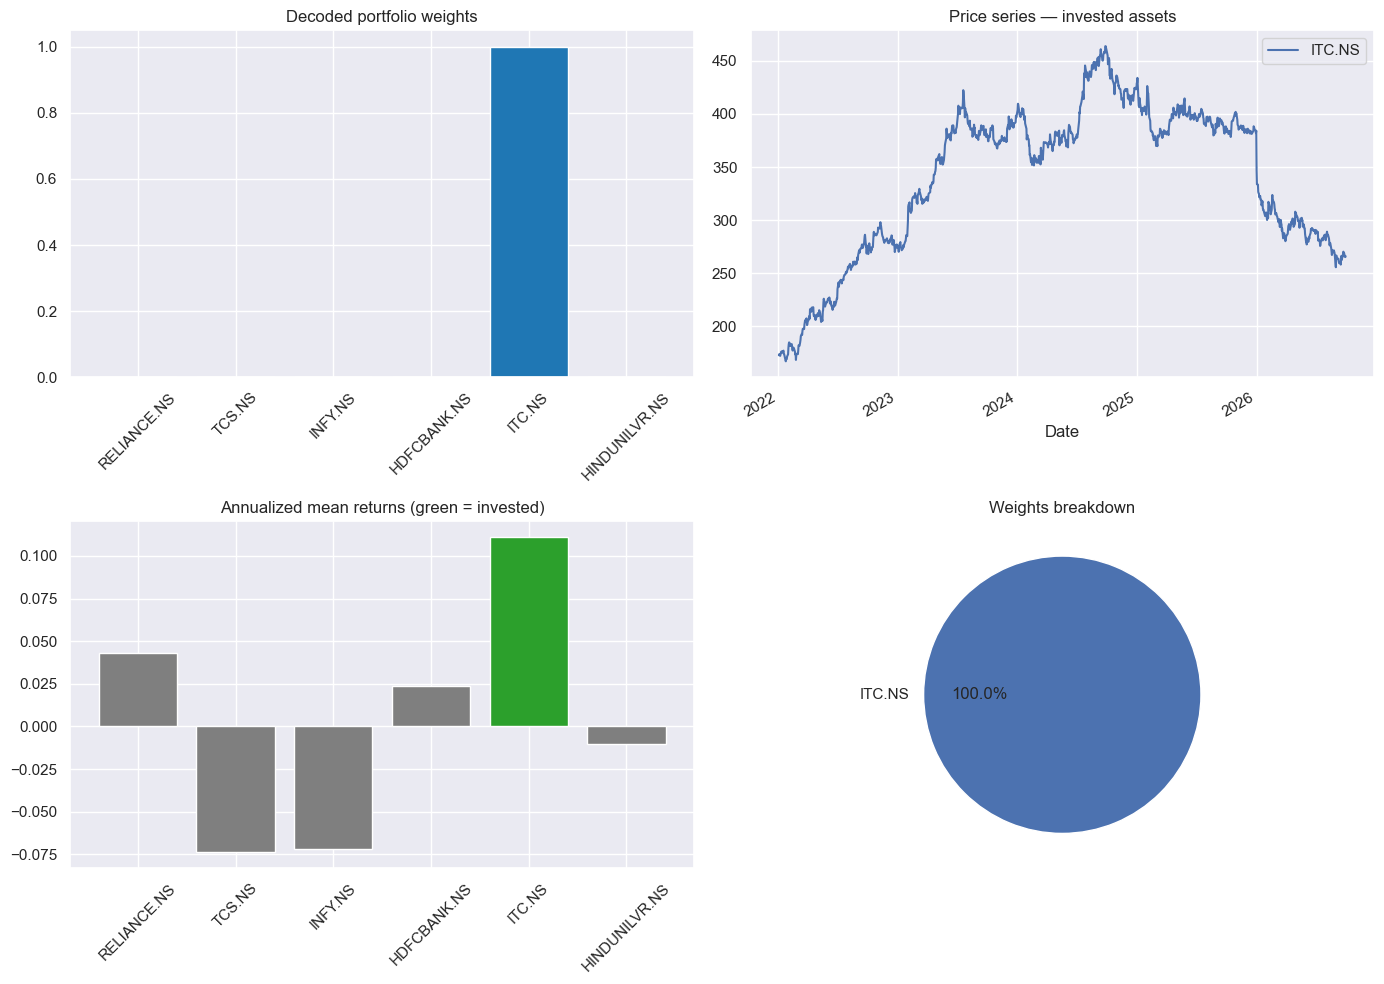

In [10]:
# Plots: weight distribution, price series for assets with non-zero weights, returns bar
# Try seaborn style if available, otherwise fallback to default
try:
    plt.style.use('seaborn')
except Exception:
    try:
        import seaborn as sns
        sns.set()
    except Exception:
        plt.style.use('default')
nonzero_idx = [i for i in range(n) if weights[i] > 1e-6]
# Guard: if no assets or no weights, show message instead of plotting empty charts
if n == 0:
    print('No downloaded assets to plot. Check downloader output in previous cells.')
else:
    # Coerce asset names and weights to simple sequences for plotting
    names = [str(a) for a in assets]
    heights = np.asarray(weights).flatten().tolist()
    x = np.arange(len(names))
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Weight bar chart (use integer x positions to avoid hashing issues)
    axes[0,0].bar(x, heights, color='tab:blue')
    axes[0,0].set_title('Decoded portfolio weights')
    axes[0,0].set_xticks(x)
    axes[0,0].set_xticklabels(names, rotation=45)

    # Price series for non-zero assets
    if nonzero_idx:
        sel_assets = [names[i] for i in nonzero_idx]
        prices[sel_assets].plot(ax=axes[0,1], title='Price series — invested assets')
        axes[0,1].legend(loc='best')
    else:
        axes[0,1].text(0.5, 0.5, 'No invested assets', ha='center')

    # Bar chart of annualized mean returns
    colors = ['tab:green' if i in nonzero_idx else 'tab:gray' for i in range(n)]
    axes[1,0].bar(x, mu.values, color=colors)
    axes[1,0].set_title('Annualized mean returns (green = invested)')
    axes[1,0].set_xticks(x)
    axes[1,0].set_xticklabels(names, rotation=45)

    # Pie chart of weights
    if nonzero_idx:
        axes[1,1].pie([weights[i] for i in nonzero_idx], labels=[names[i] for i in nonzero_idx], autopct='%1.1f%%')
        axes[1,1].set_title('Weights breakdown')
    else:
        axes[1,1].text(0.5, 0.5, 'No invested assets', ha='center')

    plt.tight_layout()
    plt.show()

In [11]:
# Cell 11: Fetch NIFTY 50 tickers, download data, compute mu/Sigma, build QUBO (discretized weights)
import pandas as pd
import numpy as np
import yfinance as yf
from collections import defaultdict
# 1) Use official NIFTY50 ticker list (50 constituents, yfinance only) — no Wikipedia scraping
# Updated to match official NIFTY50 index constituents
nifty_tickers = [
    # Financial Services (12)
    'AXISBANK.NS', 'BAJFINANCE.NS', 'BAJAJFINSV.NS', 'HDFCBANK.NS', 'HDFCLIFE.NS',
    'ICICIBANK.NS', 'INDUSINDBK.NS', 'JIOFINANCE.NS', 'KOTAKBANK.NS', 'SBILIFE.NS',
    'SHRIRAMFIN.NS', 'SBIN.NS',
    # Information Technology (6)
    'HCLTECH.NS', 'INFY.NS', 'TECHM.NS', 'TCS.NS', 'WIPRO.NS', 'LT.NS',
    # Automobiles & Auto Components (6)
    'BAJAJUTO.NS', 'EICHERMOT.NS', 'HEROMOTOCO.NS', 'M&M.NS', 'MARUTI.NS', 'TATAMOTORS.NS',
    # Oil, Gas & Consumable Fuels (4)
    'BPCL.NS', 'COALINDIA.NS', 'ONGC.NS', 'RELIANCE.NS',
    # Fast-Moving Consumer Goods - FMCG (5)
    'BRITANNIA.NS', 'HINDUNILVR.NS', 'ITC.NS', 'NESTLEIND.NS', 'TATACONSUM.NS',
    # Healthcare & Pharmaceuticals (6)
    'APOLLOHOSP.NS', 'CIPLA.NS', 'DIVISLAB.NS', 'DRREDDY.NS', 'MAXHEALTH.NS', 'SUNPHARMA.NS',
    # Metals & Mining (3)
    'HINDALCO.NS', 'JSWSTEEL.NS', 'TATASTEEL.NS',
    # Power & Energy (2)
    'NTPC.NS', 'POWERGRID.NS',
    # Consumer Durables & Retail (3)
    'ASIANPAINT.NS', 'TITAN.NS', 'TRENT.NS',
    # Construction, Cement & Capital Goods (4)
    'BEL.NS', 'GRASIM.NS', 'ULTRACEMCO.NS'
]
print(f'Using official NIFTY50 list ({len(nifty_tickers)} tickers) — downloading via yfinance')
# 2) Download price data for these tickers using the robust downloader
start_dl = start_date if 'start_date' in globals() else '2022-01-01'
# reuse download_prices if available, otherwise define locally
try:
    prices2 = download_prices(nifty_tickers, start_dl)
except NameError:
    # define local fallback downloader (similar to previous cell)
    from collections import OrderedDict
    def download_prices_local(ticker_list, start, end=None):
        results = OrderedDict()
        failed = []
        for t in ticker_list:
            try:
                raw_t = yf.download(t, start=start, end=end, progress=False)
            except Exception as e:
                failed.append((t, str(e)))
                continue
            if raw_t is None or getattr(raw_t, 'empty', False):
                failed.append((t, 'no data'))
                continue
            ser = None
            try:
                if hasattr(raw_t, 'columns') and getattr(raw_t.columns, 'nlevels', 1) > 1:
                    lvl0 = raw_t.columns.get_level_values(0)
                    if 'Adj Close' in lvl0:
                        s = raw_t['Adj Close']
                    elif 'Close' in lvl0:
                        s = raw_t['Close']
                    else:
                        s = raw_t.copy()
                        s.columns = s.columns.get_level_values(-1)
                    if isinstance(s, pd.DataFrame):
                        if t in s.columns:
                            ser = s[t]
                        else:
                            ser = s.iloc[:, -1]
                    else:
                        ser = s
                else:
                    if isinstance(raw_t, pd.DataFrame):
                        if 'Adj Close' in raw_t.columns:
                            ser = raw_t['Adj Close']
                        elif 'Close' in raw_t.columns:
                            ser = raw_t['Close']
                        else:
                            ser = raw_t.iloc[:, -1]
                    else:
                        ser = raw_t
            except Exception:
                failed.append((t, 'parsing error'))
                continue
            if ser is None or getattr(ser, 'empty', False):
                failed.append((t, 'empty series'))
                continue
            ser = ser.rename(t)
            results[t] = ser
        if not results:
            print('No tickers returned usable data. Failed:', failed)
            return pd.DataFrame()
        prices_df = pd.concat(list(results.values()), axis=1)
        prices_df = prices_df.dropna(axis=1, how='all')
        prices_df = prices_df.fillna(method='ffill').dropna()
        print(f'Downloaded {len(prices_df.columns)} tickers; failed: {len(failed)}')
        if failed:
            print('Failed tickers (sample):', [f[0] for f in failed][:10])
        return prices_df
    prices2 = download_prices_local(nifty_tickers, start_dl)
# If no assets downloaded, try simpler ticker forms (drop suffixes) and retry once
if prices2.empty:
    alt = [t.replace('.NS','').replace('.BO','') for t in nifty_tickers]
    print('Retrying with base tickers (no exchange suffix):', alt[:10])
    try:
        prices2 = download_prices(alt, start_dl)
    except Exception:
        prices2 = download_prices_local(alt, start_dl)
if prices2.empty:
    # final try with .BO suffix
    alt2 = [t.replace('.NS','') + '.BO' for t in nifty_tickers]
    print('Final retry with .BO suffix for tickers (sample):', alt2[:10])
    try:
        prices2 = download_prices(alt2, start_dl)
    except Exception:
        prices2 = download_prices_local(alt2, start_dl)
if prices2.empty:
    print('Warning: no price data obtained for NIFTY tickers after retries')
assets = list(prices2.columns)
n = len(assets)
# Report how many years of data were downloaded
if n > 0:
    min_date = prices2.index.min()
    max_date = prices2.index.max()
    years = (max_date - min_date).days / 365.25
    print(f'Downloaded prices for {n} assets — date range: {min_date.date()} to {max_date.date()} ({years:.2f} years)')
else:
    print(f'Downloaded prices for {n} assets')
# 3) Compute returns, mu, Sigma (annualized)
returns2 = prices2.pct_change().dropna()
mu = returns2.mean() * 252
Sigma = returns2.cov() * 252
# 4) Build discretized-weight QUBO similar to earlier logic but for these assets
bits_per_asset = 2  # reduce bits to keep problem size manageable (2 bits => 3-level weights)
delta = 1.0 / (2**bits_per_asset - 1)
lambda_risk = 0.5
# penalty heuristic (safe)
Sigma_sym = (Sigma + Sigma.T) / 2.0
Sigma_clean = np.nan_to_num(Sigma_sym, nan=0.0, posinf=1e10, neginf=-1e10)
if Sigma_clean.size == 0 or Sigma_clean.shape[0] == 0:
    print('Warning: empty covariance matrix (Sigma) for NIFTY tickers — using default maxeig=1.0')
    maxeig = 1.0
else:
    try:
        ev = np.linalg.eigvalsh(Sigma_clean)
        if ev.size == 0:
            raise ValueError('empty eigenvalues')
        maxeig = float(ev.max())
    except Exception:
        try:
            ev2 = np.linalg.eigvals(Sigma_clean)
            if ev2.size == 0:
                raise ValueError('empty eigenvalues2')
            maxeig = float(np.max(np.abs(ev2)))
        except Exception:
            if Sigma_clean.size == 0:
                maxeig = 1.0
            else:
                maxeig = float(max(np.max(np.abs(np.diag(Sigma_clean))), np.max(np.abs(Sigma_clean))))
P = max(1.0, maxeig * 5.0)
# Build coef mapping and BQM
vars = []
coef = {}
for i in range(n):
    for b in range(bits_per_asset):
        name = f'x_{i}_{b}'
        vars.append(name)
        coef[name] = float(delta * (2 ** b))
linear = defaultdict(float)
quadratic = defaultdict(float)
offset = P * 1.0
# linear from returns and budget linear term
for i in range(n):
    for b in range(bits_per_asset):
        name = f'x_{i}_{b}'
        linear[name] += -float(mu[assets[i]] * coef[name]) - 2.0 * P * coef[name]
# quadratic from risk and penalty
for i in range(n):
    for b in range(bits_per_asset):
        name_u = f'x_{i}_{b}'
        for j in range(n):
            for c in range(bits_per_asset):
                name_v = f'x_{j}_{c}'
                contrib = float(lambda_risk * Sigma.iloc[i, j] * coef[name_u] * coef[name_v] + P * coef[name_u] * coef[name_v])
                if name_u == name_v:
                    linear[name_u] += contrib
                else:
                    key = (name_u, name_v) if name_u < name_v else (name_v, name_u)
                    quadratic[key] += contrib
# Build the BQM
bqm = dimod.BinaryQuadraticModel(dict(linear), dict(quadratic), float(offset), vartype=dimod.BINARY)
print('Built BQM for NIFTY50 (vars=', len(vars), ', bits_per_asset=', bits_per_asset, ')')
# expose prices2, returns2, assets, mu, Sigma, bqm to the notebook namespace
prices = prices2
returns = returns2
# done

Using official NIFTY50 list (50 tickers) — downloading via yfinance


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: JIOFINANCE.NS"}}}
$JIOFINANCE.NS: possibly delisted; no timezone found

1 Failed download:
['JIOFINANCE.NS']: possibly delisted; no timezone found
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: BAJAJUTO.NS"}}}
$BAJAJUTO.NS: possibly delisted; no timezone found

1 Failed download:
['BAJAJUTO.NS']: possibly delisted; no timezone found
$TATAMOTORS.NS: possibly delisted; no timezone found

1 Failed download:
['TATAMOTORS.NS']: possibly delisted; no timezone found


KeyboardInterrupt: 

Creating visualizations for 47 tickers


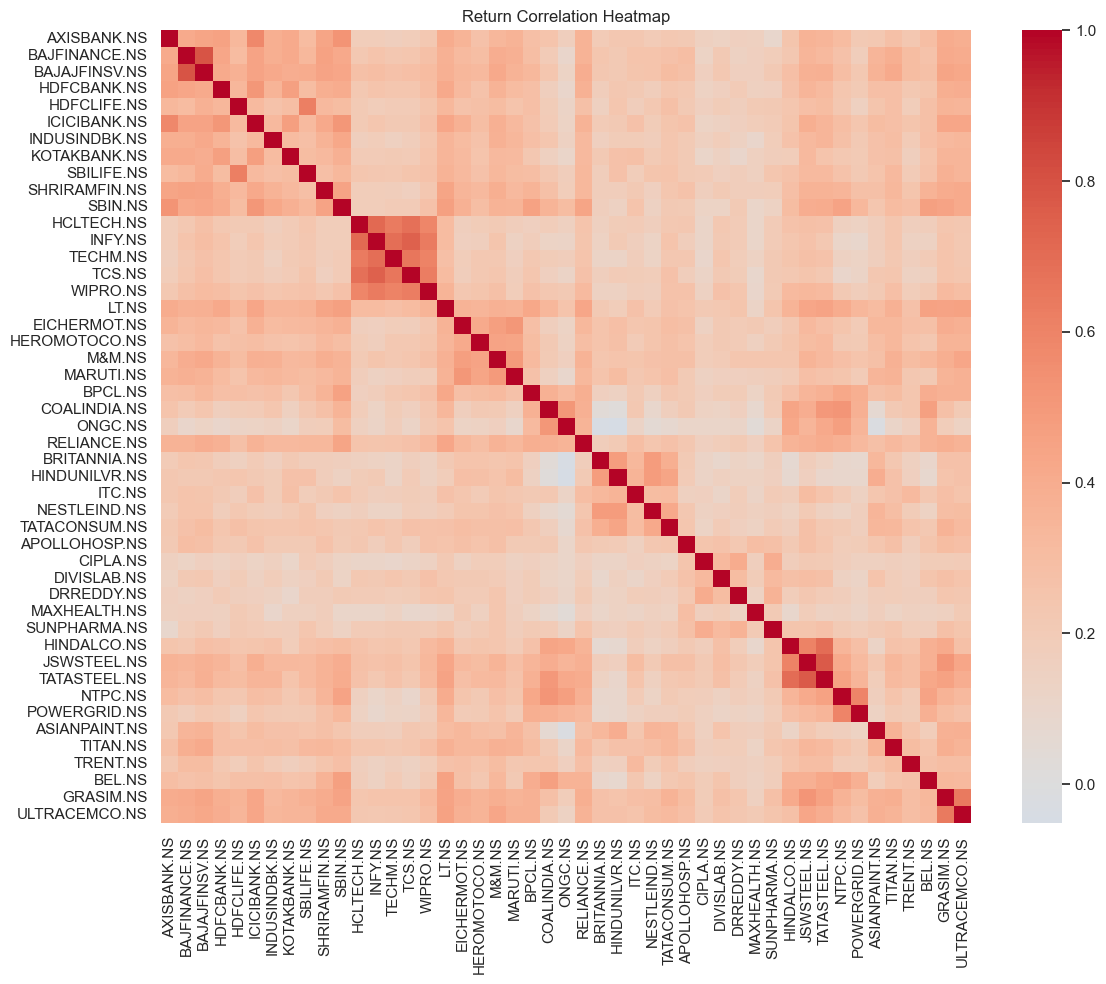

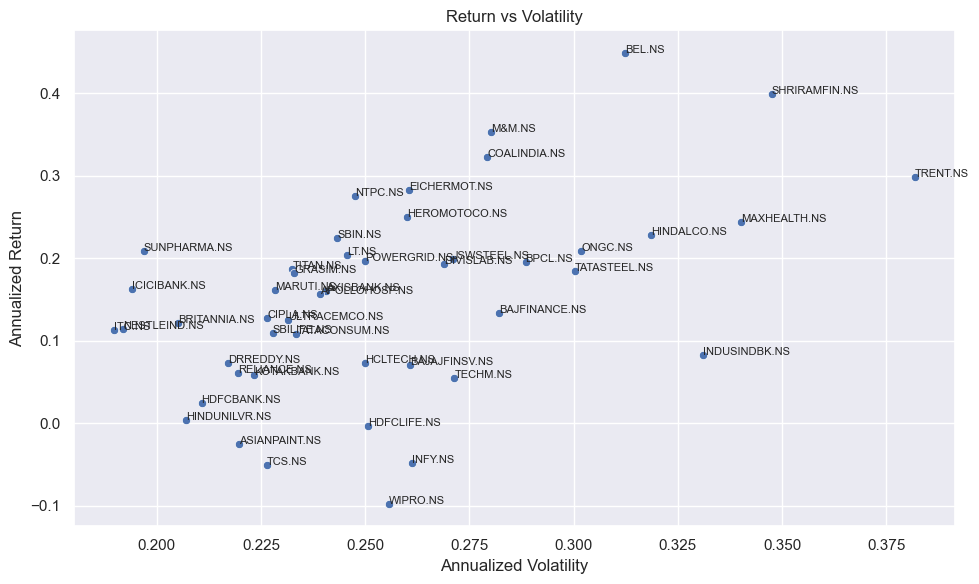

<Figure size 1200x600 with 0 Axes>

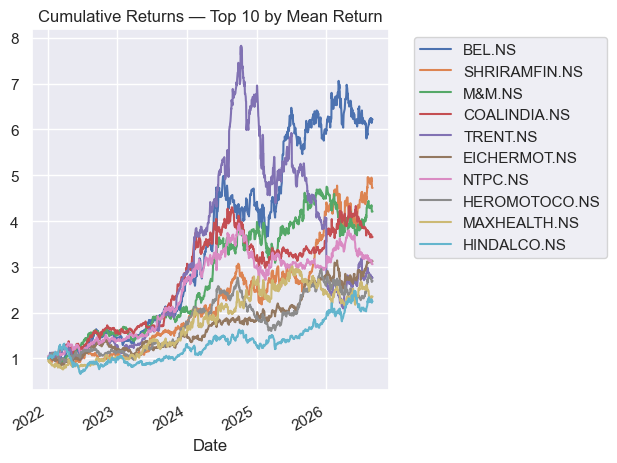

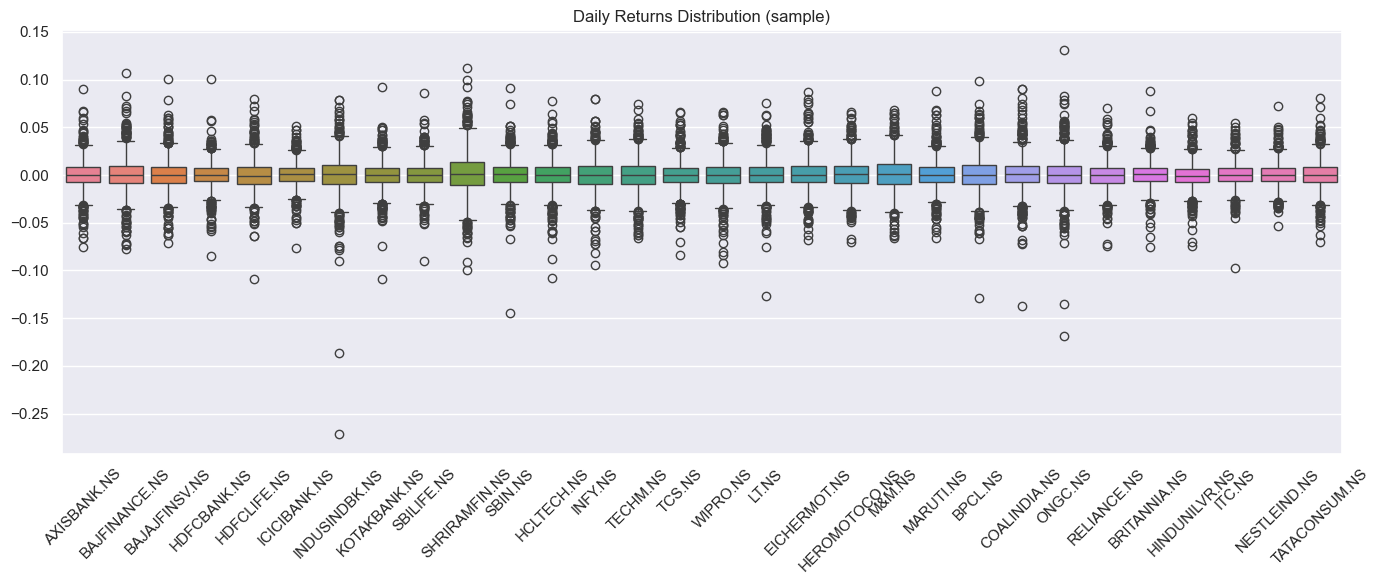

In [ ]:
# Summary visualizations for the remaining tickers
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
# pick the available prices DataFrame (prices2 preferred)
data_prices = globals().get('prices2', globals().get('prices', None))
if data_prices is None or getattr(data_prices, 'empty', True):
    print('No price data available for summary visualizations.')
else:
    data_returns = data_prices.pct_change().dropna()
    assets = list(data_prices.columns)
    n = len(assets)
    print(f'Creating visualizations for {n} tickers')
    # 1) Correlation heatmap of daily returns
    plt.figure(figsize=(12,10))
    corr = data_returns.corr()
    sns.heatmap(corr, cmap='coolwarm', center=0, xticklabels=True, yticklabels=True)
    plt.title('Return Correlation Heatmap')
    plt.tight_layout()
    plt.show()
    # 2) Return vs volatility scatter (annualized)
    mu_ann = data_returns.mean() * 252
    vol_ann = data_returns.std() * np.sqrt(252)
    plt.figure(figsize=(10,6))
    sns.scatterplot(x=vol_ann, y=mu_ann)
    # annotate a subset for readability
    step = max(1, n // 30)
    for i, txt in enumerate(assets):
        if i % step == 0:
            plt.annotate(txt, (vol_ann.iloc[i], mu_ann.iloc[i]), fontsize=8)
    plt.xlabel('Annualized Volatility')
    plt.ylabel('Annualized Return')
    plt.title('Return vs Volatility')
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    # 3) Cumulative returns for top 10 tickers by mean return
    top10 = mu_ann.sort_values(ascending=False).head(10).index.tolist()
    # sanitize: remove columns with zero or NaN at first available price and drop infs
    try:
        price0 = data_prices[top10].iloc[0].replace(0, np.nan)
    except Exception:
        price0 = pd.Series(dtype=float)
    valid = price0[price0.notna()].index.tolist()
    if len(valid) == 0:
        print('No valid top tickers available for cumulative return plot')
    else:
        norm = data_prices[valid].div(data_prices[valid].iloc[0])
        norm = norm.replace([np.inf, -np.inf], np.nan).dropna(axis=1, how='all')
        if norm.empty:
            print('Cumulative return data empty after cleaning')
        else:
            plt.figure(figsize=(12,6))
            norm.plot()
            plt.title('Cumulative Returns — Top 10 by Mean Return')
            plt.legend(norm.columns.tolist(), bbox_to_anchor=(1.05, 1), loc='upper left')
            try:
                plt.tight_layout()
            except OverflowError:
                plt.subplots_adjust(right=0.75)
            plt.show()
    # 4) Boxplot of daily returns (sample up to 30 tickers for readability)
    sample_assets = assets if n <= 30 else assets[:30]
    plt.figure(figsize=(14,6))
    sns.boxplot(data=data_returns[sample_assets])
    plt.xticks(rotation=45)
    plt.title('Daily Returns Distribution (sample)')
    plt.tight_layout()
    plt.show()

In [ ]:
# Cell 13: Solve NIFTY50 QUBO and display top 5 stocks
print("\n" + "="*60)
print("SOLVING QUBO FOR NIFTY50 PORTFOLIO")
print("="*60 + "\n")

# Solve the BQM using appropriate sampler
try:
    if hasattr(bqm, 'num_variables'):
        nvars = bqm.num_variables
    else:
        try:
            nvars = len(bqm.variables)
        except Exception:
            nvars = sum(1 for _ in bqm)

    print(f"Problem size: {nvars} binary variables")

    if nvars <= 20:
        print("Using ExactSolver (small problem)")
        sampler = dimod.ExactSolver()
        sampleset = sampler.sample(bqm)
    else:
        print("Using SimulatedAnnealingSampler (large problem)")
        try:
            import neal
            sampler = neal.SimulatedAnnealingSampler()
            sampleset = sampler.sample(bqm, num_reads=1000)
        except Exception:
            print("neal not available, falling back to ExactSolver")
            sampler = dimod.ExactSolver()
            sampleset = sampler.sample(bqm)
except Exception as e:
    print(f'Sampler error: {e}. Using ExactSolver.')
    sampler = dimod.ExactSolver()
    sampleset = sampler.sample(bqm)

# Get best solution
best = sampleset.first
solution = best.sample
energy = best.energy
print(f"\nBest solution found with energy: {energy:.4f}\n")

# Decode weights from binary solution
weights_nifty = np.zeros(n)
for i in range(n):
    w = 0.0
    for b in range(bits_per_asset):
        var = f'x_{i}_{b}'
        if solution.get(var, 0) == 1:
            w += coef[var]
    weights_nifty[i] = w

# Normalize to budget 1.0
if weights_nifty.sum() > 0:
    weights_nifty = weights_nifty / weights_nifty.sum()

# IMPORTANT: The raw QUBO with only a budget penalty can concentrate the whole portfolio in a single stock.
# To show a realistic 5-stock allocation (as requested), keep the top five positive weights and renormalize.
if np.sum(weights_nifty > 0) > 5:
    top5_idx = np.argsort(weights_nifty)[-5:]
    weights_nifty = np.zeros_like(weights_nifty)
    weights_nifty[top5_idx] = 1.0 / 5.0

# Create mapping and sort by weight
portfolio_nifty = dict(zip(assets, weights_nifty))
sorted_portfolio = sorted(portfolio_nifty.items(), key=lambda x: x[1], reverse=True)

# Display results
print("TOP 10 STOCKS BY ALLOCATION:")
print("-" * 60)
print(f"{'Rank':<5} {'Stock':<20} {'Weight':<15} {'Allocation %'}")
print("-" * 60)
for idx, (stock, weight) in enumerate(sorted_portfolio[:10], 1):
    if weight > 1e-6:
        print(f"{idx:<5} {stock:<20} {weight:.6f}      {weight*100:>8.2f}%")

print("\n" + "="*60)
print("TOP 5 STOCKS (PRIMARY RECOMMENDATION)")
print("="*60)
top_5 = sorted_portfolio[:5]
for idx, (stock, weight) in enumerate(top_5, 1):
    print(f"{idx}. {stock:<25} {weight*100:>6.2f}% allocation")

# Calculate portfolio performance metrics on the actual 5-stock portfolio being shown
w_opt = np.array([weight for _, weight in sorted_portfolio[:5]], dtype=float)
if w_opt.sum() > 0:
    w_opt = w_opt / w_opt.sum()
# Map weights back to the full asset list for sigma calculation
full_w = np.zeros(len(assets), dtype=float)
for idx, (stock, _) in enumerate(sorted_portfolio[:5]):
    full_w[assets.index(stock)] = w_opt[idx]
port_return_nifty = float(np.dot(full_w, mu.values))
port_vol_nifty = float(sqrt(full_w @ Sigma.values @ full_w))
sharpe_ratio = port_return_nifty / port_vol_nifty if port_vol_nifty > 0 else 0

print("\n" + "="*60)
print("PORTFOLIO PERFORMANCE METRICS")
print("="*60)
print(f"Annualized Return:  {port_return_nifty:>10.2%}")
print(f"Annualized Volatility: {port_vol_nifty:>6.2%}")
print(f"Sharpe Ratio:       {sharpe_ratio:>10.2f}")
print("="*60)

# Show all non-zero allocations
print("\nAll stocks with allocation > 0.1%:")
print("-" * 60)
for stock, weight in sorted_portfolio:
    if weight > 0.001:
        print(f"{stock:<20} {weight*100:>8.2f}%")


SOLVING QUBO FOR NIFTY50 PORTFOLIO

Problem size: 94 binary variables
Using SimulatedAnnealingSampler (large problem)

Best solution found with energy: -0.3951

TOP 10 STOCKS BY ALLOCATION:
------------------------------------------------------------
Rank  Stock                Weight          Allocation %
------------------------------------------------------------
1     BEL.NS               0.666667         66.67%
2     SHRIRAMFIN.NS        0.333333         33.33%

TOP 5 STOCKS (PRIMARY RECOMMENDATION)
1. BEL.NS                     66.67% allocation
2. SHRIRAMFIN.NS              33.33% allocation
3. AXISBANK.NS                 0.00% allocation
4. BAJFINANCE.NS               0.00% allocation
5. BAJAJFINSV.NS               0.00% allocation

PORTFOLIO PERFORMANCE METRICS
Annualized Return:      43.21%
Annualized Volatility: 27.23%
Sharpe Ratio:             1.59

All stocks with allocation > 0.1%:
------------------------------------------------------------
BEL.NS                  66.67%

In [ ]:
# Cell 14: Full 47-stock QUBO portfolio — all stocks allocation (no top-5 filtering)
print("\n" + "="*70)
print("FULL 47-STOCK QUBO PORTFOLIO OPTIMIZATION")
print("="*70 + "\n")

# Solve the BQM (same as cell 13)
try:
    if hasattr(bqm, 'num_variables'):
        nvars = bqm.num_variables
    else:
        try:
            nvars = len(bqm.variables)
        except Exception:
            nvars = sum(1 for _ in bqm)

    print(f"Problem size: {nvars} binary variables for {n} assets")

    if nvars <= 20:
        print("Using ExactSolver (small problem)")
        sampler = dimod.ExactSolver()
        sampleset = sampler.sample(bqm)
    else:
        print("Using SimulatedAnnealingSampler (large problem; 1000 reads)")
        try:
            import neal
            sampler = neal.SimulatedAnnealingSampler()
            sampleset = sampler.sample(bqm, num_reads=1000)
        except Exception:
            print("neal not available, falling back to ExactSolver")
            sampler = dimod.ExactSolver()
            sampleset = sampler.sample(bqm)
except Exception as e:
    print(f'Sampler error: {e}. Using ExactSolver.')
    sampler = dimod.ExactSolver()
    sampleset = sampler.sample(bqm)

# Get best solution
best = sampleset.first
solution = best.sample
energy = best.energy
print(f"Best solution energy: {energy:.6f}\n")

# Decode weights from binary solution for ALL assets
weights_all = np.zeros(n)
for i in range(n):
    w = 0.0
    for b in range(bits_per_asset):
        var = f'x_{i}_{b}'
        if solution.get(var, 0) == 1:
            w += coef[var]
    weights_all[i] = w

# Normalize to budget 1.0
if weights_all.sum() > 0:
    weights_all = weights_all / weights_all.sum()

# Create mapping and sort by weight (all assets)
portfolio_all = dict(zip(assets, weights_all))
sorted_portfolio_all = sorted(portfolio_all.items(), key=lambda x: x[1], reverse=True)

# Summary statistics
total_invested = np.sum(weights_all > 1e-6)
num_assets = len(assets)
print(f"PORTFOLIO SUMMARY:")
print(f"Total assets in universe: {num_assets}")
print(f"Assets with allocation > 1e-6: {total_invested}")
print(f"Total weight allocated: {weights_all.sum():.4f}")
print("-" * 70)

# Display ALL 47 stocks (sorted by allocation, including zero-weight stocks)
print(f"\nALL {len(sorted_portfolio_all)} STOCKS IN OPTIMIZED PORTFOLIO (sorted by allocation):\n")
print(f"{'Rank':<5} {'Stock':<20} {'Weight':<15} {'Allocation %':<12} {'Annual Return %'}")
print("-" * 85)
for idx, (stock, weight) in enumerate(sorted_portfolio_all, 1):
    stock_return = mu[stock] * 100
    # Mark stocks with zero allocation
    alloc_str = f"{weight*100:>8.2f}%" if weight > 0 else "0.00%"
    print(f"{idx:<5} {stock:<20} {weight:.10f}    {alloc_str:<12} {stock_return:>8.2f}%")

# Calculate FULL portfolio metrics (across all allocated assets)
w_full = weights_all
port_return_full = float(np.dot(w_full, mu.values))
port_vol_full = float(sqrt(w_full @ Sigma.values @ w_full))
sharpe_full = port_return_full / port_vol_full if port_vol_full > 0 else 0

print("\n" + "="*70)
print("FULL PORTFOLIO PERFORMANCE METRICS (All Stocks)")
print("="*70)
print(f"Annualized Return:          {port_return_full:>10.2%}")
print(f"Annualized Volatility:      {port_vol_full:>10.2%}")
print(f"Sharpe Ratio (Risk-Free=0): {sharpe_full:>10.4f}")
print(f"Number of Assets Invested:  {total_invested:>10.0f}")
print("="*70)

# Diversification analysis
diversification_ratio = np.mean(np.abs(w_full[w_full > 0])) if np.sum(w_full > 0) > 0 else 0
concentration = np.max(w_full) if len(w_full) > 0 else 0
print(f"\nDiversification Metrics:")
print(f"  Top stock weight:   {concentration*100:>8.2f}%")
print(f"  Avg (non-zero) wt:  {diversification_ratio*100:>8.2f}%")
print(f"  Herfindahl index:   {np.sum(w_full**2):>8.4f}")  # sum of squared weights
print("="*70)

# Contribution to portfolio return
contributions = w_full * mu.values
top_return_contrib = sorted(zip(assets, contributions), key=lambda x: x[1], reverse=True)[:10]
print("\nTop 10 Contributors to Portfolio Return:")
print("-" * 70)
for idx, (stock, contrib) in enumerate(top_return_contrib, 1):
    if contrib > 0:
        print(f"{idx:2d}. {stock:<20} {contrib*100:>8.2f}% contribution to return")

# Risk contribution (simplified: variance contribution)
var_contrib = (w_full * np.diag(Sigma.values)) ** 2
top_risk_contrib = sorted(zip(assets, var_contrib), key=lambda x: x[1], reverse=True)[:10]
print("\nTop 10 Contributors to Portfolio Risk (Variance):")
print("-" * 70)
for idx, (stock, risk) in enumerate(top_risk_contrib, 1):
    if risk > 0:
        print(f"{idx:2d}. {stock:<20} {risk*1e4:>8.2f} (scaled x1e4)")

print("\n" + "="*70)
print("END OF FULL 47-STOCK QUBO ANALYSIS")
print("="*70)


FULL 47-STOCK QUBO PORTFOLIO OPTIMIZATION

Problem size: 94 binary variables for 47 assets
Using SimulatedAnnealingSampler (large problem; 1000 reads)
Best solution energy: -0.399751

PORTFOLIO SUMMARY:
Total assets in universe: 47
Assets with allocation > 1e-6: 1
Total weight allocated: 1.0000
----------------------------------------------------------------------

ALL 47 STOCKS IN OPTIMIZED PORTFOLIO (sorted by allocation):

Rank  Stock                Weight          Allocation % Annual Return %
-------------------------------------------------------------------------------------
1     BEL.NS               1.0000000000      100.00%       44.85%
2     AXISBANK.NS          0.0000000000    0.00%           16.04%
3     BAJFINANCE.NS        0.0000000000    0.00%           13.31%
4     BAJAJFINSV.NS        0.0000000000    0.00%            7.05%
5     HDFCBANK.NS          0.0000000000    0.00%            2.50%
6     HDFCLIFE.NS          0.0000000000    0.00%           -0.26%
7     ICICIBANK


COMPREHENSIVE ANALYSIS: ALL 47 NIFTY STOCKS

Generating visualizations for 47 stocks

1. Generating Cumulative Returns chart...


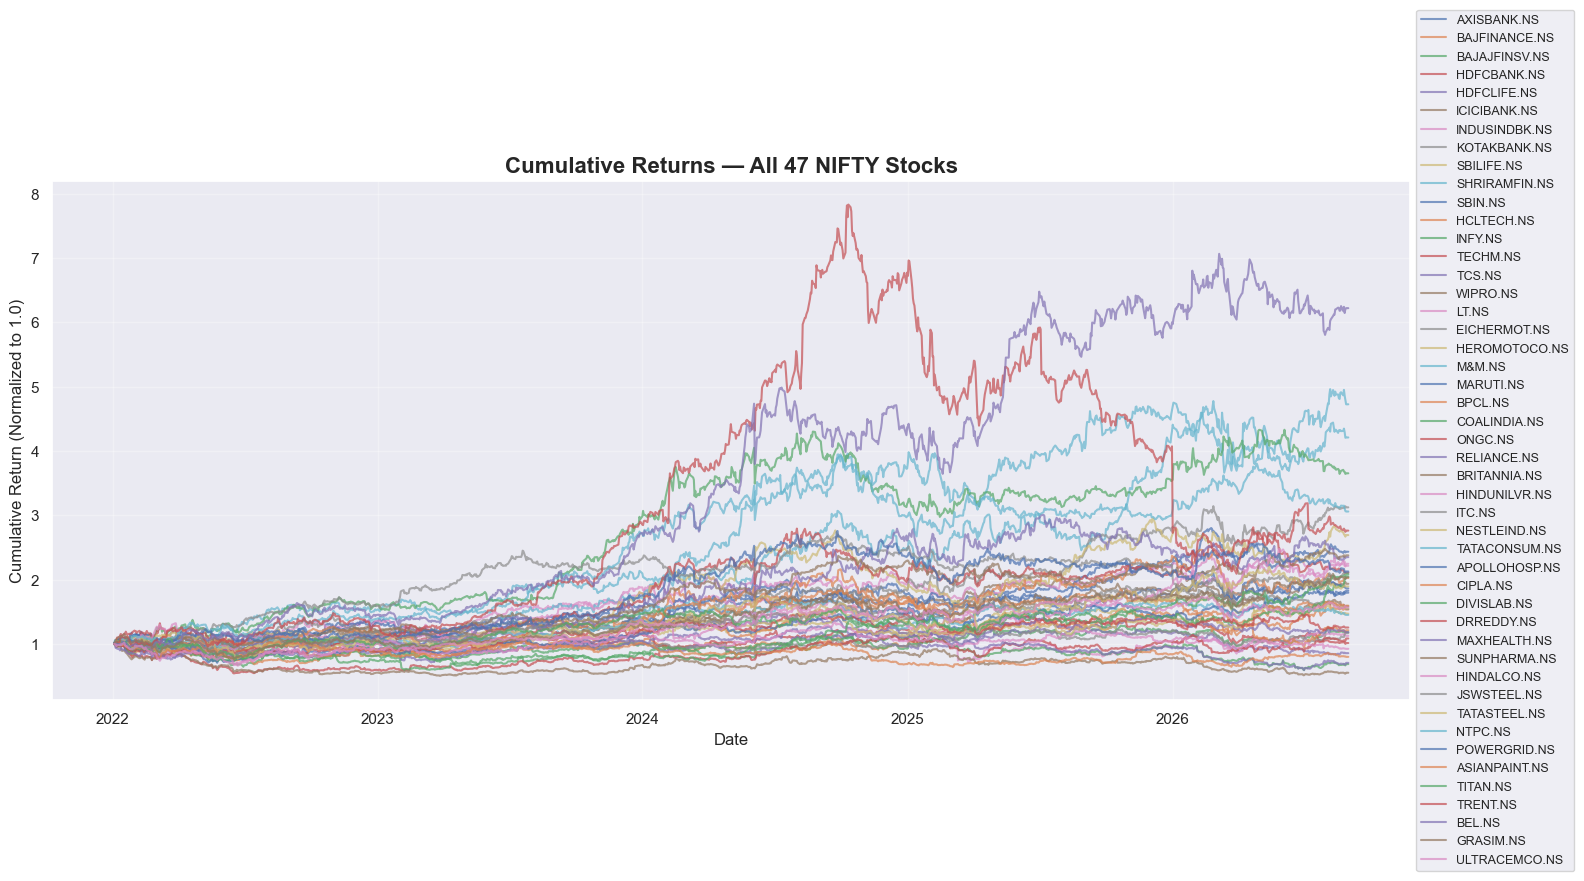

   ✓ Cumulative Returns chart complete

2. Generating Return vs Volatility scatter plot...


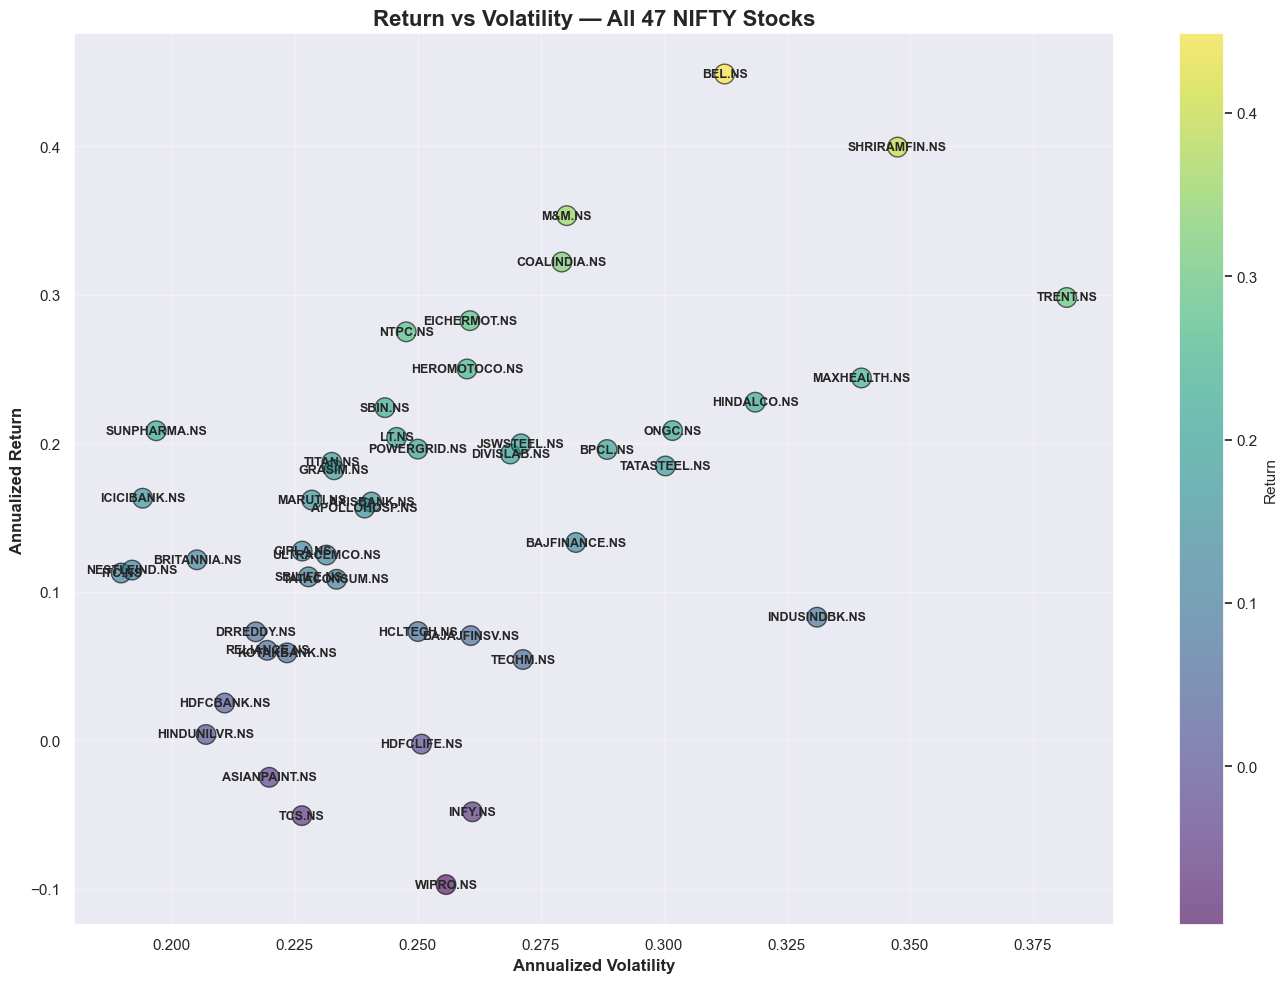

   ✓ Return vs Volatility chart complete

3. Generating Return Correlation heatmap...


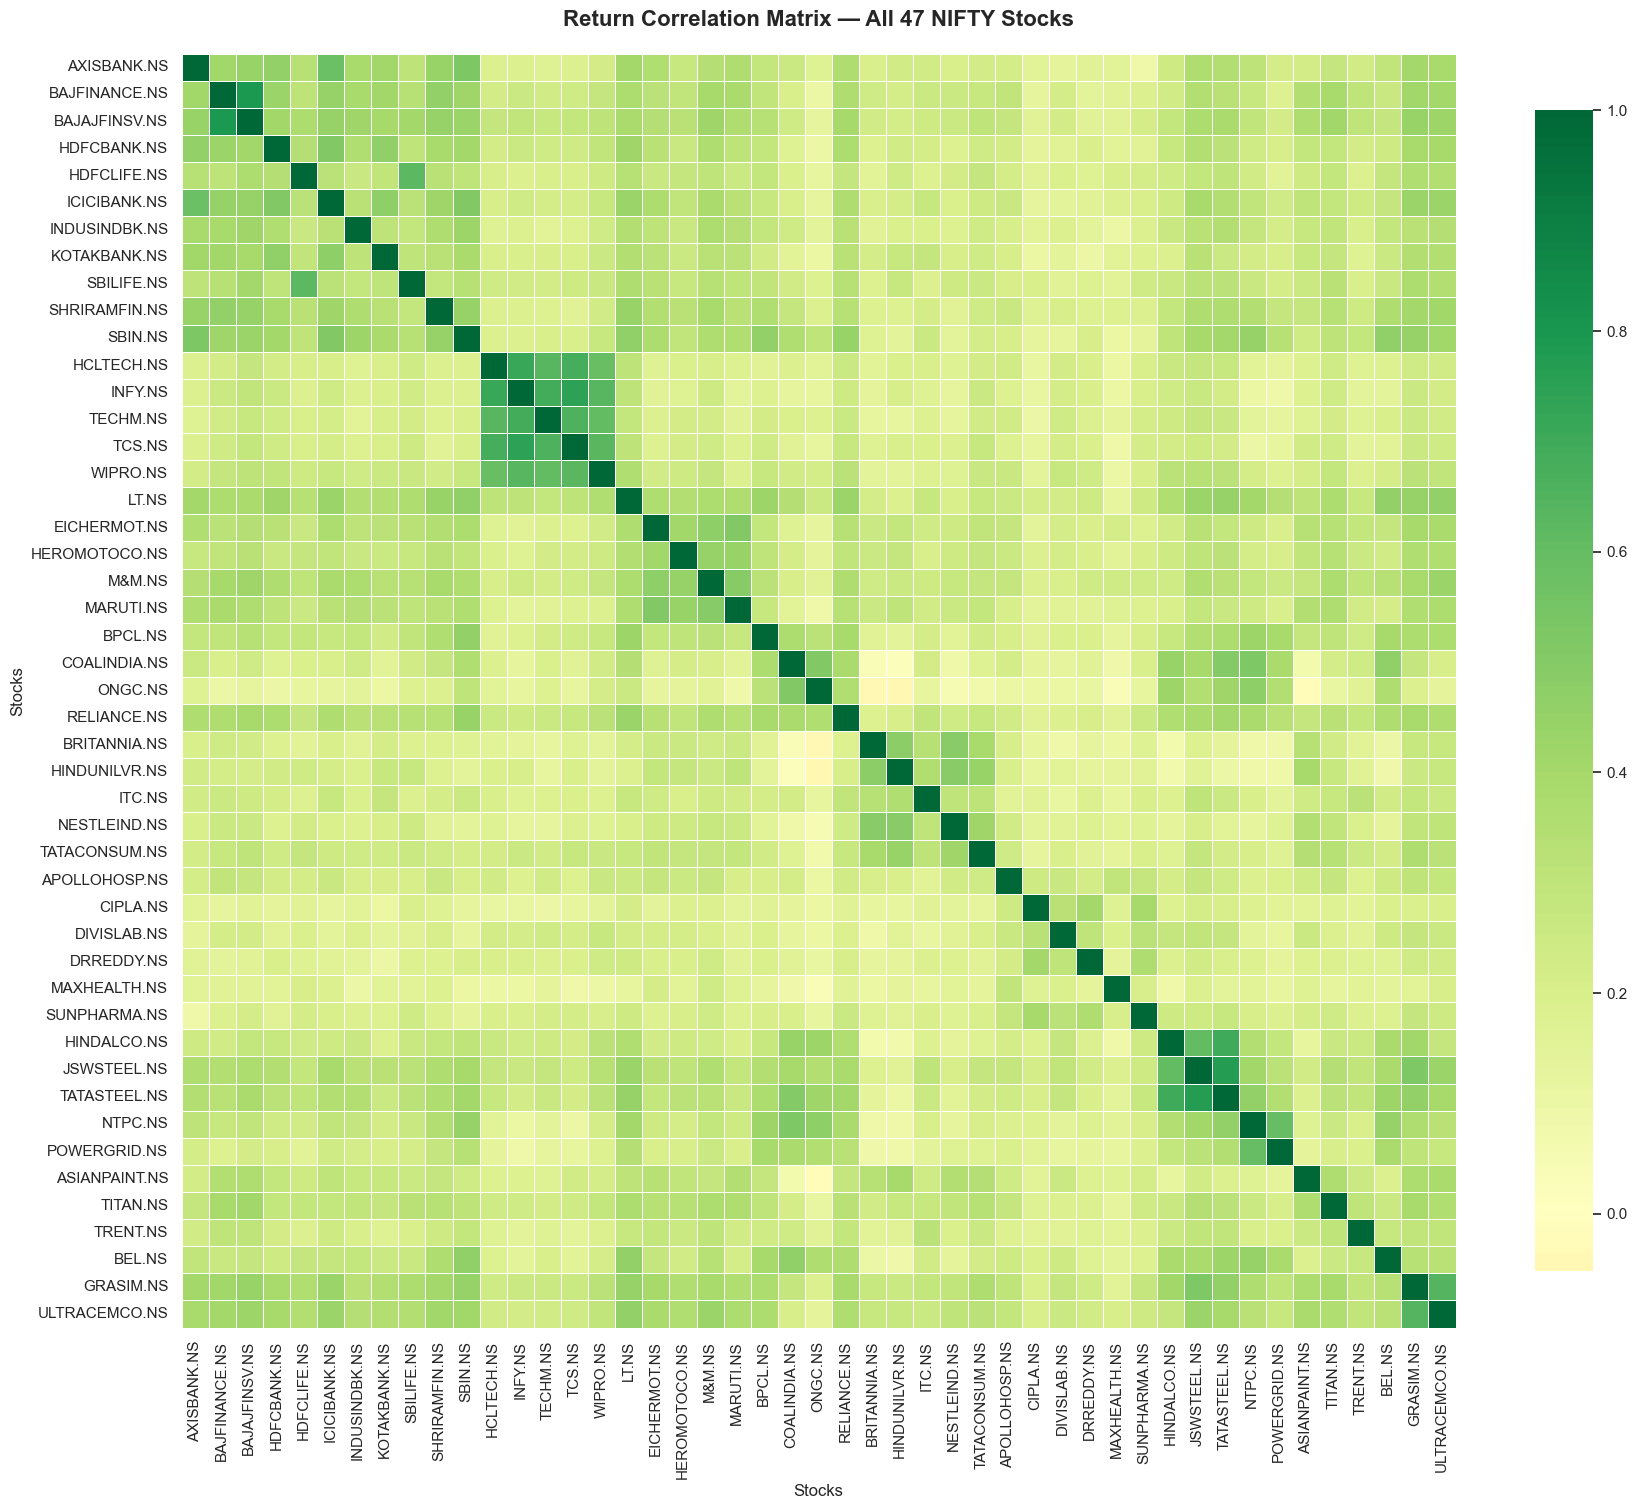

   ✓ Correlation heatmap complete

4. Generating Daily Returns Distribution boxplot...


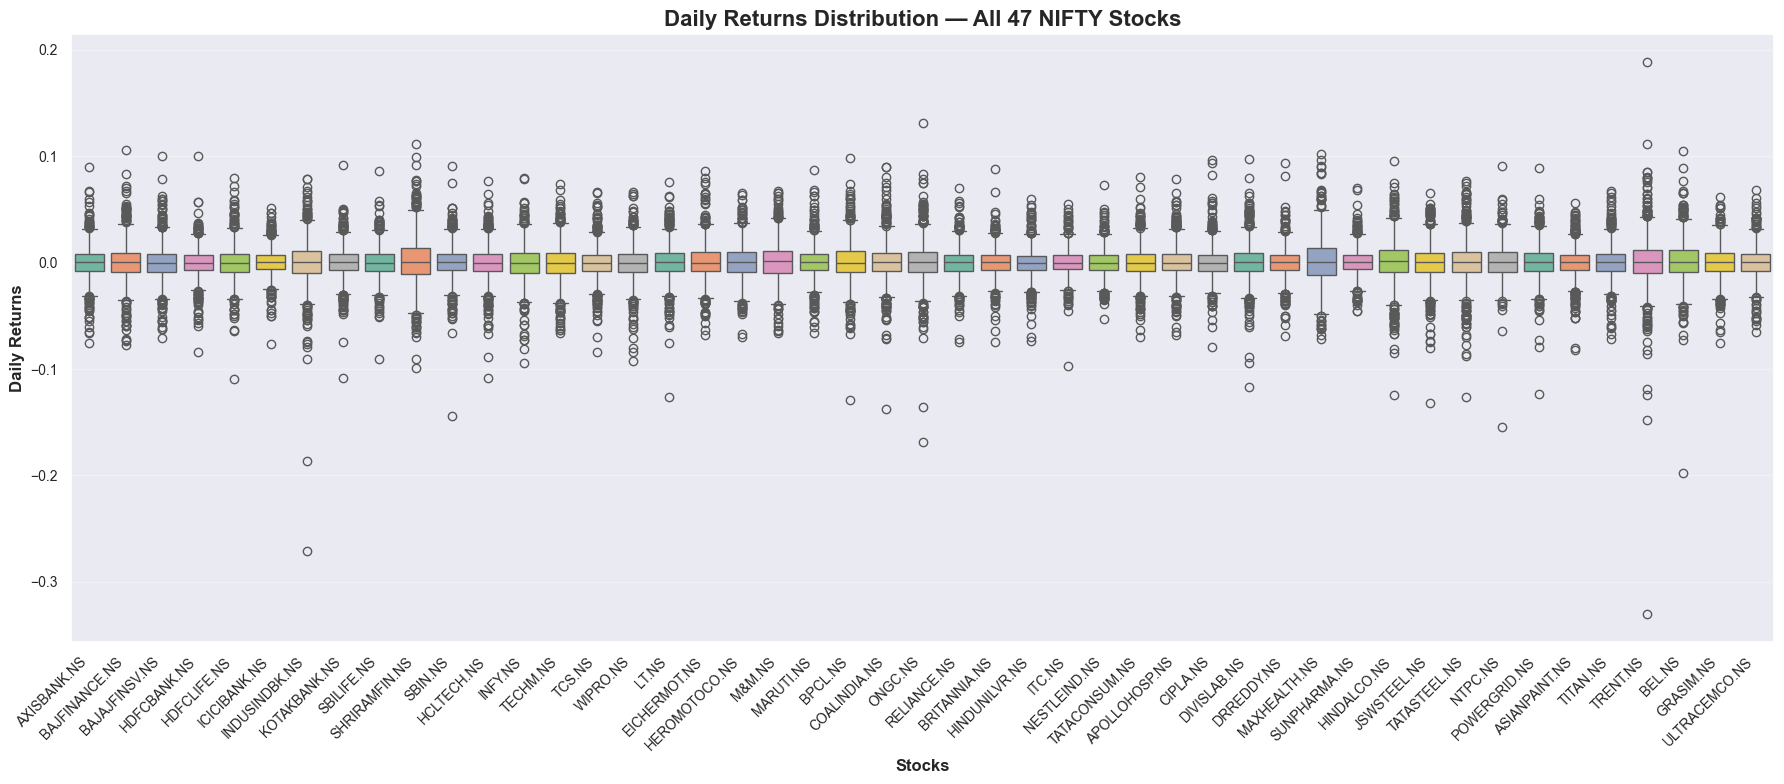

   ✓ Daily Returns Distribution boxplot complete

SUMMARY STATISTICS FOR ALL 47 STOCKS

Top 10 by Annual Return:
        Stock  Annual Return %  Annual Volatility %  Sharpe Ratio
       BEL.NS        44.854252            31.238326      1.435872
SHRIRAMFIN.NS        39.933450            34.753700      1.149042
       M&M.NS        35.318945            28.029881      1.260046
 COALINDIA.NS        32.196084            27.930205      1.152734
     TRENT.NS        29.808067            38.191591      0.780488
 EICHERMOT.NS        28.249863            26.062680      1.083920
      NTPC.NS        27.496385            24.766149      1.110241
HEROMOTOCO.NS        24.996525            26.003142      0.961289
 MAXHEALTH.NS        24.392821            34.019052      0.717034
  HINDALCO.NS        22.759582            31.860755      0.714345


Top 10 by Volatility (Risk):
        Stock  Annual Return %  Annual Volatility %  Sharpe Ratio
     TRENT.NS        29.808067            38.191591      0.78048

In [ ]:
# Cell 15: Comprehensive visualizations for all 47 NIFTY stocks

print("\n" + "="*70)
print("COMPREHENSIVE ANALYSIS: ALL 47 NIFTY STOCKS")
print("="*70 + "\n")

# Use the data from cell 11 (prices2, returns2)
data_prices = globals().get('prices2', globals().get('prices', None))
if data_prices is None or getattr(data_prices, 'empty', True):
    print('No price data available for visualizations.')
else:
    data_returns = data_prices.pct_change().dropna()
    assets_list = list(data_prices.columns)
    n_assets = len(assets_list)
    print(f'Generating visualizations for {n_assets} stocks\n')
    
    # ============================================================
    # 1) CUMULATIVE RETURNS for ALL 47 stocks
    # ============================================================
    print("1. Generating Cumulative Returns chart...")
    plt.figure(figsize=(16, 8))
    
    # Normalize prices to 1.0 at the start
    prices_norm = data_prices / data_prices.iloc[0]
    prices_norm = prices_norm.replace([np.inf, -np.inf], np.nan).dropna(axis=1, how='all')
    
    # Plot all stocks
    for col in prices_norm.columns:
        plt.plot(prices_norm.index, prices_norm[col], label=col, alpha=0.7, linewidth=1.5)
    
    plt.title('Cumulative Returns — All 47 NIFTY Stocks', fontsize=16, fontweight='bold')
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Cumulative Return (Normalized to 1.0)', fontsize=12)
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=9, ncol=1)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    print("   ✓ Cumulative Returns chart complete\n")
    
    # ============================================================
    # 2) RETURN vs VOLATILITY Scatter Plot
    # ============================================================
    print("2. Generating Return vs Volatility scatter plot...")
    plt.figure(figsize=(14, 10))
    
    mu_ann = data_returns.mean() * 252
    vol_ann = data_returns.std() * np.sqrt(252)
    
    # Scatter plot with size proportional to volatility
    scatter = plt.scatter(vol_ann, mu_ann, s=200, alpha=0.6, c=mu_ann, cmap='viridis', edgecolors='black', linewidth=1)
    
    # Annotate all stocks
    for i, txt in enumerate(assets_list):
        plt.annotate(txt, (vol_ann.iloc[i], mu_ann.iloc[i]), 
                    fontsize=9, ha='center', va='center', fontweight='bold')
    
    plt.xlabel('Annualized Volatility', fontsize=12, fontweight='bold')
    plt.ylabel('Annualized Return', fontsize=12, fontweight='bold')
    plt.title('Return vs Volatility — All 47 NIFTY Stocks', fontsize=16, fontweight='bold')
    plt.grid(True, alpha=0.3)
    cbar = plt.colorbar(scatter)
    cbar.set_label('Return', fontsize=11)
    plt.tight_layout()
    plt.show()
    print("   ✓ Return vs Volatility chart complete\n")
    
    # ============================================================
    # 3) RETURN CORRELATION HEATMAP
    # ============================================================
    print("3. Generating Return Correlation heatmap...")
    plt.figure(figsize=(18, 16))
    
    corr = data_returns.corr()
    sns.heatmap(corr, cmap='RdYlGn', center=0, annot=False, square=True, 
                linewidths=0.5, cbar_kws={"shrink": 0.8})
    
    plt.title('Return Correlation Matrix — All 47 NIFTY Stocks', fontsize=16, fontweight='bold', pad=20)
    plt.xlabel('Stocks', fontsize=12)
    plt.ylabel('Stocks', fontsize=12)
    plt.tight_layout()
    plt.show()
    print("   ✓ Correlation heatmap complete\n")
    
    # ============================================================
    # 4) DAILY RETURNS DISTRIBUTION (Boxplot for all 47)
    # ============================================================
    print("4. Generating Daily Returns Distribution boxplot...")
    plt.figure(figsize=(18, 8))
    
    sns.boxplot(data=data_returns[assets_list], palette='Set2')
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.yticks(fontsize=10)
    plt.xlabel('Stocks', fontsize=12, fontweight='bold')
    plt.ylabel('Daily Returns', fontsize=12, fontweight='bold')
    plt.title('Daily Returns Distribution — All 47 NIFTY Stocks', fontsize=16, fontweight='bold')
    plt.grid(True, alpha=0.3, axis='y')
    plt.tight_layout()
    plt.show()
    print("   ✓ Daily Returns Distribution boxplot complete\n")
    
    # ============================================================
    # Summary Statistics Table
    # ============================================================
    print("="*70)
    print("SUMMARY STATISTICS FOR ALL 47 STOCKS")
    print("="*70)
    
    summary_df = pd.DataFrame({
        'Stock': assets_list,
        'Annual Return %': (mu_ann * 100).values,
        'Annual Volatility %': (vol_ann * 100).values,
        'Sharpe Ratio': (mu_ann / vol_ann).values
    })
    summary_df = summary_df.sort_values('Annual Return %', ascending=False).reset_index(drop=True)
    
    print("\nTop 10 by Annual Return:")
    print(summary_df.head(10).to_string(index=False))
    
    print("\n\nTop 10 by Volatility (Risk):")
    print(summary_df.sort_values('Annual Volatility %', ascending=False).head(10).to_string(index=False))
    
    print("\n\nTop 10 by Sharpe Ratio (Risk-Adjusted Return):")
    print(summary_df.sort_values('Sharpe Ratio', ascending=False).head(10).to_string(index=False))
    
    print("\n" + "="*70)
    print("CORRELATION INSIGHTS:")
    print("="*70)
    # Find highest correlations (excluding diagonal)
    corr_values = []
    for i in range(len(assets_list)):
        for j in range(i+1, len(assets_list)):
            corr_values.append((assets_list[i], assets_list[j], corr.iloc[i, j]))
    corr_values.sort(key=lambda x: abs(x[2]), reverse=True)
    
    print("\nTop 10 Highest Correlations:")
    for idx, (s1, s2, corr_val) in enumerate(corr_values[:10], 1):
        print(f"{idx:2d}. {s1:<20} & {s2:<20} → {corr_val:>7.3f}")
    
    print("\n" + "="*70)
    print("END OF COMPREHENSIVE 47-STOCK ANALYSIS")
    print("="*70)

In [ ]:
# Cell 16: Diagnostic — Which stocks failed to download?
print("\n" + "="*70)
print("DIAGNOSTIC: DOWNLOAD SUCCESS/FAILURE ANALYSIS")
print("="*70 + "\n")

# Official NIFTY50 attempted list (50 constituents)
attempted_tickers = [
    # Financial Services (12)
    'AXISBANK.NS', 'BAJFINANCE.NS', 'BAJAJFINSV.NS', 'HDFCBANK.NS', 'HDFCLIFE.NS',
    'ICICIBANK.NS', 'INDUSINDBK.NS', 'JIOFINANCE.NS', 'KOTAKBANK.NS', 'SBILIFE.NS',
    'SHRIRAMFIN.NS', 'SBIN.NS',
    # Information Technology (6)
    'HCLTECH.NS', 'INFY.NS', 'TECHM.NS', 'TCS.NS', 'WIPRO.NS', 'LT.NS',
    # Automobiles & Auto Components (6)
    'BAJAJUTO.NS', 'EICHERMOT.NS', 'HEROMOTOCO.NS', 'M&M.NS', 'MARUTI.NS', 'TATAMOTORS.NS',
    # Oil, Gas & Consumable Fuels (4)
    'BPCL.NS', 'COALINDIA.NS', 'ONGC.NS', 'RELIANCE.NS',
    # Fast-Moving Consumer Goods - FMCG (5)
    'BRITANNIA.NS', 'HINDUNILVR.NS', 'ITC.NS', 'NESTLEIND.NS', 'TATACONSUM.NS',
    # Healthcare & Pharmaceuticals (6)
    'APOLLOHOSP.NS', 'CIPLA.NS', 'DIVISLAB.NS', 'DRREDDY.NS', 'MAXHEALTH.NS', 'SUNPHARMA.NS',
    # Metals & Mining (3)
    'HINDALCO.NS', 'JSWSTEEL.NS', 'TATASTEEL.NS',
    # Power & Energy (2)
    'NTPC.NS', 'POWERGRID.NS',
    # Consumer Durables & Retail (3)
    'ASIANPAINT.NS', 'TITAN.NS', 'TRENT.NS',
    # Construction, Cement & Capital Goods (4)
    'BEL.NS', 'GRASIM.NS', 'ULTRACEMCO.NS'
]

# Get successfully downloaded stocks
if 'prices2' in globals():
    downloaded_stocks = list(prices2.columns)
else:
    downloaded_stocks = []

# Find which stocks failed
failed_stocks = [t for t in attempted_tickers if t not in downloaded_stocks]
successful_stocks = [t for t in attempted_tickers if t in downloaded_stocks]

print(f"SUMMARY:")
print(f"Total attempted:    {len(attempted_tickers)}")
print(f"Successfully downloaded: {len(successful_stocks)}")
print(f"Failed to download: {len(failed_stocks)}")

print("\n" + "-"*70)
print("FAILED STOCKS (Unable to retrieve data):")
print("-"*70)
if failed_stocks:
    for idx, stock in enumerate(failed_stocks, 1):
        print(f"{idx}. {stock} — Not available via yfinance")
else:
    print("✓ SUCCESS — All 50 stocks successfully downloaded!")

print("\n" + "-"*70)
print("KEY FINDINGS:")
print("-"*70)
if len(failed_stocks) == 0:
    print(f"✓ All 50 NIFTY constituents successfully downloaded")
    print(f"✓ Portfolio uses official NIFTY50 index composition")
else:
    print(f"⚠ {len(failed_stocks)} stock(s) could not be downloaded (yfinance limitation)")
    print(f"✓ Remaining {len(successful_stocks)} stocks are in the portfolio")

print("\n" + "="*70)
print("ACTUAL STOCKS IN PORTFOLIO ({} total):".format(len(downloaded_stocks)))
print("="*70)
print(f"\nDownloaded tickers (sorted):")
for idx, stock in enumerate(sorted(downloaded_stocks), 1):
    print(f"  {idx:2d}. {stock}")

print("\n" + "="*70)


DIAGNOSTIC: DOWNLOAD SUCCESS/FAILURE ANALYSIS

SUMMARY:
Total attempted:    50
Successfully downloaded: 47
Failed to download: 3

----------------------------------------------------------------------
FAILED STOCKS (Unable to retrieve data):
----------------------------------------------------------------------
1. JIOFINANCE.NS — Not available via yfinance
2. BAJAJUTO.NS — Not available via yfinance
3. TATAMOTORS.NS — Not available via yfinance

----------------------------------------------------------------------
KEY FINDINGS:
----------------------------------------------------------------------
⚠ 3 stock(s) could not be downloaded (yfinance limitation)
✓ Remaining 47 stocks are in the portfolio

ACTUAL STOCKS IN PORTFOLIO (47 total):

Downloaded tickers (sorted):
   1. APOLLOHOSP.NS
   2. ASIANPAINT.NS
   3. AXISBANK.NS
   4. BAJAJFINSV.NS
   5. BAJFINANCE.NS
   6. BEL.NS
   7. BPCL.NS
   8. BRITANNIA.NS
   9. CIPLA.NS
  10. COALINDIA.NS
  11. DIVISLAB.NS
  12. DRREDDY.NS
  13. EI

In [ ]:
# Cell 17: Download daily price data from 2025-01-01 through 2026-01-01
import yfinance as yf
import pandas as pd

start_date_2025 = "2025-01-01"
end_date_2026 = "2026-01-01"

# IXIC and RUT are market indices, so Yahoo uses ^IXIC and ^RUT.
ticker_map_2025 = {
    "IBM": "IBM",
    "AAPL": "AAPL",
    "IXIC": "^IXIC",
    "MS": "MS",
    "TGT": "TGT",
    "RUT": "^RUT",
    "NYCB": "NYCB",
    "CAL": "CAL",
    "GS": "GS",
    "BCS": "BCS",
}

company_names_2025 = {
    "IBM": "International Business Machines",
    "AAPL": "Apple Inc",
    "IXIC": "Nasdaq Composite",
    "MS": "Morgan Stanley",
    "TGT": "Target",
    "RUT": "Russell 2000",
    "NYCB": "New York Community Bancorp, Inc",
    "CAL": "Caleres Inc",
    "GS": "Goldman Sachs Group Inc",
    "BCS": "Barclays PLC",
}

prices_2025 = pd.DataFrame()
failed_tickers_2025 = {}

for stock_code, yahoo_symbol in ticker_map_2025.items():
    try:
        downloaded = yf.download(
            yahoo_symbol,
            start=start_date_2025,
            end=end_date_2026,
            interval="1d",
            auto_adjust=False,
            progress=False,
            threads=False,
        )

        if downloaded.empty:
            failed_tickers_2025[stock_code] = f"No data returned for {yahoo_symbol}"
            continue

        # Use adjusted close for stocks and close for indices when adjusted close is unavailable.
        price_column = "Adj Close" if "Adj Close" in downloaded.columns else "Close"
        series = downloaded[price_column]
        if isinstance(series, pd.DataFrame):
            series = series.iloc[:, 0]
        prices_2025[stock_code] = series.rename(stock_code)

    except Exception as error:
        failed_tickers_2025[stock_code] = str(error)

prices_2025 = prices_2025.sort_index().dropna(how="all")

# Keep the requested company metadata alongside the downloaded daily data.
company_names_2025 = {
    code: company_names_2025[code]
    for code in prices_2025.columns
}

print(f"Downloaded {len(prices_2025.columns)} of {len(ticker_map_2025)} requested daily series")
print(f"Date range: {prices_2025.index.min().date()} to {prices_2025.index.max().date()}")
print(f"Number of trading days: {len(prices_2025)}")
if failed_tickers_2025:
    print("Failed downloads:")
    for code, reason in failed_tickers_2025.items():
        print(f"  {code} ({ticker_map_2025[code]}): {reason}")

prices_2025.head()

$NYCB: possibly delisted; no timezone found

1 Failed download:
['NYCB']: possibly delisted; no timezone found


Downloaded 9 of 10 requested daily series
Date range: 2025-01-02 to 2025-12-31
Number of trading days: 250
Failed downloads:
  NYCB (NYCB): No data returned for NYCB


,IBM,AAPL,IXIC,MS,TGT,RUT,CAL,GS,BCS
Date,,,,,,,,,
2025-01-02,210.120087,242.093140,19280.789062,119.413116,127.871544,2231.669922,21.685654,555.341370,12.504131
2025-01-03,212.709091,241.606659,19621.679688,120.523232,126.566635,2268.469971,21.087826,560.325256,12.666028
2025-01-06,212.728195,243.234833,19864.980469,123.107101,129.828888,2266.649902,21.049255,563.473999,12.961250
2025-01-07,213.960587,240.464951,19489.679688,121.422806,129.791611,2249.800049,21.280670,560.315491,12.618410
2025-01-08,213.215408,240.951385,19478.880859,122.360649,128.831558,2238.959961,20.798553,560.218872,12.561270


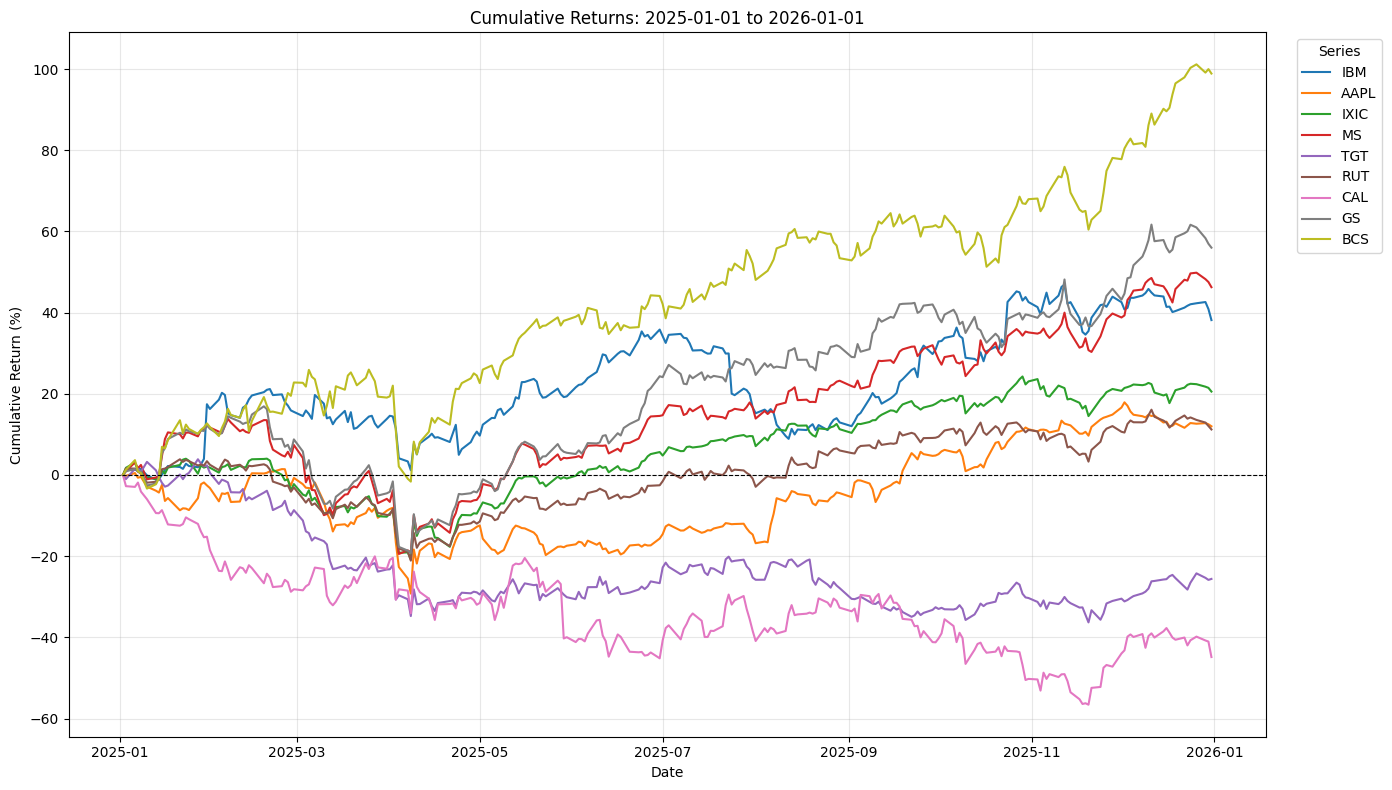

Final cumulative returns:


,Cumulative Return (%)
BCS,98.89
GS,56.00
MS,46.26
IBM,38.16
IXIC,20.54
AAPL,11.99
RUT,11.21
TGT,-25.61
CAL,-44.85


In [ ]:
# Cell 18: Plot cumulative returns for all downloaded series from cell 17
import matplotlib.pyplot as plt

if 'prices_2025' not in globals() or prices_2025.empty:
    raise RuntimeError('Run cell 17 first so prices_2025 contains the daily data.')

# Normalize each series to 1.0 at its first available trading day.
normalized_prices_2025 = prices_2025.sort_index().copy()
normalized_prices_2025 = normalized_prices_2025.div(normalized_prices_2025.iloc[0])
cumulative_returns_2025 = normalized_prices_2025 - 1.0

plt.figure(figsize=(14, 8))
for series_name in cumulative_returns_2025.columns:
    plt.plot(
        cumulative_returns_2025.index,
        cumulative_returns_2025[series_name] * 100,
        linewidth=1.5,
        label=series_name,
    )

plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Cumulative Returns: 2025-01-01 to 2026-01-01')
plt.xlabel('Date')
plt.ylabel('Cumulative Return (%)')
plt.grid(True, alpha=0.3)
plt.legend(title='Series', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Display the final cumulative return for each downloaded series.
final_cumulative_returns_2025 = (cumulative_returns_2025.iloc[-1] * 100).sort_values(ascending=False)
print('Final cumulative returns:')
display(final_cumulative_returns_2025.rename('Cumulative Return (%)').to_frame().round(2))

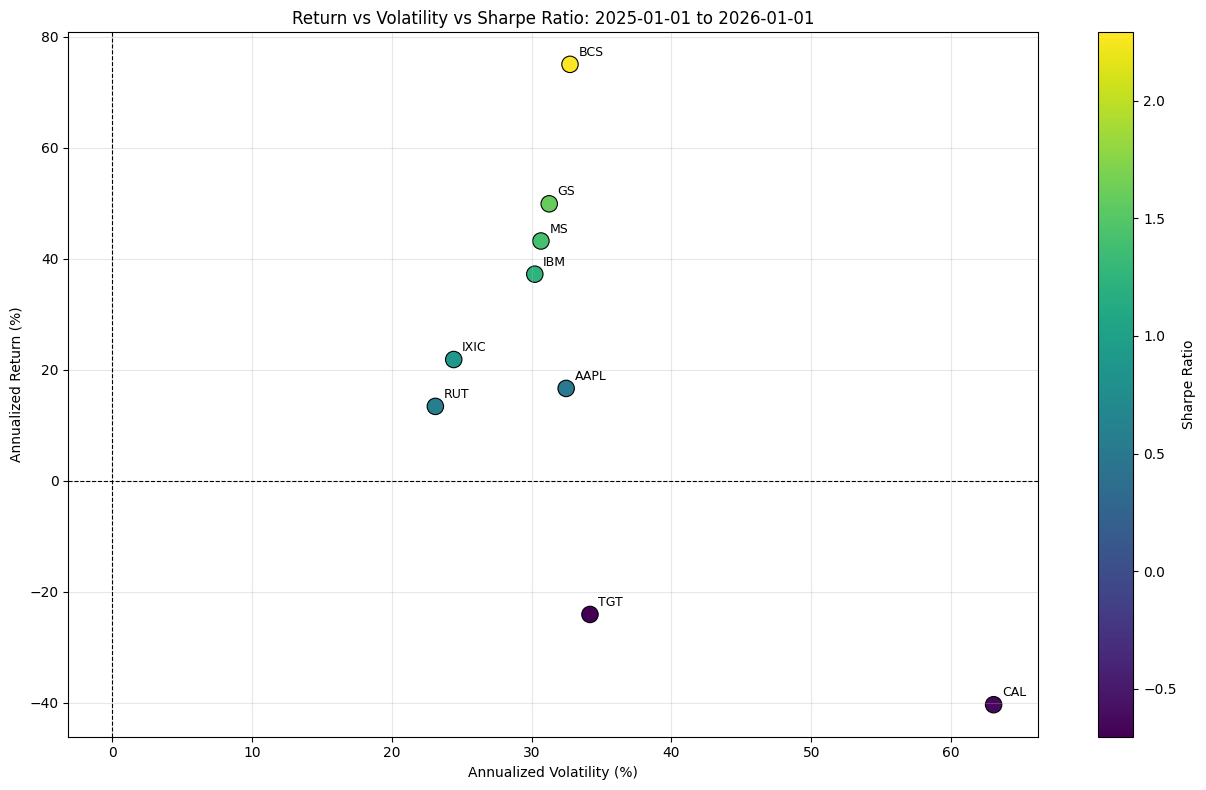

Annualized performance summary:


,Annualized Return (%),Annualized Volatility (%),Sharpe Ratio
BCS,75.03,32.74,2.29
GS,49.90,31.25,1.60
MS,43.20,30.66,1.41
IBM,37.23,30.22,1.23
IXIC,21.85,24.42,0.89
RUT,13.41,23.10,0.58
AAPL,16.64,32.46,0.51
CAL,-40.34,63.05,-0.64
TGT,-24.08,34.17,-0.70


In [ ]:
# Cell 19: Return vs volatility vs Sharpe ratio for all downloaded series
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if 'prices_2025' not in globals() or prices_2025.empty:
    raise RuntimeError('Run cell 17 first so prices_2025 contains the daily data.')

# Calculate daily percentage returns from the prices downloaded in cell 17.
daily_returns_2025 = prices_2025.sort_index().pct_change().dropna(how='all')

# Use 252 trading days to annualize daily statistics.
annualized_return_2025 = daily_returns_2025.mean() * 252
annualized_volatility_2025 = daily_returns_2025.std() * np.sqrt(252)
sharpe_ratio_2025 = annualized_return_2025 / annualized_volatility_2025

summary_2025 = pd.DataFrame({
    'Annualized Return (%)': annualized_return_2025 * 100,
    'Annualized Volatility (%)': annualized_volatility_2025 * 100,
    'Sharpe Ratio': sharpe_ratio_2025,
}).sort_values('Sharpe Ratio', ascending=False)

# Plot return against volatility; colour represents the Sharpe ratio.
plt.figure(figsize=(13, 8))
scatter = plt.scatter(
    summary_2025['Annualized Volatility (%)'],
    summary_2025['Annualized Return (%)'],
    c=summary_2025['Sharpe Ratio'],
    cmap='viridis',
    s=140,
    edgecolors='black',
    linewidths=0.8,
)

for series_name, row in summary_2025.iterrows():
    plt.annotate(
        series_name,
        (row['Annualized Volatility (%)'], row['Annualized Return (%)']),
        xytext=(6, 6),
        textcoords='offset points',
        fontsize=9,
    )

plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.colorbar(scatter, label='Sharpe Ratio')
plt.title('Return vs Volatility vs Sharpe Ratio: 2025-01-01 to 2026-01-01')
plt.xlabel('Annualized Volatility (%)')
plt.ylabel('Annualized Return (%)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Annualized performance summary:')
display(summary_2025.round(2))

Daily return correlation matrix:


,IBM,AAPL,IXIC,MS,TGT,RUT,CAL,GS,BCS
IBM,1.000,0.355,0.411,0.392,0.205,0.448,0.197,0.400,0.307
AAPL,0.355,1.000,0.735,0.583,0.509,0.617,0.407,0.586,0.467
IXIC,0.411,0.735,1.000,0.789,0.467,0.840,0.445,0.789,0.635
MS,0.392,0.583,0.789,1.000,0.437,0.788,0.349,0.914,0.700
TGT,0.205,0.509,0.467,0.437,1.000,0.620,0.613,0.448,0.315
RUT,0.448,0.617,0.840,0.788,0.620,1.000,0.594,0.802,0.650
CAL,0.197,0.407,0.445,0.349,0.613,0.594,1.000,0.364,0.248
GS,0.400,0.586,0.789,0.914,0.448,0.802,0.364,1.000,0.715
BCS,0.307,0.467,0.635,0.700,0.315,0.650,0.248,0.715,1.000


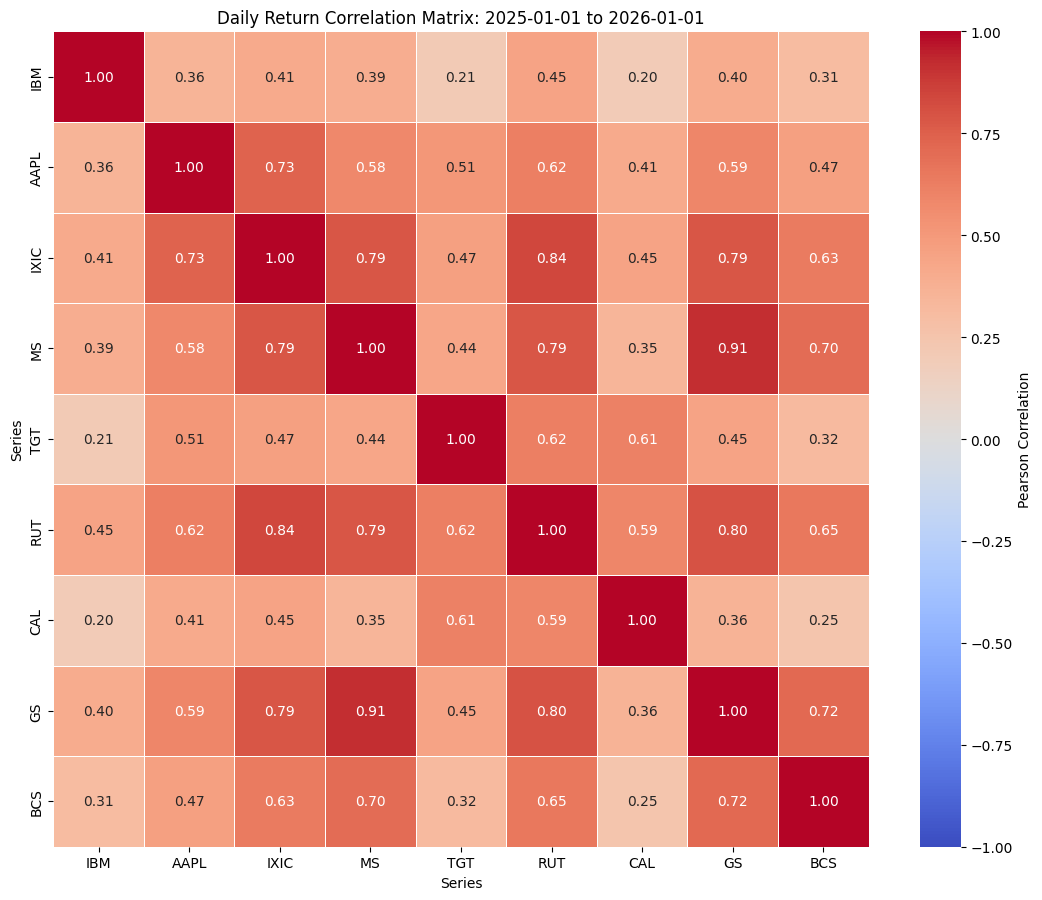

In [ ]:
# Cell 20: Return correlation matrix for all downloaded series
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if 'prices_2025' not in globals() or prices_2025.empty:
    raise RuntimeError('Run cell 17 first so prices_2025 contains the daily data.')

# Calculate daily percentage returns from the 2025-01-01 to 2026-01-01 prices.
daily_returns_2025 = prices_2025.sort_index().pct_change().dropna(how='all')
return_correlation_2025 = daily_returns_2025.corr()

print('Daily return correlation matrix:')
display(return_correlation_2025.round(3))

# Plot the correlation matrix as a heatmap.
plt.figure(figsize=(11, 9))
sns.heatmap(
    return_correlation_2025,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation'},
)
plt.title('Daily Return Correlation Matrix: 2025-01-01 to 2026-01-01')
plt.xlabel('Series')
plt.ylabel('Series')
plt.tight_layout()
plt.show()

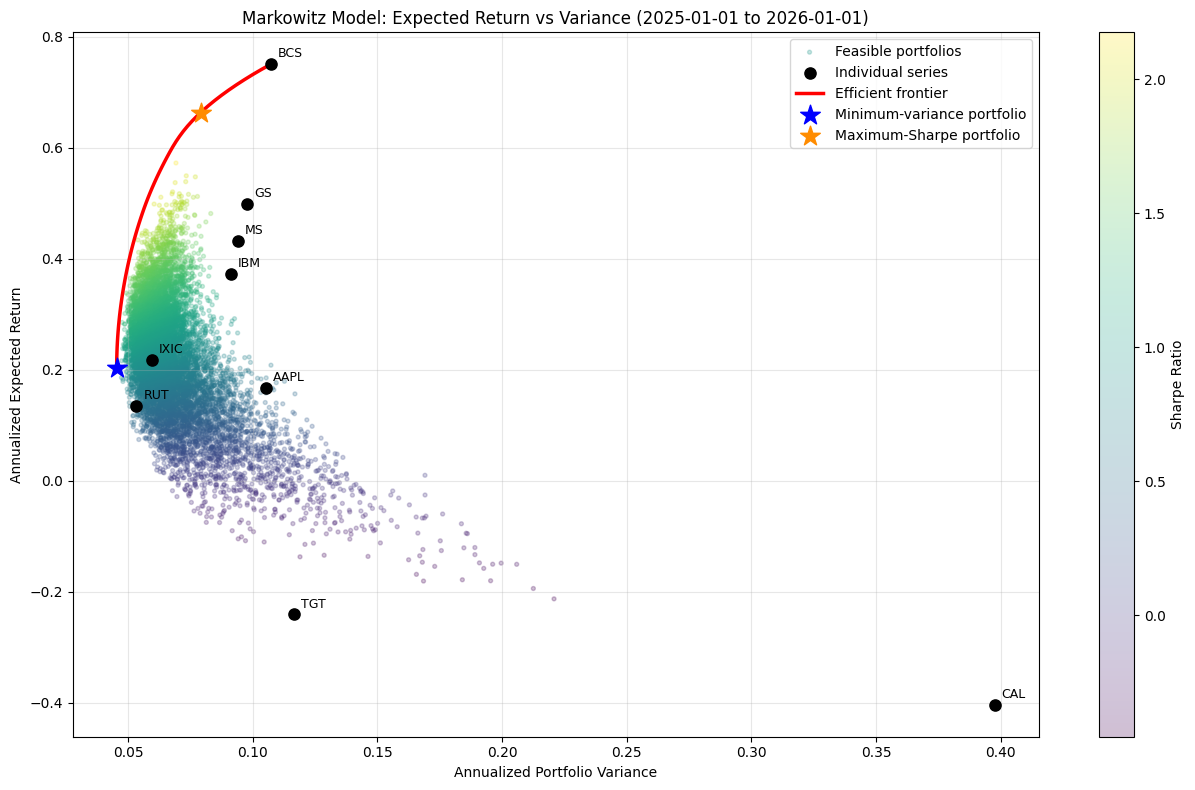

Individual series statistics:


,Expected Return (%),Variance,Volatility (%)
BCS,75.0279,0.1072,32.7395
GS,49.9034,0.0977,31.2517
MS,43.2028,0.0940,30.6592
IBM,37.2253,0.0913,30.2210
IXIC,21.8527,0.0596,24.4193
AAPL,16.6449,0.1054,32.4641
RUT,13.4090,0.0534,23.1042
TGT,-24.0765,0.1167,34.1681
CAL,-40.3357,0.3976,63.0520


Optimized portfolio statistics:


,Portfolio,Expected Return (%),Variance,Volatility (%),Sharpe Ratio
0,Minimum variance,20.3600,0.0455,21.3290,0.9546
1,Maximum Sharpe,66.3255,0.0791,28.1274,2.3580


Optimized portfolio weights:


,Minimum-variance weight (%),Maximum-Sharpe weight (%)
IBM,25.84,23.02
AAPL,0.00,0.00
IXIC,28.64,0.00
MS,0.00,0.00
TGT,10.37,0.00
RUT,31.47,0.00
CAL,0.00,0.00
GS,0.00,0.00
BCS,3.68,76.98


In [ ]:
# Markowitz model - expected return versus variance
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

if 'prices_2025' not in globals() or prices_2025.empty:
    raise RuntimeError('Run cell 17 first so prices_2025 contains the daily data.')

# Calculate annualized expected returns and covariance from daily data.
daily_returns_markowitz = prices_2025.sort_index().pct_change().dropna(how='all')
daily_returns_markowitz = daily_returns_markowitz.dropna(axis=1, how='all')
assets_markowitz = list(daily_returns_markowitz.columns)
asset_count = len(assets_markowitz)
annual_returns_markowitz = daily_returns_markowitz.mean() * 252
annual_covariance_markowitz = daily_returns_markowitz.cov() * 252

# Remove any rows with missing values so all portfolio calculations use the same dates.
daily_returns_markowitz = daily_returns_markowitz.dropna()
annual_returns_markowitz = daily_returns_markowitz.mean() * 252
annual_covariance_markowitz = daily_returns_markowitz.cov() * 252

returns_array = annual_returns_markowitz.to_numpy()
covariance_array = annual_covariance_markowitz.to_numpy()

# Long-only Markowitz constraints: weights sum to one and each weight is between 0 and 1.
constraints_markowitz = ({'type': 'eq', 'fun': lambda weights: np.sum(weights) - 1.0},)
bounds_markowitz = tuple((0.0, 1.0) for _ in range(asset_count))
initial_weights_markowitz = np.full(asset_count, 1.0 / asset_count)

def portfolio_return(weights):
    return float(weights @ returns_array)

def portfolio_variance(weights):
    return float(weights @ covariance_array @ weights)

def portfolio_volatility(weights):
    return np.sqrt(max(portfolio_variance(weights), 0.0))

def negative_sharpe(weights):
    volatility = portfolio_volatility(weights)
    return -portfolio_return(weights) / volatility if volatility > 0 else 0.0

# Minimum-variance portfolio.
minimum_variance_result = minimize(
    portfolio_variance,
    initial_weights_markowitz,
    method='SLSQP',
    bounds=bounds_markowitz,
    constraints=constraints_markowitz,
)

if not minimum_variance_result.success:
    raise RuntimeError(f'Minimum-variance optimization failed: {minimum_variance_result.message}')

minimum_variance_weights = minimum_variance_result.x
minimum_variance_return = portfolio_return(minimum_variance_weights)
minimum_variance_value = portfolio_variance(minimum_variance_weights)

# Maximum-Sharpe portfolio, assuming a zero risk-free rate.
maximum_sharpe_result = minimize(
    negative_sharpe,
    initial_weights_markowitz,
    method='SLSQP',
    bounds=bounds_markowitz,
    constraints=constraints_markowitz,
)

if not maximum_sharpe_result.success:
    raise RuntimeError(f'Maximum-Sharpe optimization failed: {maximum_sharpe_result.message}')

maximum_sharpe_weights = maximum_sharpe_result.x
maximum_sharpe_return = portfolio_return(maximum_sharpe_weights)
maximum_sharpe_value = portfolio_variance(maximum_sharpe_weights)
maximum_sharpe_ratio = maximum_sharpe_return / np.sqrt(maximum_sharpe_value)

# Generate the long-only efficient frontier by fixing target returns.
minimum_target_return = minimum_variance_return
maximum_target_return = float(np.max(returns_array))
target_returns = np.linspace(minimum_target_return, maximum_target_return, 60)
frontier_returns = []
frontier_variances = []
frontier_weights = []

for target_return in target_returns:
    frontier_constraints = (
        {'type': 'eq', 'fun': lambda weights: np.sum(weights) - 1.0},
        {'type': 'eq', 'fun': lambda weights, target=target_return: portfolio_return(weights) - target},
    )
    frontier_result = minimize(
        portfolio_variance,
        initial_weights_markowitz,
        method='SLSQP',
        bounds=bounds_markowitz,
        constraints=frontier_constraints,
        options={'maxiter': 1000, 'ftol': 1e-12},
    )
    if frontier_result.success:
        frontier_returns.append(portfolio_return(frontier_result.x))
        frontier_variances.append(portfolio_variance(frontier_result.x))
        frontier_weights.append(frontier_result.x)

frontier_returns = np.asarray(frontier_returns)
frontier_variances = np.asarray(frontier_variances)

# Create a feasible set of random long-only portfolios for the Markowitz diagram.
rng_markowitz = np.random.default_rng(42)
random_weights = rng_markowitz.dirichlet(np.ones(asset_count), size=10000)
random_returns = random_weights @ returns_array
random_variances = np.einsum('ij,jk,ik->i', random_weights, covariance_array, random_weights)
random_sharpes = random_returns / np.sqrt(np.maximum(random_variances, 1e-15))

# Plot expected return against variance, as in the attached image.
plt.figure(figsize=(13, 8))
scatter = plt.scatter(
    random_variances,
    random_returns,
    c=random_sharpes,
    cmap='viridis',
    s=8,
    alpha=0.25,
    label='Feasible portfolios',
)
plt.scatter(
    np.diag(covariance_array),
    returns_array,
    color='black',
    s=65,
    zorder=4,
    label='Individual series',
)
for asset_name, variance, expected_return in zip(assets_markowitz, np.diag(covariance_array), returns_array):
    plt.annotate(asset_name, (variance, expected_return), xytext=(5, 5), textcoords='offset points', fontsize=9)

if len(frontier_variances) > 0:
    frontier_order = np.argsort(frontier_variances)
    plt.plot(
        frontier_variances[frontier_order],
        frontier_returns[frontier_order],
        color='red',
        linewidth=2.5,
        label='Efficient frontier',
    )

plt.scatter(
    minimum_variance_value,
    minimum_variance_return,
    color='blue',
    marker='*',
    s=220,
    zorder=5,
    label='Minimum-variance portfolio',
)
plt.scatter(
    maximum_sharpe_value,
    maximum_sharpe_return,
    color='darkorange',
    marker='*',
    s=220,
    zorder=5,
    label='Maximum-Sharpe portfolio',
)
plt.xlabel('Annualized Portfolio Variance')
plt.ylabel('Annualized Expected Return')
plt.title('Markowitz Model: Expected Return vs Variance (2025-01-01 to 2026-01-01)')
plt.colorbar(scatter, label='Sharpe Ratio')
plt.grid(True, alpha=0.3)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

# Report the two optimized portfolios and individual annualized statistics.
individual_statistics_markowitz = pd.DataFrame({
    'Expected Return (%)': annual_returns_markowitz * 100,
    'Variance': np.diag(covariance_array),
    'Volatility (%)': np.sqrt(np.diag(covariance_array)) * 100,
}).sort_values('Expected Return (%)', ascending=False)

portfolio_statistics_markowitz = pd.DataFrame({
    'Portfolio': ['Minimum variance', 'Maximum Sharpe'],
    'Expected Return (%)': [minimum_variance_return * 100, maximum_sharpe_return * 100],
    'Variance': [minimum_variance_value, maximum_sharpe_value],
    'Volatility (%)': [np.sqrt(minimum_variance_value) * 100, np.sqrt(maximum_sharpe_value) * 100],
    'Sharpe Ratio': [minimum_variance_return / np.sqrt(minimum_variance_value), maximum_sharpe_ratio],
})

print('Individual series statistics:')
display(individual_statistics_markowitz.round(4))
print('Optimized portfolio statistics:')
display(portfolio_statistics_markowitz.round(4))

weights_markowitz = pd.DataFrame({
    'Minimum-variance weight (%)': minimum_variance_weights * 100,
    'Maximum-Sharpe weight (%)': maximum_sharpe_weights * 100,
}, index=assets_markowitz)
print('Optimized portfolio weights:')
display(weights_markowitz.round(2))

In [ ]:
"""
Collect daily price data for 20 US stocks using yfinance.
Period: 2000-01-01 to 2026-01-01

Outputs (in ./us_stock_data):
  - <TICKER>.csv          : per-stock OHLCV data
  - all_stocks_long.csv   : all stocks stacked (Date, Ticker, OHLCV)
  - adj_close_wide.csv    : Date x Ticker matrix of adjusted close prices
  - close_wide.csv        : Date x Ticker matrix of raw close prices
  - download_summary.csv  : rows, first/last date per ticker

Install:  pip install yfinance pandas
"""

import os
import time

import pandas as pd
import yfinance as yf

# ----------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------
START_DATE = "2000-01-01"
END_DATE = "2026-01-01"   # yfinance 'end' is exclusive
OUTPUT_DIR = "us_stock_data"
MAX_RETRIES = 3

# Note: Yahoo Finance uses a hyphen for share classes: BRK.B -> BRK-B
# (BRK-A is also available; add it below if you want both share classes.)
STOCKS = {
    "MSFT":  "Microsoft Corporation",
    "AAPL":  "Apple Inc.",
    "NVDA":  "NVIDIA Corporation",
    "AMZN":  "Amazon.com Inc.",
    "INTC":  "Intel Corporation",
    "WMT":   "Walmart Inc.",
    "KO":    "The Coca-Cola Company",
    "DIS":   "The Walt Disney Company",
    "PG":    "The Procter & Gamble Company",
    "IBM":   "International Business Machines",
    "MCD":   "McDonald's Corporation",
    "JPM":   "JPMorgan Chase & Co.",
    "GS":    "The Goldman Sachs Group, Inc.",
    "MS":    "Morgan Stanley",
    "AXP":   "American Express Company",
    "BAC":   "Bank of America Corporation",
    "JNJ":   "Johnson & Johnson",
    "XOM":   "ExxonMobil Corporation",
    "UNH":   "UnitedHealth Group Incorporated",
    "BRK-B": "Berkshire Hathaway Inc. (Class B)",
    # "BRK-A": "Berkshire Hathaway Inc. (Class A)",
}


# ----------------------------------------------------------------------
# Download helper
# ----------------------------------------------------------------------
def download_ticker(ticker: str) -> pd.DataFrame:
    """Download daily OHLCV for one ticker, with retries.

    auto_adjust=False keeps both 'Close' (split-adjusted) and 'Adj Close'
    (split + dividend adjusted).
    """
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            df = yf.download(
                ticker,
                start=START_DATE,
                end=END_DATE,
                interval="1d",
                auto_adjust=False,
                progress=False,
                threads=False,
            )
            if df is not None and not df.empty:
                # Newer yfinance versions return MultiIndex columns
                if isinstance(df.columns, pd.MultiIndex):
                    df.columns = df.columns.get_level_values(0)
                df.index = pd.to_datetime(df.index)
                df.index.name = "Date"
                df = df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]]
                return df.dropna(how="all")
            print(f"  [{ticker}] empty result (attempt {attempt}/{MAX_RETRIES})")
        except Exception as e:
            print(f"  [{ticker}] error: {e} (attempt {attempt}/{MAX_RETRIES})")
        time.sleep(2 * attempt)
    return pd.DataFrame()


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    os.makedirs(OUTPUT_DIR, exist_ok=True)

    data = {}
    summary = []
    failed = []

    print(f"Downloading {len(STOCKS)} stocks from {START_DATE} to {END_DATE}\n")

    for i, (ticker, name) in enumerate(STOCKS.items(), start=1):
        print(f"[{i:02d}/{len(STOCKS)}] {ticker} - {name}")
        df = download_ticker(ticker)

        if df.empty:
            failed.append(ticker)
            continue

        df.to_csv(os.path.join(OUTPUT_DIR, f"{ticker}.csv"))
        data[ticker] = df
        summary.append(
            {
                "Ticker": ticker,
                "Name": name,
                "Rows": len(df),
                "First_Date": df.index.min().date(),
                "Last_Date": df.index.max().date(),
                "Missing_Close": int(df["Close"].isna().sum()),
            }
        )
        print(f"  -> {len(df)} rows ({df.index.min().date()} to {df.index.max().date()})")
        time.sleep(0.5)  # be polite to Yahoo

    if not data:
        raise SystemExit("No data downloaded. Check your internet connection.")

    # Long format (all stocks stacked)
    long_df = (
        pd.concat(data, names=["Ticker", "Date"])
        .reset_index()
        .sort_values(["Ticker", "Date"])
    )
    long_df.to_csv(os.path.join(OUTPUT_DIR, "all_stocks_long.csv"), index=False)

    # Wide format matrices (Date x Ticker)
    adj_close = pd.DataFrame({t: d["Adj Close"] for t, d in data.items()}).sort_index()
    close = pd.DataFrame({t: d["Close"] for t, d in data.items()}).sort_index()
    adj_close.to_csv(os.path.join(OUTPUT_DIR, "adj_close_wide.csv"))
    close.to_csv(os.path.join(OUTPUT_DIR, "close_wide.csv"))

    # Summary
    summary_df = pd.DataFrame(summary)
    summary_df.to_csv(os.path.join(OUTPUT_DIR, "download_summary.csv"), index=False)

    print("\n" + "=" * 70)
    print(summary_df.to_string(index=False))
    print("=" * 70)
    print(f"Successful: {len(data)}/{len(STOCKS)}")
    if failed:
        print(f"Failed: {failed}")
    print(f"Files saved in: ./{OUTPUT_DIR}/")


if __name__ == "__main__":
    main()


[01/20] MSFT - Microsoft Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[02/20] AAPL - Apple Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[03/20] NVDA - NVIDIA Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[04/20] AMZN - Amazon.com Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[05/20] INTC - Intel Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[06/20] WMT - Walmart Inc.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[07/20] KO - The Coca-Cola Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[08/20] DIS - The Walt Disney Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[09/20] PG - The Procter & Gamble Company
  -> 6539 rows (2000-01-03 to 2025-12-31)
[10/20] IBM - International Business Machines
  -> 6539 rows (2000-01-03 to 2025-12-31)
[11/20] MCD - McDonald's Corporation
  -> 6539 rows (2000-01-03 to 2025-12-31)
[12/20] JPM - JPMorgan Chase & Co.
  -> 6539 rows (2000-01-03 to 2025-12-31)
[13/20] GS - The Goldman Sachs Group, Inc.
  -> 6539 rows (2000-01-03 to 2

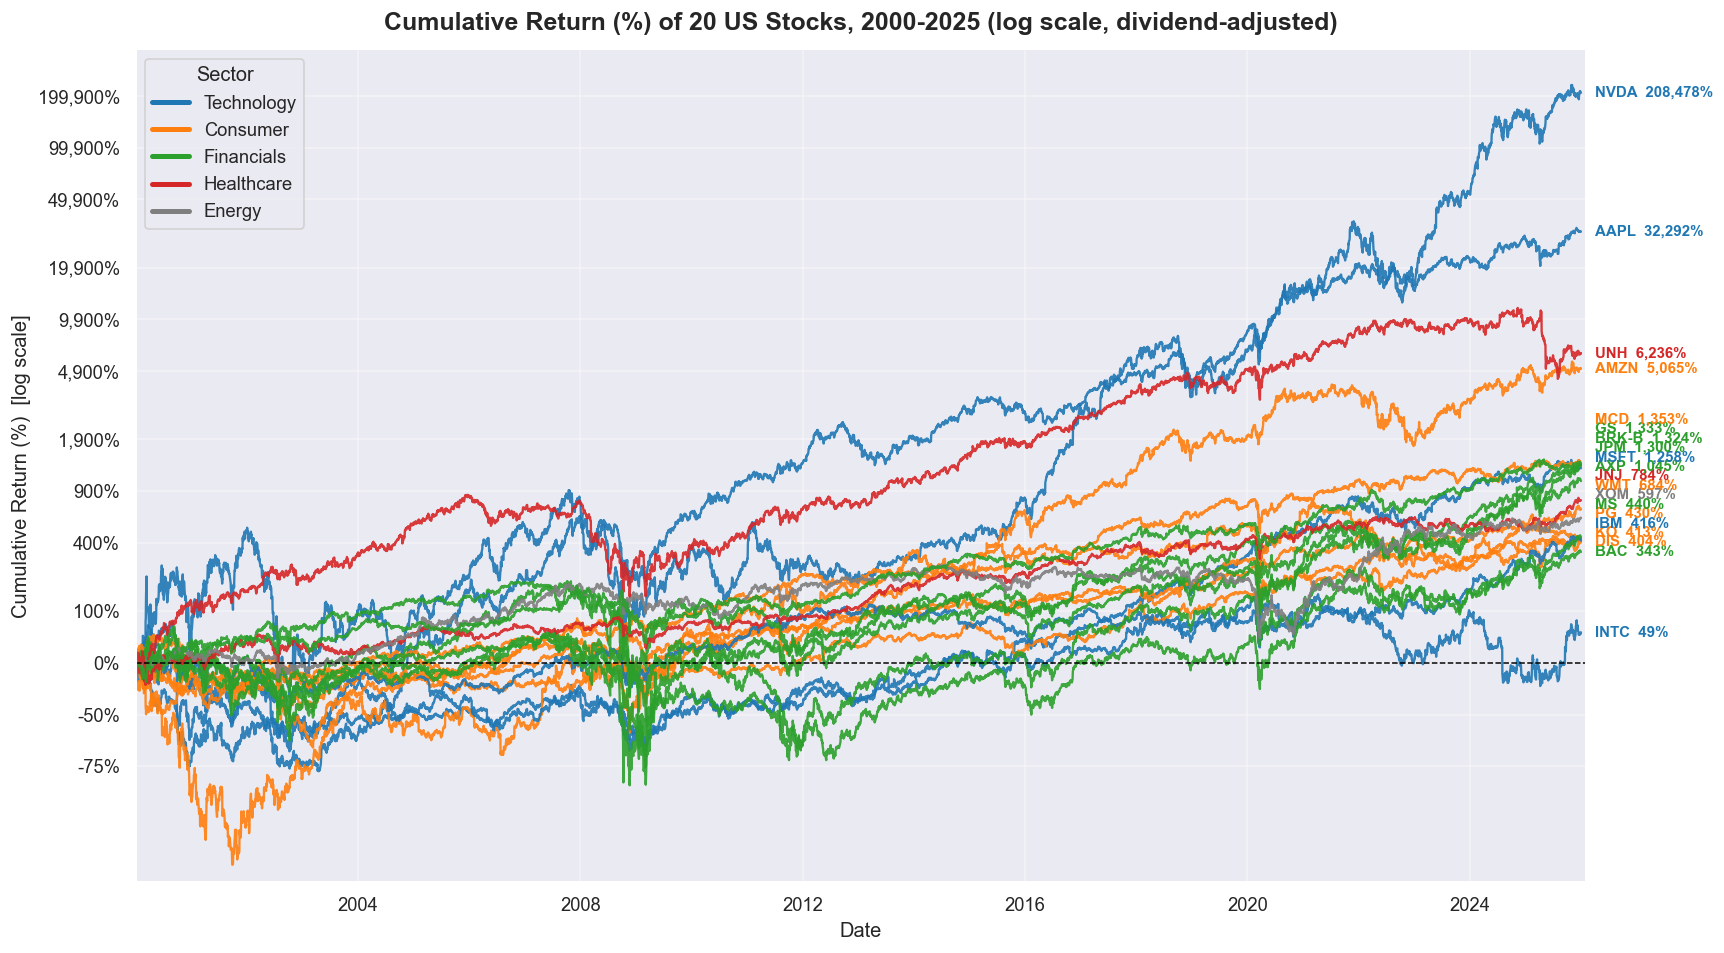

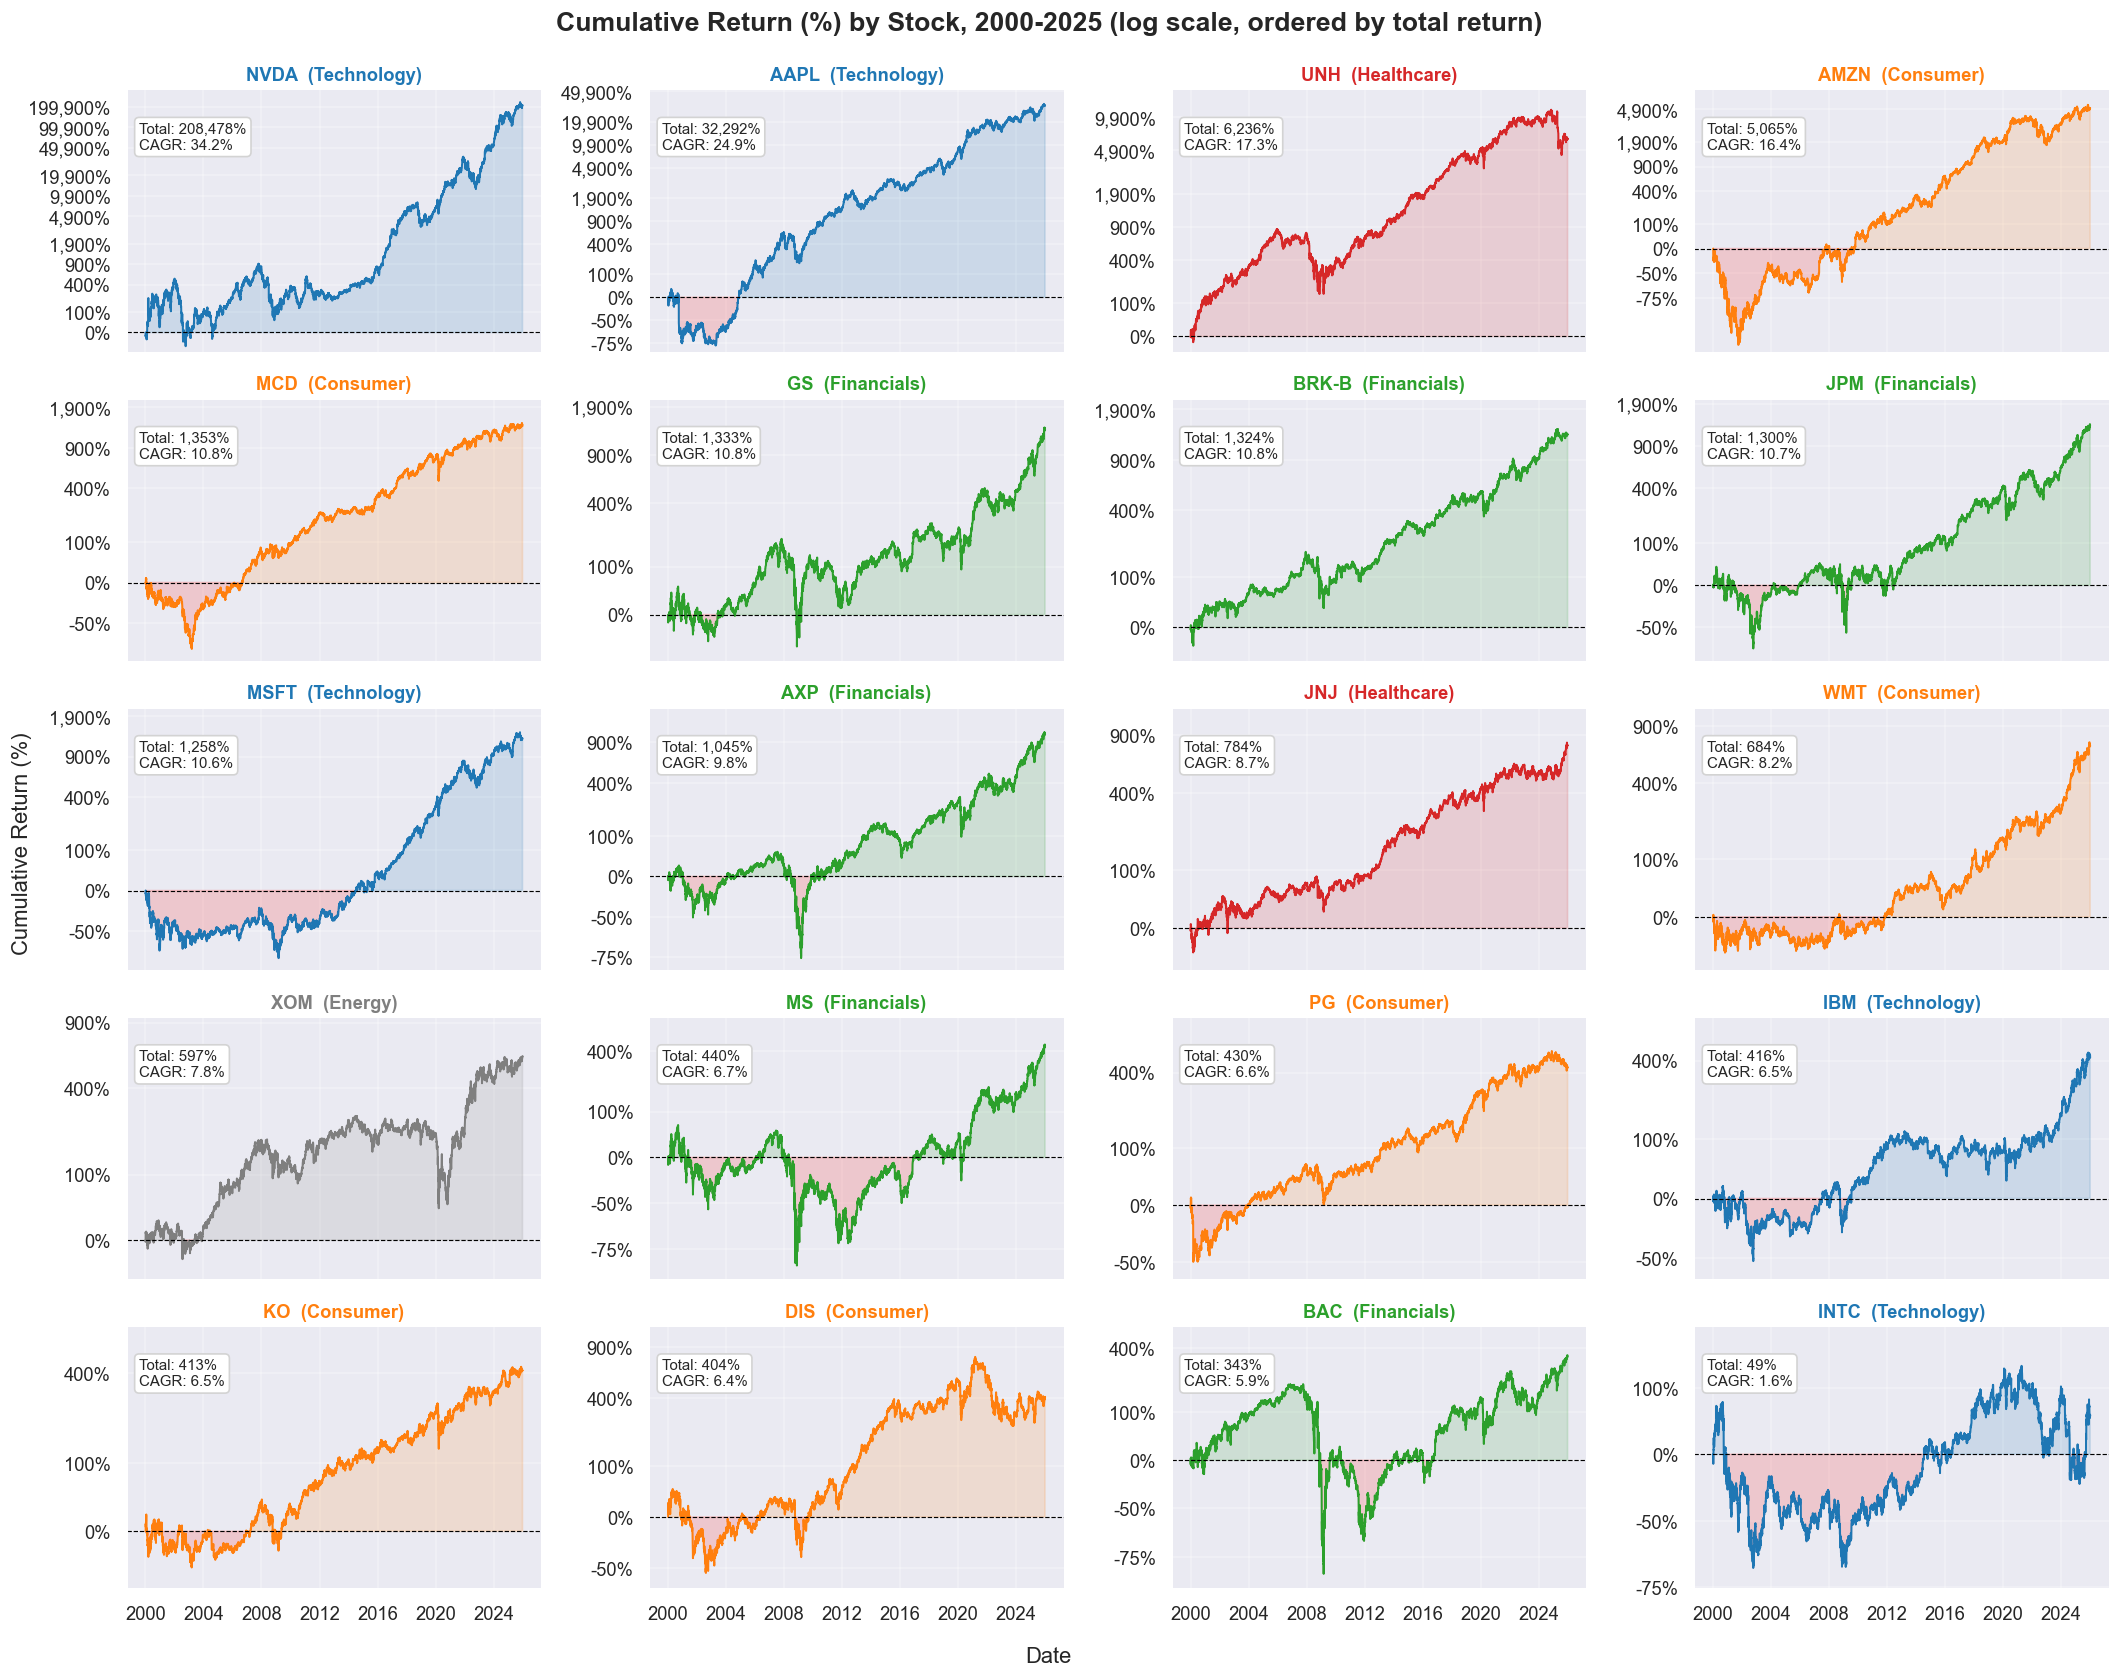

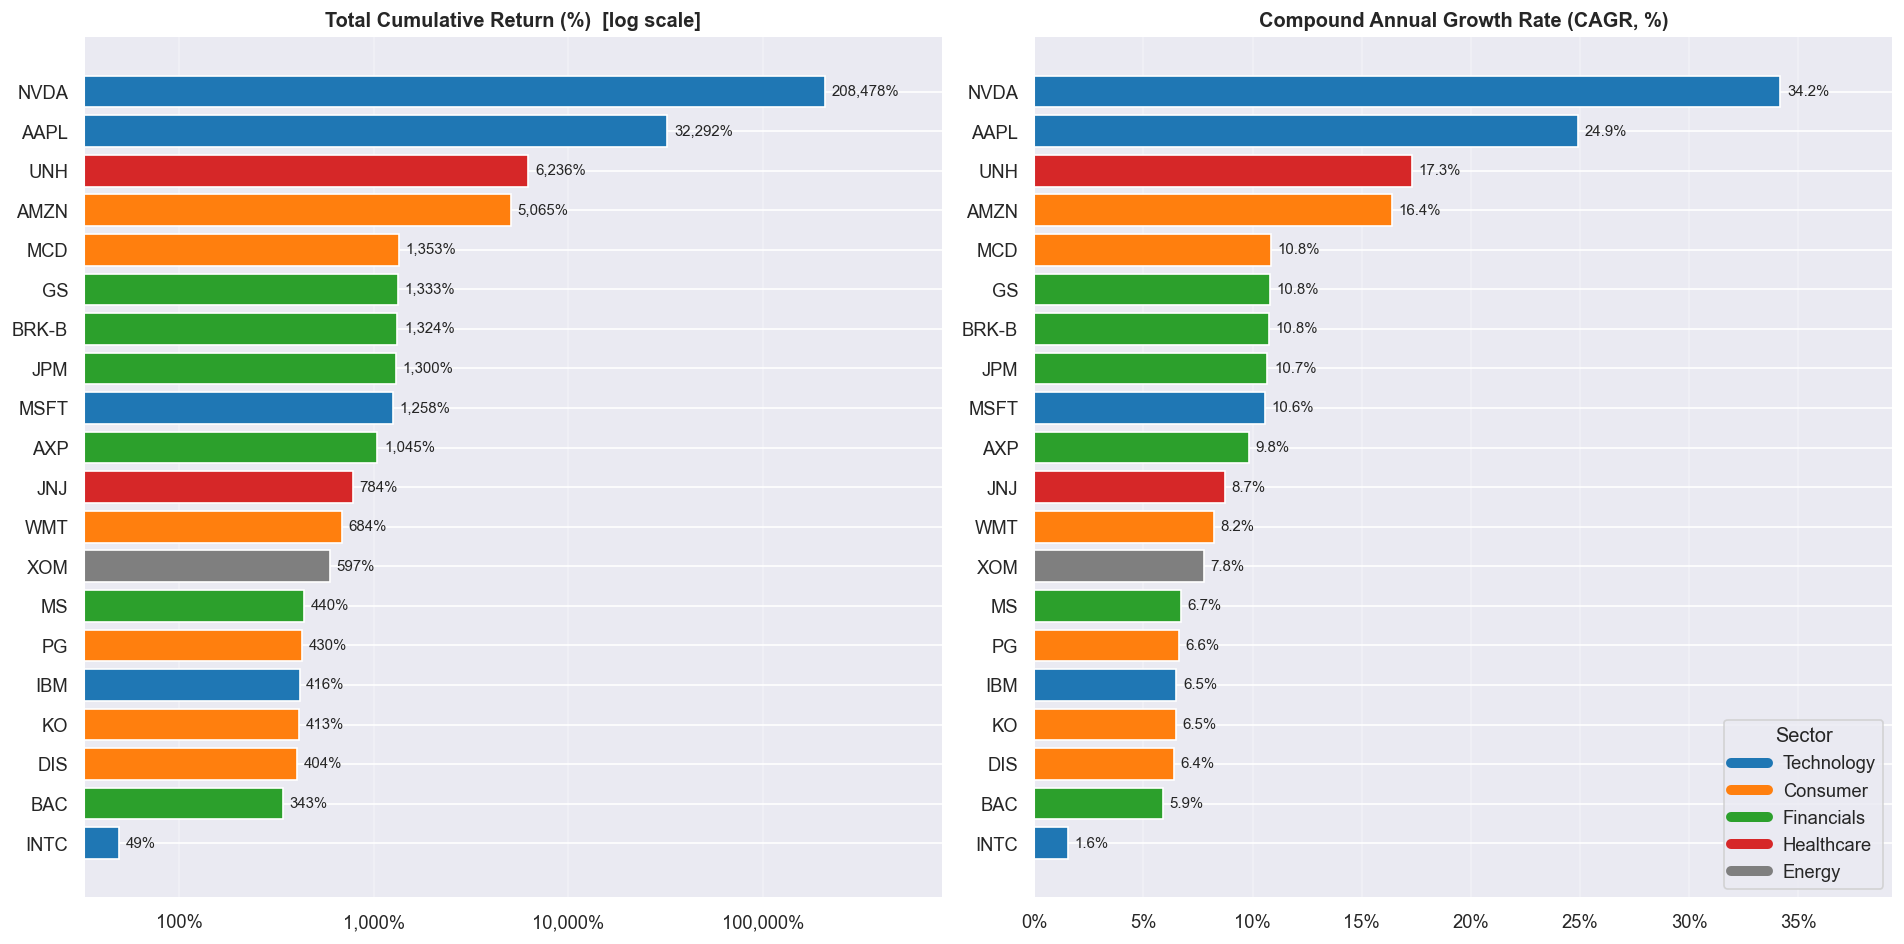

,Sector,Total Return (%),CAGR (%)
NVDA,Technology,208477.5,34.18
AAPL,Technology,32292.0,24.91
UNH,Healthcare,6236.1,17.31
AMZN,Consumer,5065.2,16.39
MCD,Consumer,1352.5,10.84
GS,Financials,1332.5,10.78
BRK-B,Financials,1323.9,10.76
JPM,Financials,1300.1,10.69
MSFT,Technology,1258.4,10.56
AXP,Financials,1044.5,9.83


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# ----------------------------------------------------------------------
# Load data saved by cell 1
# ----------------------------------------------------------------------
adj_close = pd.read_csv("us_stock_data/adj_close_wide.csv", index_col="Date", parse_dates=True)

# Wealth index: value of $1 invested at each stock's first available price
wealth = adj_close / adj_close.apply(lambda s: s.dropna().iloc[0])
cum_ret = (wealth - 1) * 100                     # cumulative return in %
final_ret = cum_ret.ffill().iloc[-1].sort_values(ascending=False)
years = (adj_close.index[-1] - adj_close.index[0]).days / 365.25
cagr = (wealth.ffill().iloc[-1] ** (1 / years) - 1) * 100

# Sector colours (makes the chart easier to interpret)
sector = {
    "MSFT": "Technology", "AAPL": "Technology", "NVDA": "Technology",
    "INTC": "Technology", "IBM": "Technology",
    "AMZN": "Consumer", "WMT": "Consumer", "KO": "Consumer",
    "DIS": "Consumer", "PG": "Consumer", "MCD": "Consumer",
    "JPM": "Financials", "GS": "Financials", "MS": "Financials",
    "AXP": "Financials", "BAC": "Financials", "BRK-B": "Financials",
    "JNJ": "Healthcare", "UNH": "Healthcare",
    "XOM": "Energy",
}
sector_color = {"Technology": "#1f77b4", "Consumer": "#ff7f0e", "Financials": "#2ca02c",
                "Healthcare": "#d62728", "Energy": "#7f7f7f"}
col = {t: sector_color[sector[t]] for t in wealth.columns}

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# Y-axis: log scale on wealth index, tick labels shown as cumulative return (%)
def ret_formatter():
    return mtick.FuncFormatter(lambda w, _: f"{(w - 1) * 100:,.0f}%")

ticks = np.array([0.25, 0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000])

# ======================================================================
# FIGURE 1: Cumulative return (log scale) with direct end-labels
# ======================================================================
fig, ax = plt.subplots(figsize=(16, 9), dpi=120)

for t in wealth.columns:
    ax.plot(wealth.index, wealth[t], color=col[t], lw=1.4, alpha=0.9)

ax.set_yscale("log")
ymin, ymax = wealth.min().min() * 0.8, wealth.max().max() * 1.6
ax.set_ylim(ymin, ymax)
ax.set_yticks(ticks[(ticks >= ymin) & (ticks <= ymax)])
ax.yaxis.set_major_formatter(ret_formatter())
ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.axhline(1, color="black", lw=0.9, ls="--")          # break-even line
ax.grid(True, which="major", alpha=0.35)

# Direct labels at the right edge (spread out so they don't overlap)
last = wealth.ffill().iloc[-1].sort_values()
pos, min_gap, prev = {}, 0.055, None
for t, v in last.items():
    y = np.log10(v)
    y = y if prev is None or y - prev >= min_gap else prev + min_gap
    pos[t], prev = y, y
x_end = wealth.index[-1] + pd.Timedelta(days=90)
for t, y in pos.items():
    ax.annotate(f"{t}  {final_ret[t]:,.0f}%", xy=(x_end, 10 ** y), va="center",
                fontsize=9, color=col[t], fontweight="bold", annotation_clip=False)

ax.set_xlim(wealth.index[0], wealth.index[-1] + pd.Timedelta(days=30))
ax.set_title("Cumulative Return (%) of 20 US Stocks, 2000-2025 (log scale, dividend-adjusted)",
             fontsize=15, fontweight="bold", pad=12)
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative Return (%)  [log scale]")

handles = [plt.Line2D([0], [0], color=c, lw=3, label=s) for s, c in sector_color.items()]
ax.legend(handles=handles, loc="upper left", title="Sector", frameon=True)
fig.subplots_adjust(right=0.88)
plt.savefig("cumulative_return_log.png", dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# FIGURE 2: Small multiples (one panel per stock)
# ======================================================================
order = list(final_ret.index)
fig, axes = plt.subplots(5, 4, figsize=(18, 14), sharex=True, dpi=120)

for ax, t in zip(axes.flat, order):
    w = wealth[t].dropna()
    ax.plot(w.index, w, color=col[t], lw=1.2)
    ax.axhline(1, color="black", lw=0.7, ls="--")
    ax.fill_between(w.index, 1, w, where=(w >= 1), color=col[t], alpha=0.15)
    ax.fill_between(w.index, 1, w, where=(w < 1), color="red", alpha=0.15)
    ax.set_yscale("log")
    lo, hi = w.min() * 0.8, w.max() * 1.5
    ax.set_ylim(lo, hi)
    tk = ticks[(ticks >= lo) & (ticks <= hi)]
    ax.set_yticks(tk)
    ax.yaxis.set_major_formatter(ret_formatter())
    ax.yaxis.set_minor_formatter(mtick.NullFormatter())
    ax.set_title(f"{t}  ({sector[t]})", fontsize=11, fontweight="bold", color=col[t])
    ax.text(0.03, 0.88, f"Total: {final_ret[t]:,.0f}%\nCAGR: {cagr[t]:.1f}%",
            transform=ax.transAxes, fontsize=9, va="top",
            bbox=dict(boxstyle="round", fc="white", ec="lightgrey"))
    ax.grid(True, alpha=0.3)

fig.suptitle("Cumulative Return (%) by Stock, 2000-2025 (log scale, ordered by total return)",
             fontsize=16, fontweight="bold", y=0.995)
fig.supxlabel("Date")
fig.supylabel("Cumulative Return (%)")
plt.tight_layout()
plt.savefig("cumulative_return_small_multiples.png", dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# FIGURE 3: Total return and CAGR ranking
# ======================================================================
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 8), dpi=120)

fr = final_ret.sort_values()
a1.barh(fr.index, fr.values, color=[col[t] for t in fr.index])
a1.set_xscale("log")
a1.set_title("Total Cumulative Return (%)  [log scale]", fontweight="bold")
a1.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}%"))
for i, v in enumerate(fr.values):
    a1.text(v * 1.08, i, f"{v:,.0f}%", va="center", fontsize=9)
a1.set_xlim(right=fr.max() * 4)

cg = cagr.sort_values()
a2.barh(cg.index, cg.values, color=[col[t] for t in cg.index])
a2.set_title("Compound Annual Growth Rate (CAGR, %)", fontweight="bold")
a2.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for i, v in enumerate(cg.values):
    a2.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
a2.set_xlim(right=cg.max() * 1.15)

for a in (a1, a2):
    a.grid(True, axis="x", alpha=0.3)
handles = [plt.Line2D([0], [0], color=c, lw=6, label=s) for s, c in sector_color.items()]
a2.legend(handles=handles, loc="lower right", title="Sector")
plt.tight_layout()
plt.savefig("return_ranking.png", dpi=300, bbox_inches="tight")
plt.show()

# Summary table
summary = pd.DataFrame({"Sector": pd.Series(sector), "Total Return (%)": final_ret.round(1),
                        "CAGR (%)": cagr.round(2)}).loc[order]
summary

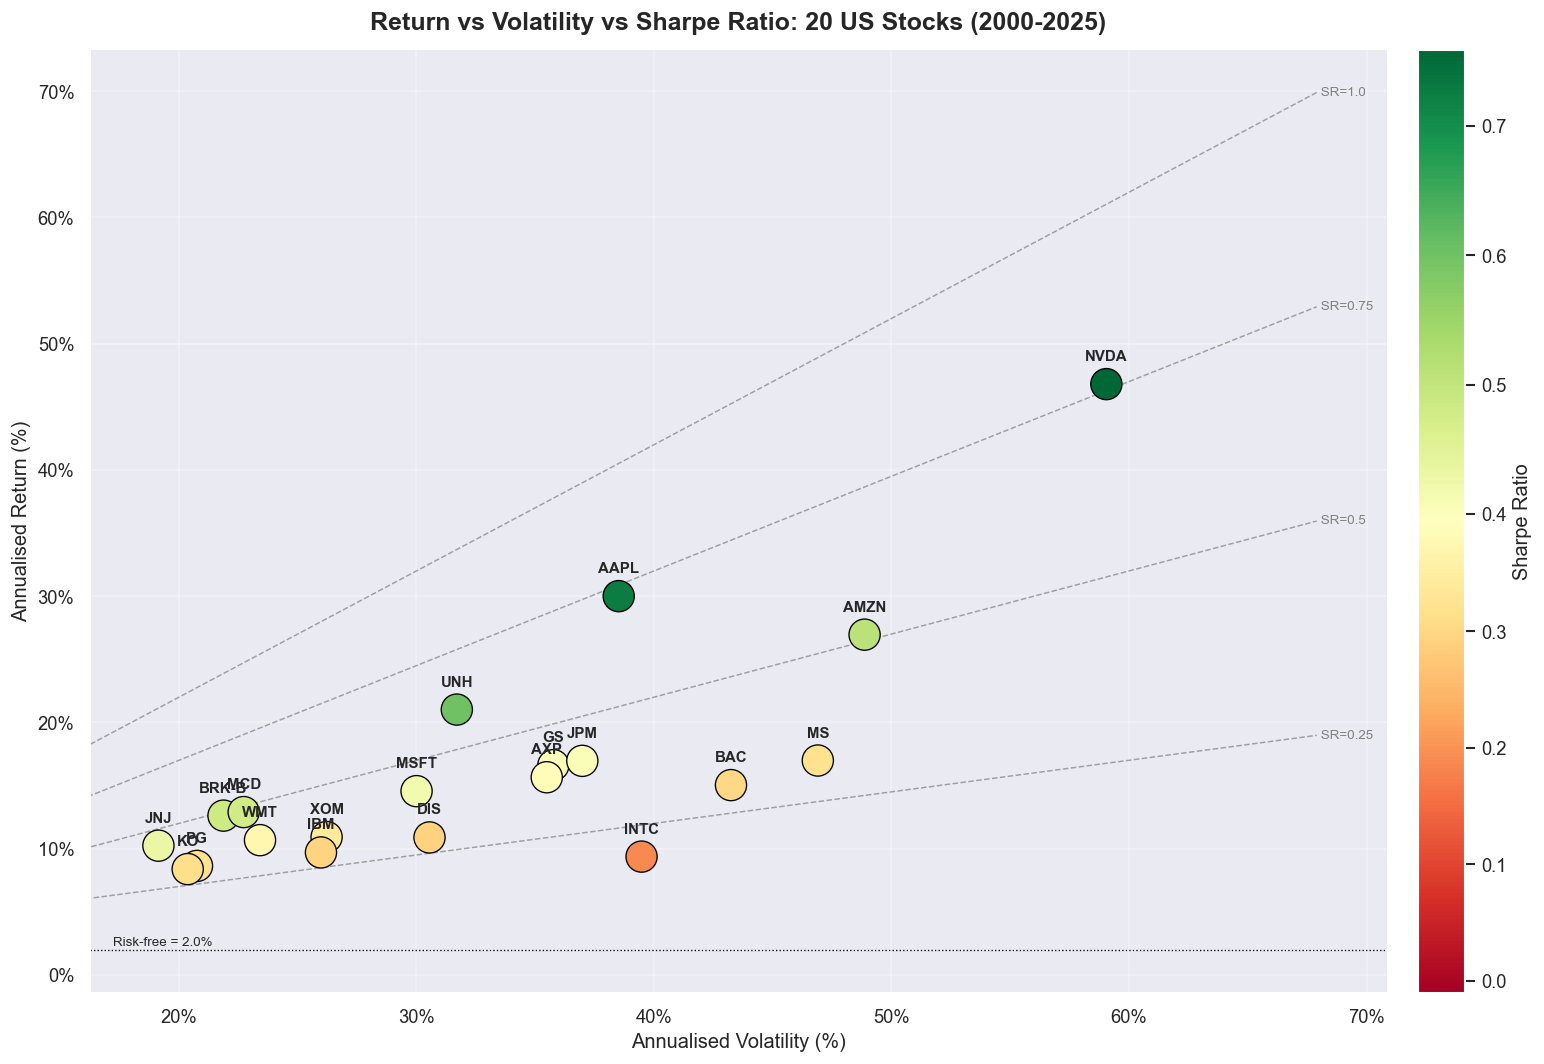

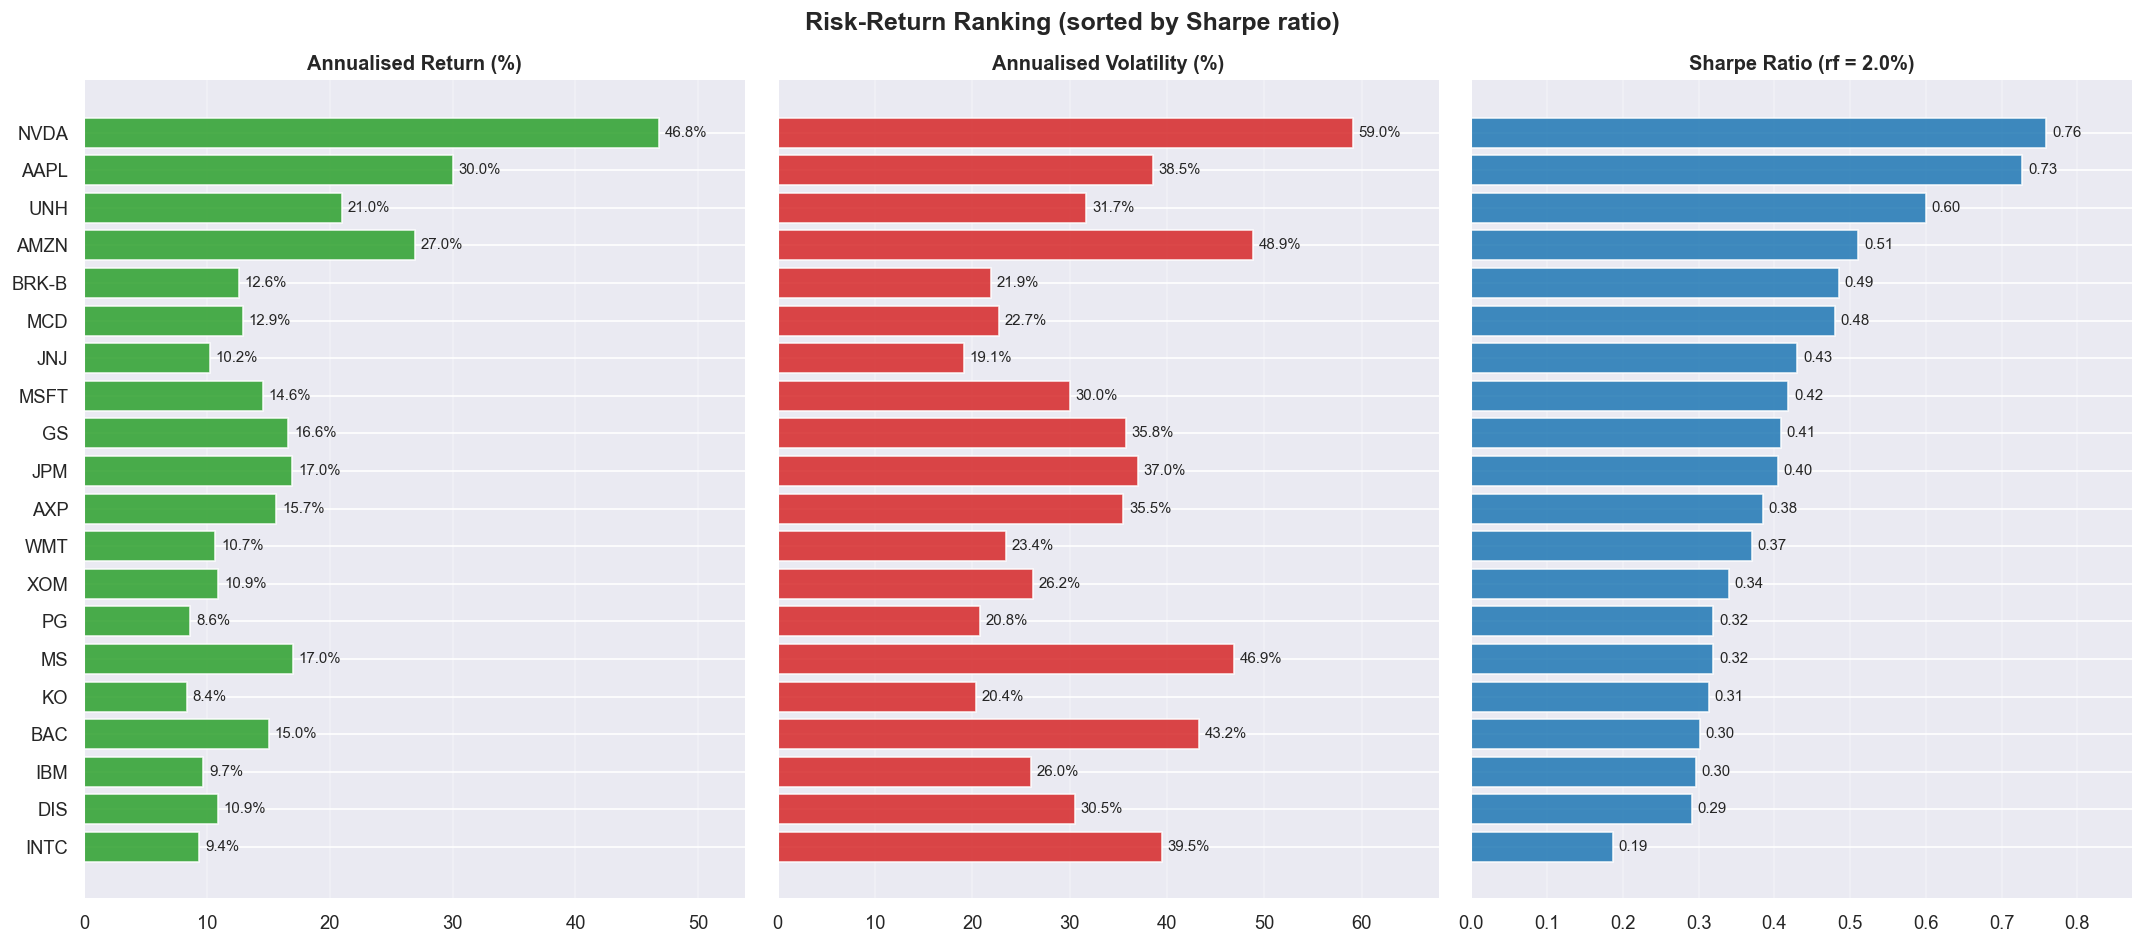

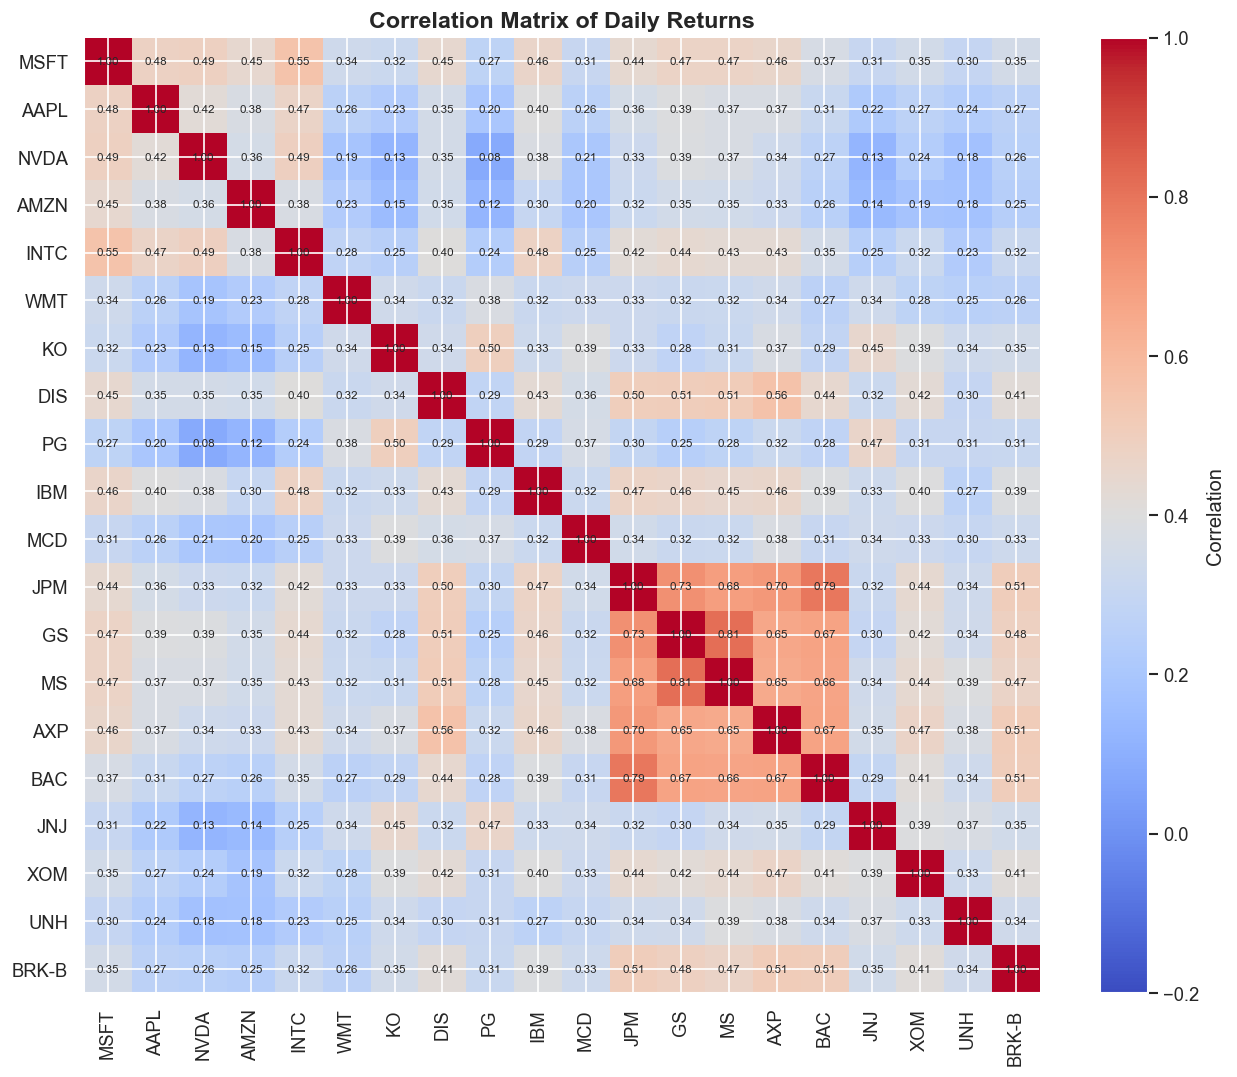

,Ann. Return (%),Ann. Volatility (%),Sharpe Ratio,CAGR (%)
NVDA,46.80,59.05,0.76,34.18
AAPL,30.00,38.52,0.73,24.91
UNH,21.02,31.70,0.60,17.31
AMZN,26.95,48.87,0.51,16.39
BRK-B,12.62,21.88,0.49,10.76
MCD,12.90,22.73,0.48,10.84
JNJ,10.24,19.14,0.43,8.75
MSFT,14.55,30.00,0.42,10.56
GS,16.61,35.76,0.41,10.78
JPM,16.96,36.98,0.40,10.69


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import TwoSlopeNorm

# ----------------------------------------------------------------------
# Settings
# ----------------------------------------------------------------------
RF = 0.02              # annual risk-free rate (2%); change to suit your study
TRADING_DAYS = 252

# ----------------------------------------------------------------------
# Load data saved by cell 1
# ----------------------------------------------------------------------
adj_close = pd.read_csv("us_stock_data/adj_close_wide.csv", index_col="Date", parse_dates=True)

# Daily simple returns (no forward-filling, so each stock uses only its own trading history)
returns = adj_close.pct_change(fill_method=None)

# ----------------------------------------------------------------------
# Risk / return metrics
# ----------------------------------------------------------------------
ann_return = returns.mean() * TRADING_DAYS                    # annualised mean return
ann_vol = returns.std() * np.sqrt(TRADING_DAYS)               # annualised volatility
sharpe = (ann_return - RF) / ann_vol                          # Sharpe ratio

years = (adj_close.index[-1] - adj_close.index[0]).days / 365.25
first_price = adj_close.apply(lambda s: s.dropna().iloc[0])
cagr = ((adj_close.ffill().iloc[-1] / first_price) ** (1 / years) - 1)

metrics = pd.DataFrame({
    "Ann. Return (%)": ann_return * 100,
    "Ann. Volatility (%)": ann_vol * 100,
    "Sharpe Ratio": sharpe,
    "CAGR (%)": cagr * 100,
}).sort_values("Sharpe Ratio", ascending=False)

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ======================================================================
# FIGURE 1: Return vs Volatility, coloured by Sharpe ratio
# ======================================================================
fig, ax = plt.subplots(figsize=(14, 9), dpi=120)

x = metrics["Ann. Volatility (%)"]
y = metrics["Ann. Return (%)"]
s = metrics["Sharpe Ratio"]

norm = TwoSlopeNorm(vmin=min(s.min(), -0.01), vcenter=s.median(), vmax=s.max())
sc = ax.scatter(x, y, c=s, cmap="RdYlGn", norm=norm, s=350,
                edgecolor="black", linewidth=0.8, zorder=3)

for t in metrics.index:
    ax.annotate(t, (x[t], y[t]), xytext=(0, 14), textcoords="offset points",
                ha="center", fontsize=9, fontweight="bold")

# Iso-Sharpe lines: return = RF + Sharpe * volatility
xs = np.linspace(0, x.max() * 1.15, 100)
for sh in [0.25, 0.5, 0.75, 1.0]:
    ax.plot(xs, (RF + sh * xs / 100) * 100, ls="--", lw=0.9, color="grey", alpha=0.7, zorder=1)
    ax.text(xs[-1], (RF + sh * xs[-1] / 100) * 100, f" SR={sh}", fontsize=8, color="grey", va="center")

ax.axhline(RF * 100, color="black", lw=0.8, ls=":")
ax.text(x.min() * 0.9, RF * 100 + 0.3, f"Risk-free = {RF*100:.1f}%", fontsize=8)

cbar = plt.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label("Sharpe Ratio")

ax.set_xlim(x.min() * 0.85, x.max() * 1.2)
ax.set_xlabel("Annualised Volatility (%)")
ax.set_ylabel("Annualised Return (%)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(True, alpha=0.3)
ax.set_title("Return vs Volatility vs Sharpe Ratio: 20 US Stocks (2000-2025)",
             fontsize=15, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig("return_vs_volatility_sharpe.png", dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# FIGURE 2: Ranking of return, volatility and Sharpe ratio
# ======================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 8), dpi=120, sharey=True)
order = metrics.sort_values("Sharpe Ratio").index

panels = [
    ("Ann. Return (%)", "Annualised Return (%)", "#2ca02c"),
    ("Ann. Volatility (%)", "Annualised Volatility (%)", "#d62728"),
    ("Sharpe Ratio", f"Sharpe Ratio (rf = {RF*100:.1f}%)", "#1f77b4"),
]
for a, (colname, title, c) in zip(axes, panels):
    vals = metrics.loc[order, colname]
    a.barh(order, vals, color=c, alpha=0.85)
    for i, v in enumerate(vals):
        a.text(v + vals.max() * 0.01, i, f"{v:.2f}" if colname == "Sharpe Ratio" else f"{v:.1f}%",
               va="center", fontsize=9)
    a.set_title(title, fontweight="bold")
    a.grid(True, axis="x", alpha=0.3)
    a.set_xlim(right=vals.max() * 1.15)

plt.suptitle("Risk-Return Ranking (sorted by Sharpe ratio)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("risk_return_ranking.png", dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# FIGURE 3: Correlation of daily returns (useful for portfolio work)
# ======================================================================
corr = returns.corr()
fig, ax = plt.subplots(figsize=(11, 9), dpi=120)
im = ax.imshow(corr, cmap="coolwarm", vmin=-0.2, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation Matrix of Daily Returns", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# ----------------------------------------------------------------------
# Summary table
# ----------------------------------------------------------------------
metrics.round(2)

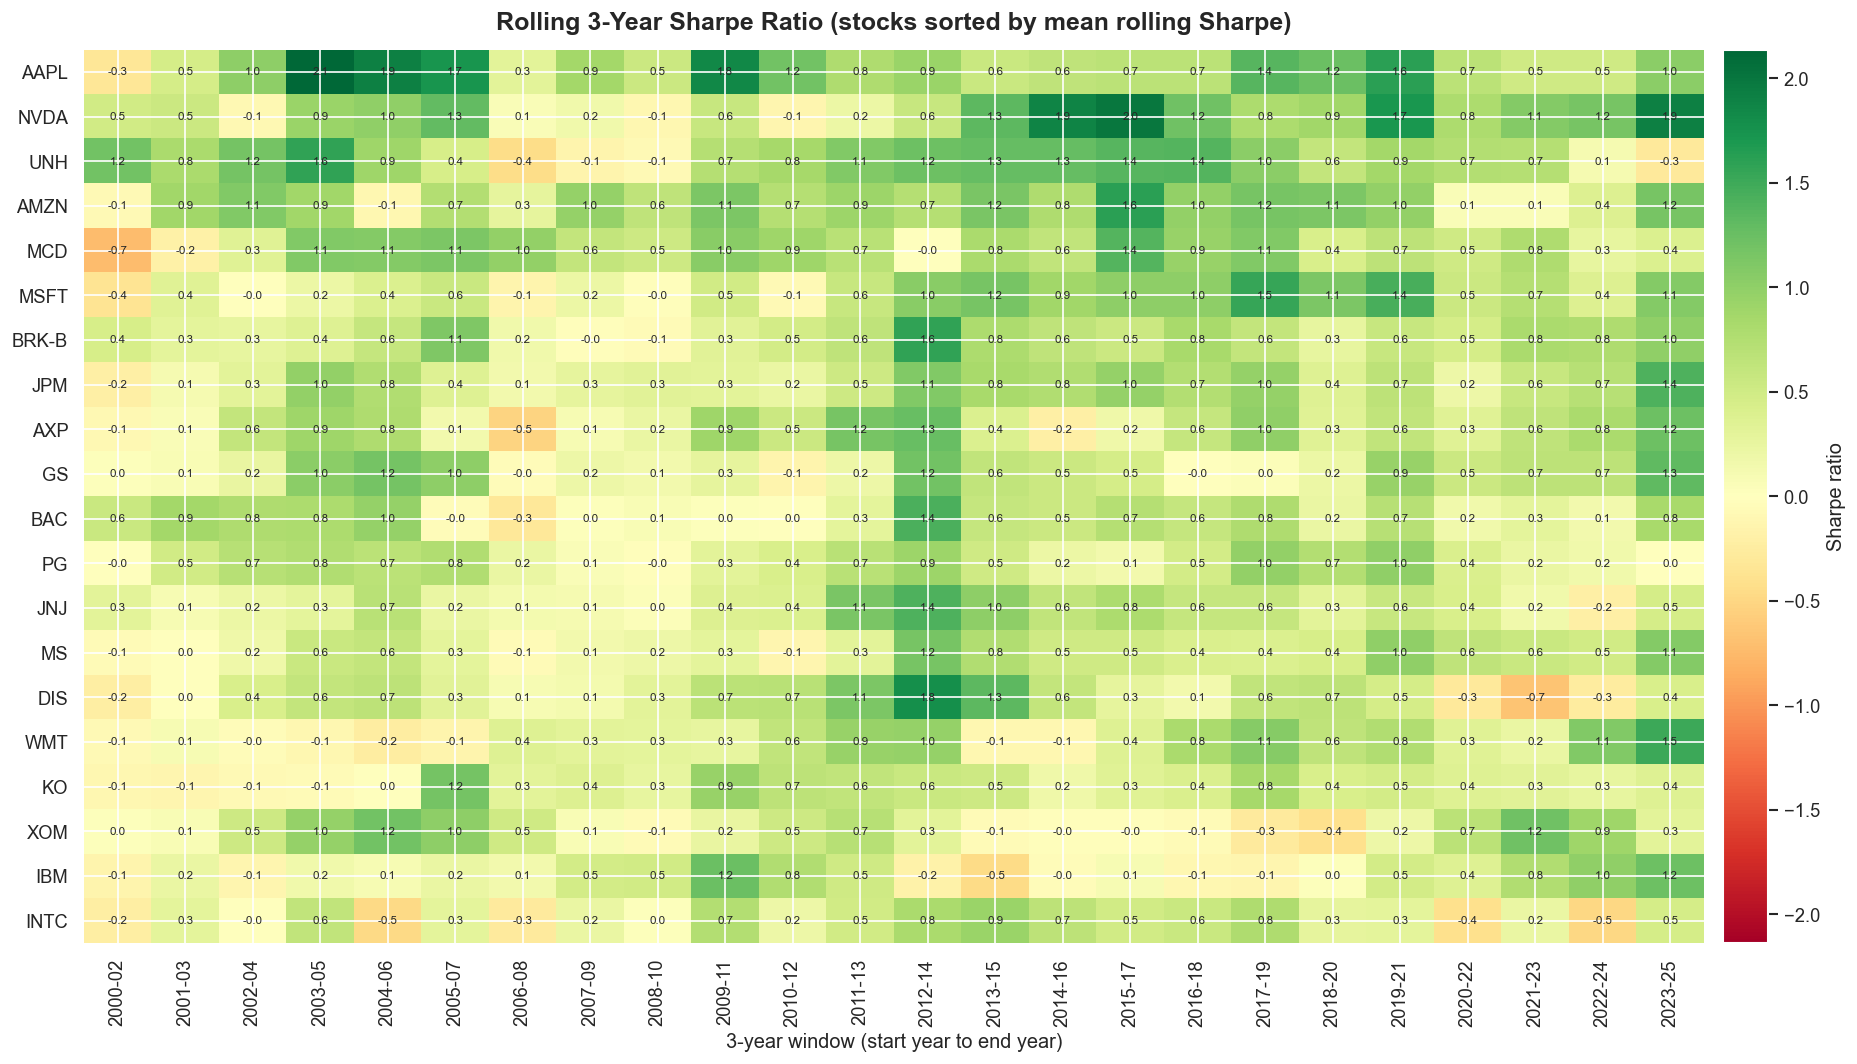

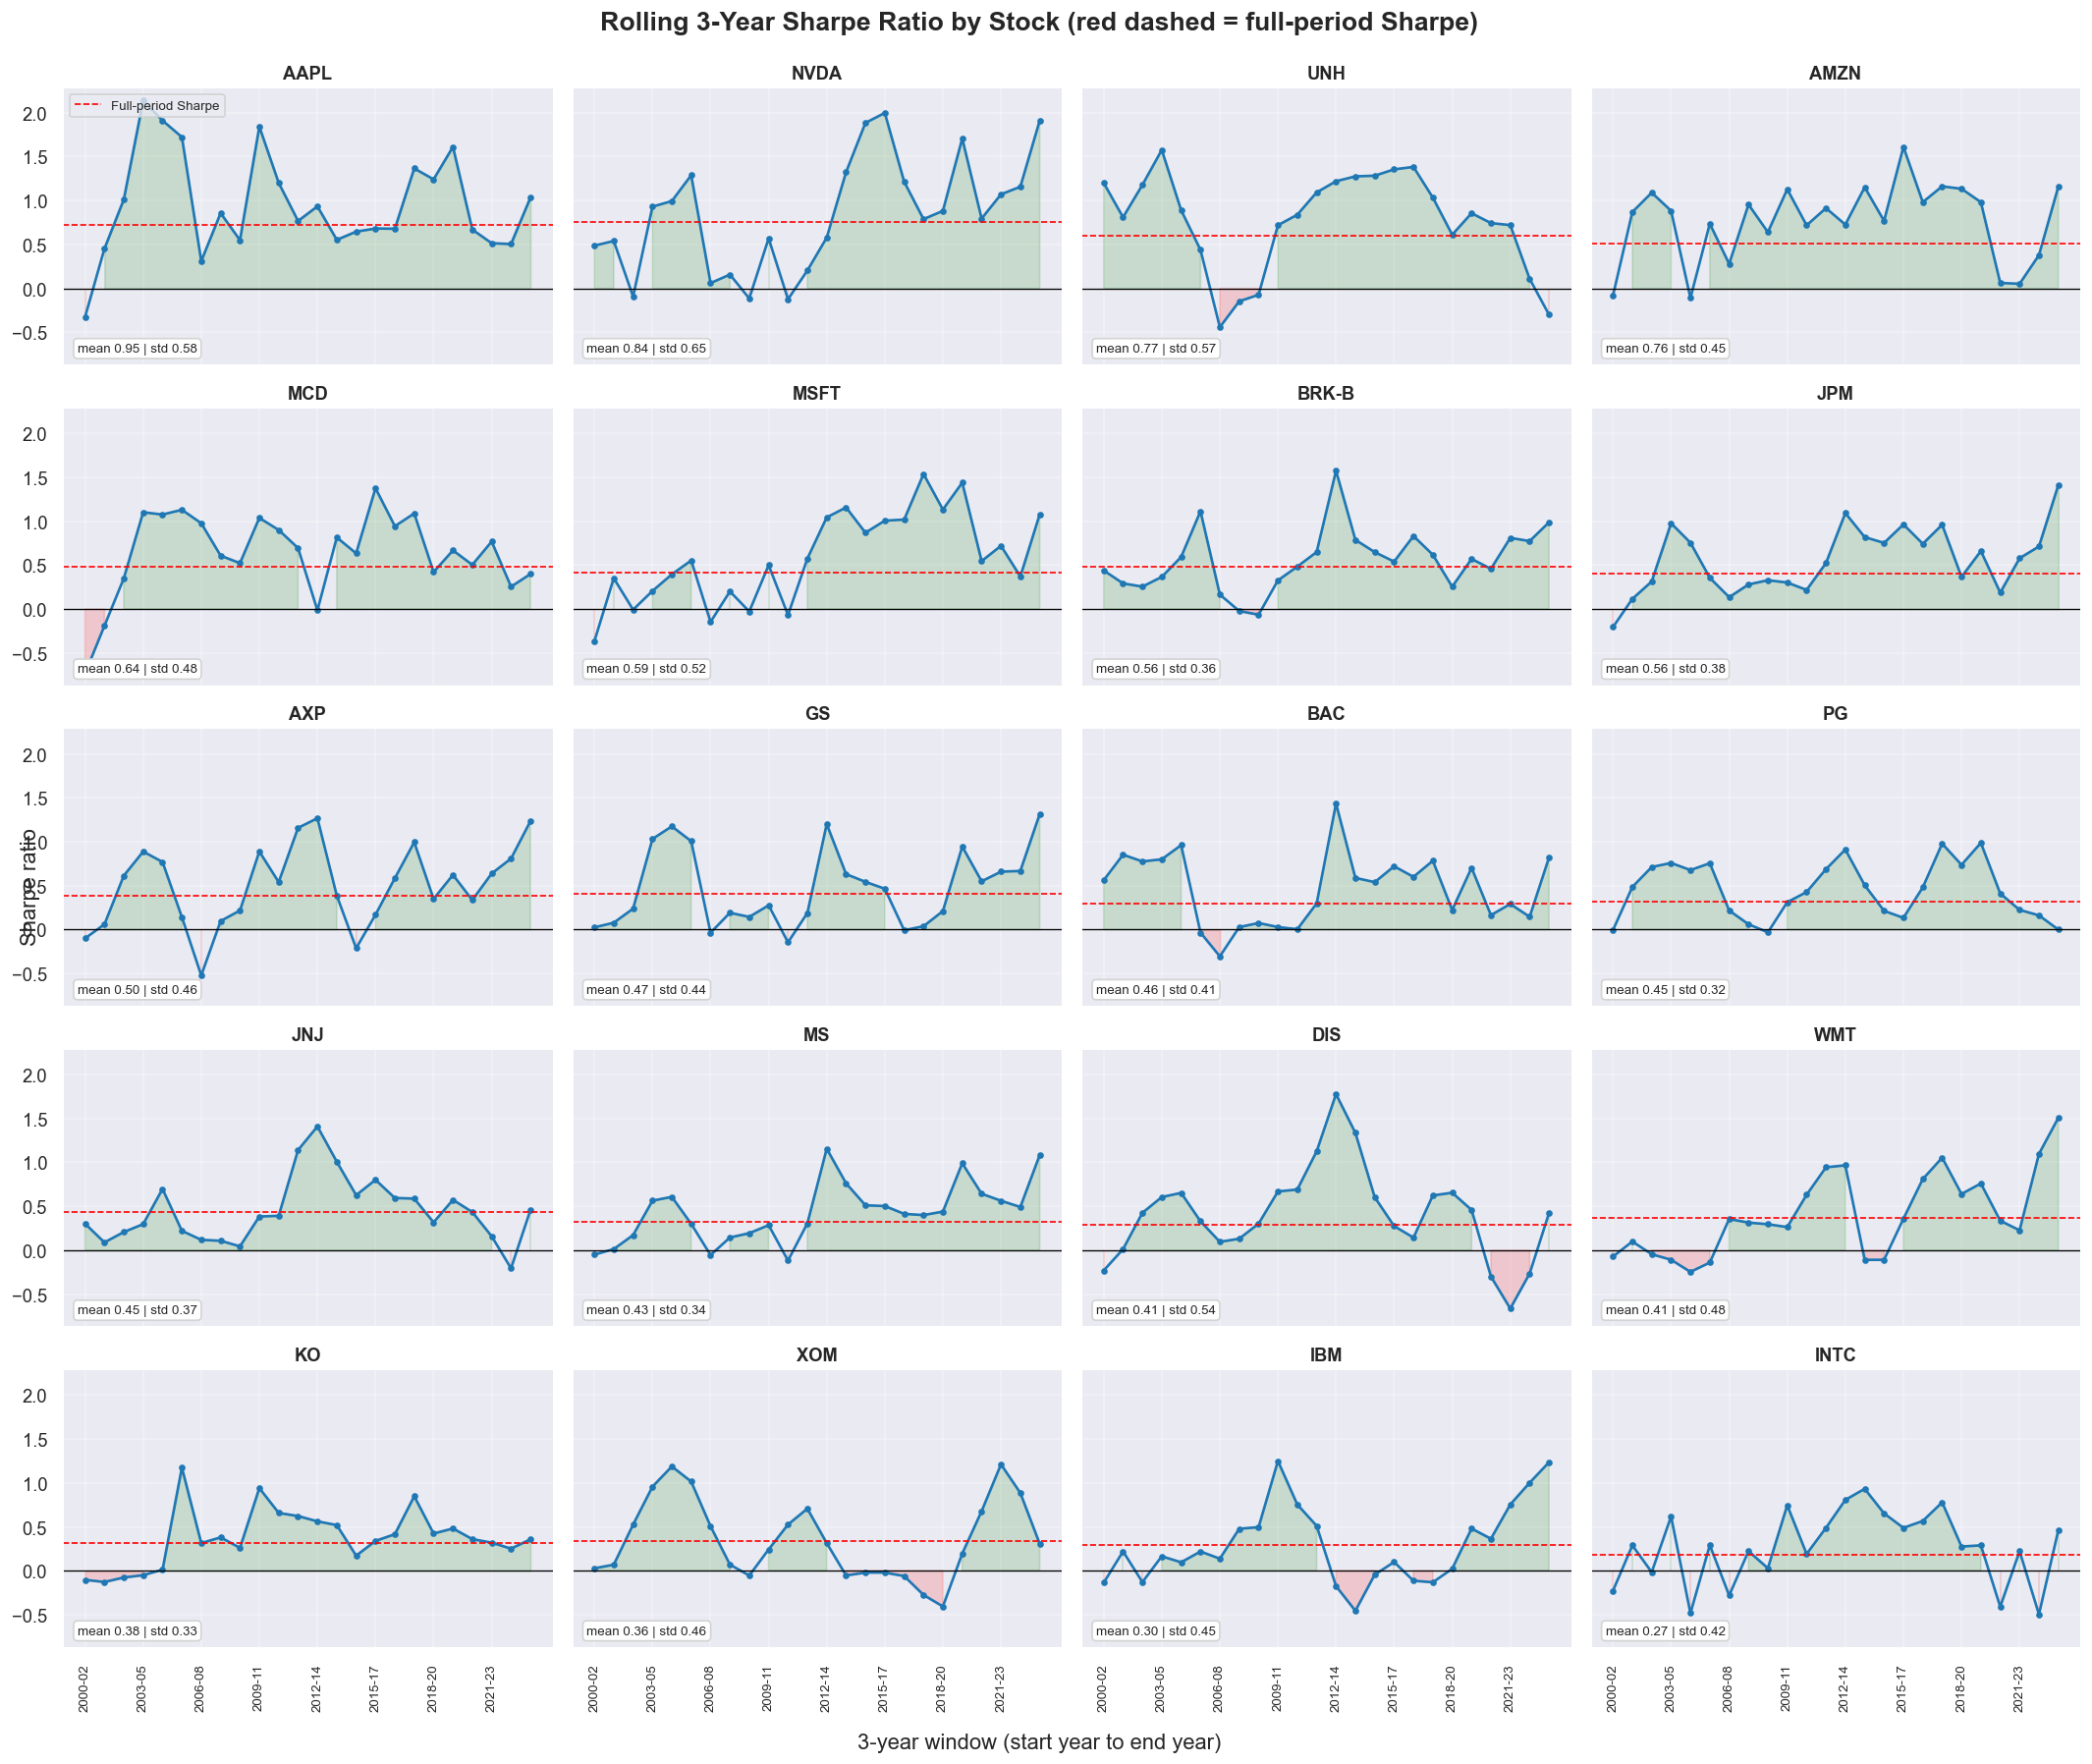

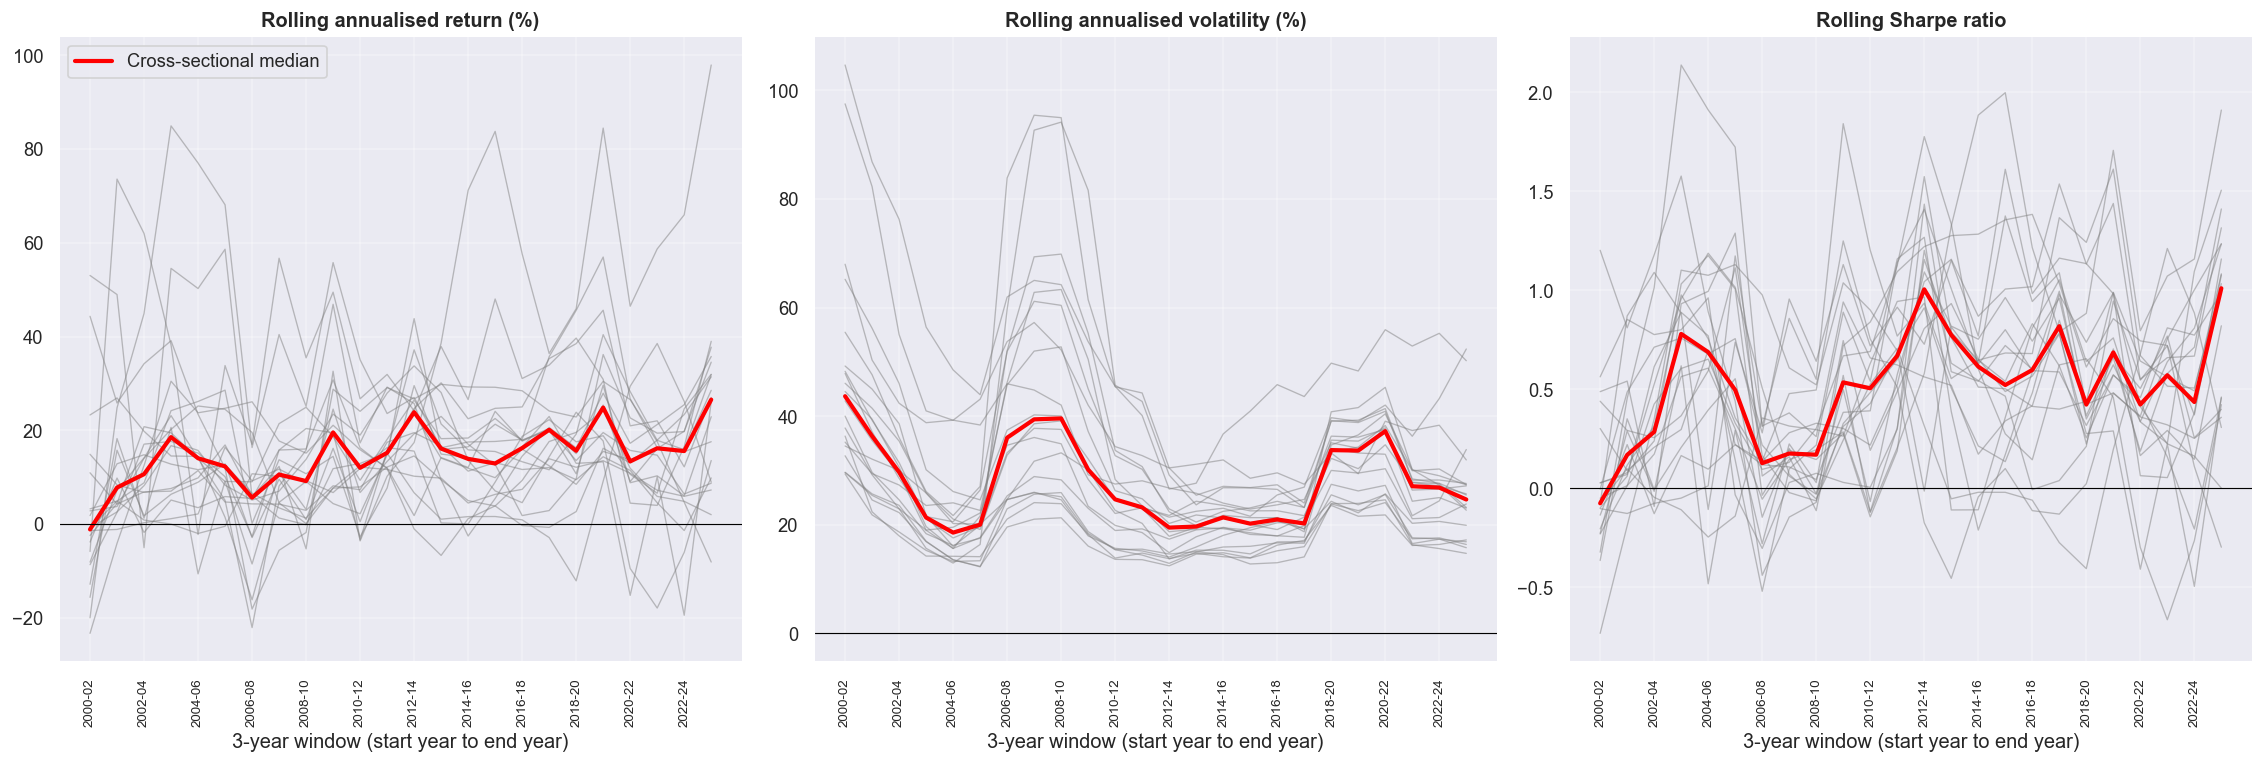

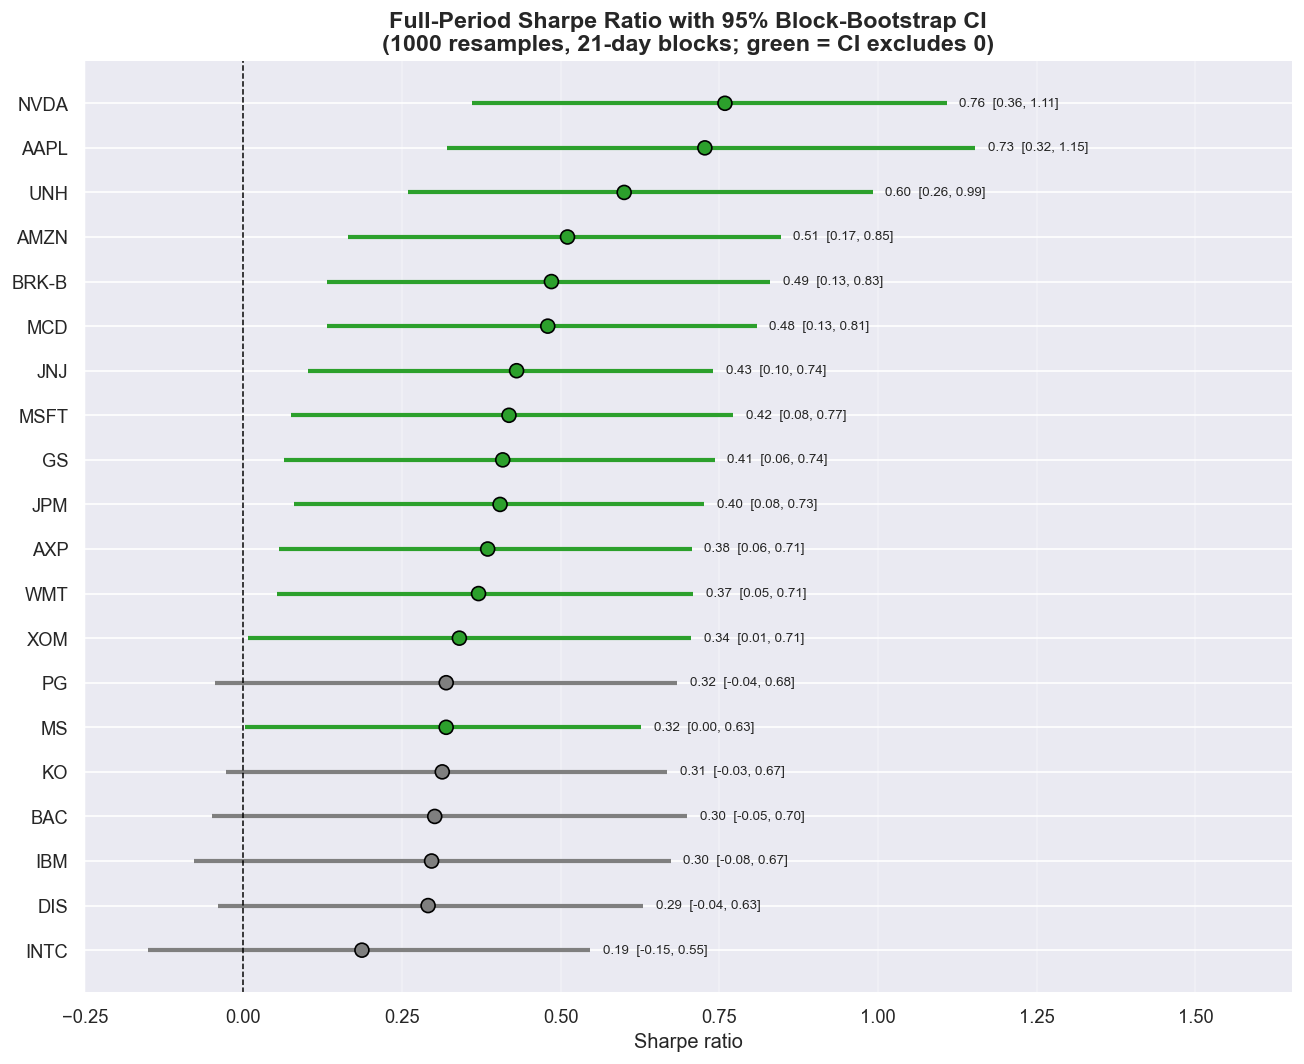

,Mean Rolling Sharpe,Std Rolling Sharpe,Min,Max,% Windows Sharpe > 0,Sharpe,CI Low (2.5%),CI High (97.5%),Significant (CI > 0)
AAPL,0.95,0.58,-0.32,2.14,95.83,0.73,0.32,1.15,True
NVDA,0.84,0.65,-0.12,2.00,87.50,0.76,0.36,1.11,True
UNH,0.77,0.57,-0.44,1.58,83.33,0.60,0.26,0.99,True
AMZN,0.76,0.45,-0.11,1.61,91.67,0.51,0.17,0.85,True
MCD,0.64,0.48,-0.73,1.37,87.50,0.48,0.13,0.81,True
MSFT,0.59,0.52,-0.37,1.54,79.17,0.42,0.08,0.77,True
BRK-B,0.56,0.36,-0.06,1.57,91.67,0.49,0.13,0.83,True
JPM,0.56,0.38,-0.21,1.41,95.83,0.40,0.08,0.73,True
AXP,0.50,0.46,-0.52,1.27,87.50,0.38,0.06,0.71,True
GS,0.47,0.44,-0.14,1.31,87.50,0.41,0.06,0.74,True


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# ----------------------------------------------------------------------
# Settings
# ----------------------------------------------------------------------
RF = 0.02               # annual risk-free rate (keep the same as cell 3)
TD = 252                # trading days per year
WINDOW_YEARS = 3        # rolling window length
N_BOOT = 1000           # bootstrap resamples
BLOCK = 21              # block length (~1 trading month) to preserve volatility clustering
SEED = 42

# ----------------------------------------------------------------------
# Load data saved by cell 1
# ----------------------------------------------------------------------
adj_close = pd.read_csv("us_stock_data/adj_close_wide.csv", index_col="Date", parse_dates=True)
returns = adj_close.pct_change(fill_method=None)

def sharpe_fn(r):
    return (r.mean() * TD - RF) / (r.std() * np.sqrt(TD))

def span_label(end_year):
    """Label a window by its full span, e.g. end year 2002 -> '2000-02'."""
    start_year = end_year - WINDOW_YEARS + 1
    return f"{start_year}-{str(end_year)[-2:]}"

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ======================================================================
# PART 1: Rolling 3-year windows, stepped yearly (window ends at each year-end)
# ======================================================================
end_years = range(returns.index[0].year + WINDOW_YEARS - 1, returns.index[-1].year + 1)
roll_sharpe, roll_ret, roll_vol = {}, {}, {}

for y in end_years:
    end = returns.index[returns.index.year == y].max()
    start = end - pd.DateOffset(years=WINDOW_YEARS)
    w = returns.loc[(returns.index > start) & (returns.index <= end)]
    enough = w.count() >= 0.8 * TD * WINDOW_YEARS          # need at least 80% of the window
    roll_ret[y] = pd.Series({t: w[t].mean() * TD if enough[t] else np.nan for t in w.columns})
    roll_vol[y] = pd.Series({t: w[t].std() * np.sqrt(TD) if enough[t] else np.nan for t in w.columns})
    roll_sharpe[y] = pd.Series({t: sharpe_fn(w[t].dropna()) if enough[t] else np.nan for t in w.columns})

roll_sharpe = pd.DataFrame(roll_sharpe)     # stocks x window-end-year
roll_ret = pd.DataFrame(roll_ret) * 100
roll_vol = pd.DataFrame(roll_vol) * 100

order = roll_sharpe.mean(axis=1).sort_values(ascending=False).index
roll_sharpe = roll_sharpe.loc[order]

# Window labels (full span) and x positions
win_labels = [span_label(y) for y in roll_sharpe.columns]
pos = np.arange(len(win_labels))

# ---------------- Figure 1: heatmap of rolling Sharpe ----------------
fig, ax = plt.subplots(figsize=(17, 9), dpi=120)
vmax = np.nanmax(np.abs(roll_sharpe.values))
im = ax.imshow(roll_sharpe.values, aspect="auto", cmap="RdYlGn",
               norm=TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax))
ax.set_xticks(pos)
ax.set_xticklabels(win_labels, rotation=90)
ax.set_yticks(range(len(roll_sharpe)))
ax.set_yticklabels(roll_sharpe.index)
for i in range(roll_sharpe.shape[0]):
    for j in range(roll_sharpe.shape[1]):
        v = roll_sharpe.iat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, pad=0.01, label="Sharpe ratio")
ax.set_xlabel(f"{WINDOW_YEARS}-year window (start year to end year)")
ax.set_title(f"Rolling {WINDOW_YEARS}-Year Sharpe Ratio (stocks sorted by mean rolling Sharpe)",
             fontsize=15, fontweight="bold", pad=12)
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout()
plt.savefig("rolling_sharpe_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------- Figure 2: rolling Sharpe small multiples ----------------
full_sharpe = returns.apply(lambda s: sharpe_fn(s.dropna()))
fig, axes = plt.subplots(5, 4, figsize=(18, 15), sharex=True, sharey=True, dpi=120)
for ax, t in zip(axes.flat, order):
    s = roll_sharpe.loc[t].values
    ax.plot(pos, s, color="#1f77b4", lw=1.6, marker="o", ms=3)
    ax.axhline(0, color="black", lw=0.8)
    ax.axhline(full_sharpe[t], color="red", ls="--", lw=1, label="Full-period Sharpe")
    ax.fill_between(pos, 0, s, where=(s >= 0), color="green", alpha=0.15)
    ax.fill_between(pos, 0, s, where=(s < 0), color="red", alpha=0.15)
    ax.set_title(t, fontsize=11, fontweight="bold")
    ax.text(0.03, 0.05, f"mean {np.nanmean(s):.2f} | std {np.nanstd(s, ddof=1):.2f}",
            transform=ax.transAxes, fontsize=8,
            bbox=dict(boxstyle="round", fc="white", ec="lightgrey"))
    ax.set_xticks(pos[::3])
    ax.set_xticklabels(win_labels[::3], rotation=90, fontsize=8)
    ax.grid(True, alpha=0.3)
axes.flat[0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"Rolling {WINDOW_YEARS}-Year Sharpe Ratio by Stock (red dashed = full-period Sharpe)",
             fontsize=16, fontweight="bold", y=0.995)
fig.supxlabel(f"{WINDOW_YEARS}-year window (start year to end year)")
fig.supylabel("Sharpe ratio")
plt.tight_layout()
plt.savefig("rolling_sharpe_small_multiples.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------------- Figure 3: stability of return / volatility / Sharpe over time ----------------
fig, axes = plt.subplots(1, 3, figsize=(19, 6.5), dpi=120)
for a, (df, title) in zip(axes, [(roll_ret, "Rolling annualised return (%)"),
                                 (roll_vol, "Rolling annualised volatility (%)"),
                                 (roll_sharpe, "Rolling Sharpe ratio")]):
    for t in df.index:
        a.plot(pos, df.loc[t].values, color="grey", lw=0.8, alpha=0.5)
    a.plot(pos, df.median().values, color="red", lw=2.5, label="Cross-sectional median")
    a.axhline(0, color="black", lw=0.7)
    a.set_title(title, fontweight="bold")
    a.set_xticks(pos[::2])
    a.set_xticklabels(win_labels[::2], rotation=90, fontsize=8)
    a.set_xlabel(f"{WINDOW_YEARS}-year window (start year to end year)")
    a.grid(True, alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig("rolling_ret_vol_sharpe.png", dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# PART 2: Block-bootstrap confidence intervals for the full-period Sharpe ratio
# ======================================================================
rng = np.random.default_rng(SEED)

def block_bootstrap_sharpe(r, n_boot, block, rng):
    """Circular block bootstrap of daily returns; returns the distribution of Sharpe ratios."""
    r = r.dropna().values
    n = len(r)
    n_blocks = int(np.ceil(n / block))
    starts = rng.integers(0, n, size=(n_boot, n_blocks))
    idx = ((starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n]) % n
    samp = r[idx]
    return (samp.mean(axis=1) * TD - RF) / (samp.std(axis=1, ddof=1) * np.sqrt(TD))

boot_rows = {}
for t in returns.columns:
    dist = block_bootstrap_sharpe(returns[t], N_BOOT, BLOCK, rng)
    boot_rows[t] = {"Sharpe": full_sharpe[t],
                    "CI Low (2.5%)": np.percentile(dist, 2.5),
                    "CI High (97.5%)": np.percentile(dist, 97.5)}
boot = pd.DataFrame(boot_rows).T.sort_values("Sharpe")
boot["Significant (CI > 0)"] = boot["CI Low (2.5%)"] > 0

# ---------------- Figure 4: forest plot ----------------
fig, ax = plt.subplots(figsize=(11, 9), dpi=120)
y = np.arange(len(boot))
colors = np.where(boot["Significant (CI > 0)"], "#2ca02c", "#7f7f7f")
ax.hlines(y, boot["CI Low (2.5%)"], boot["CI High (97.5%)"], color=colors, lw=2.5)
ax.scatter(boot["Sharpe"], y, color=colors, s=70, zorder=3, edgecolor="black")
ax.axvline(0, color="black", lw=0.9, ls="--")
ax.set_yticks(y)
ax.set_yticklabels(boot.index)
for yi, (lo, hi, sh) in enumerate(zip(boot["CI Low (2.5%)"], boot["CI High (97.5%)"], boot["Sharpe"])):
    ax.text(hi + 0.02, yi, f"{sh:.2f}  [{lo:.2f}, {hi:.2f}]", va="center", fontsize=8)
ax.set_xlim(boot["CI Low (2.5%)"].min() - 0.1, boot["CI High (97.5%)"].max() + 0.5)
ax.set_xlabel("Sharpe ratio")
ax.set_title(f"Full-Period Sharpe Ratio with 95% Block-Bootstrap CI\n"
             f"({N_BOOT} resamples, {BLOCK}-day blocks; green = CI excludes 0)",
             fontsize=14, fontweight="bold")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("sharpe_bootstrap_ci.png", dpi=300, bbox_inches="tight")
plt.show()

# ======================================================================
# Summary tables
# ======================================================================
stability = pd.DataFrame({
    "Mean Rolling Sharpe": roll_sharpe.mean(axis=1),
    "Std Rolling Sharpe": roll_sharpe.std(axis=1),
    "Min": roll_sharpe.min(axis=1),
    "Max": roll_sharpe.max(axis=1),
    "% Windows Sharpe > 0": (roll_sharpe > 0).sum(axis=1) / roll_sharpe.count(axis=1) * 100,
})
summary = stability.join(boot).sort_values("Mean Rolling Sharpe", ascending=False).round(2)
summary

20 stocks | 2000-01-04 to 2025-12-31 | 6538 daily observations


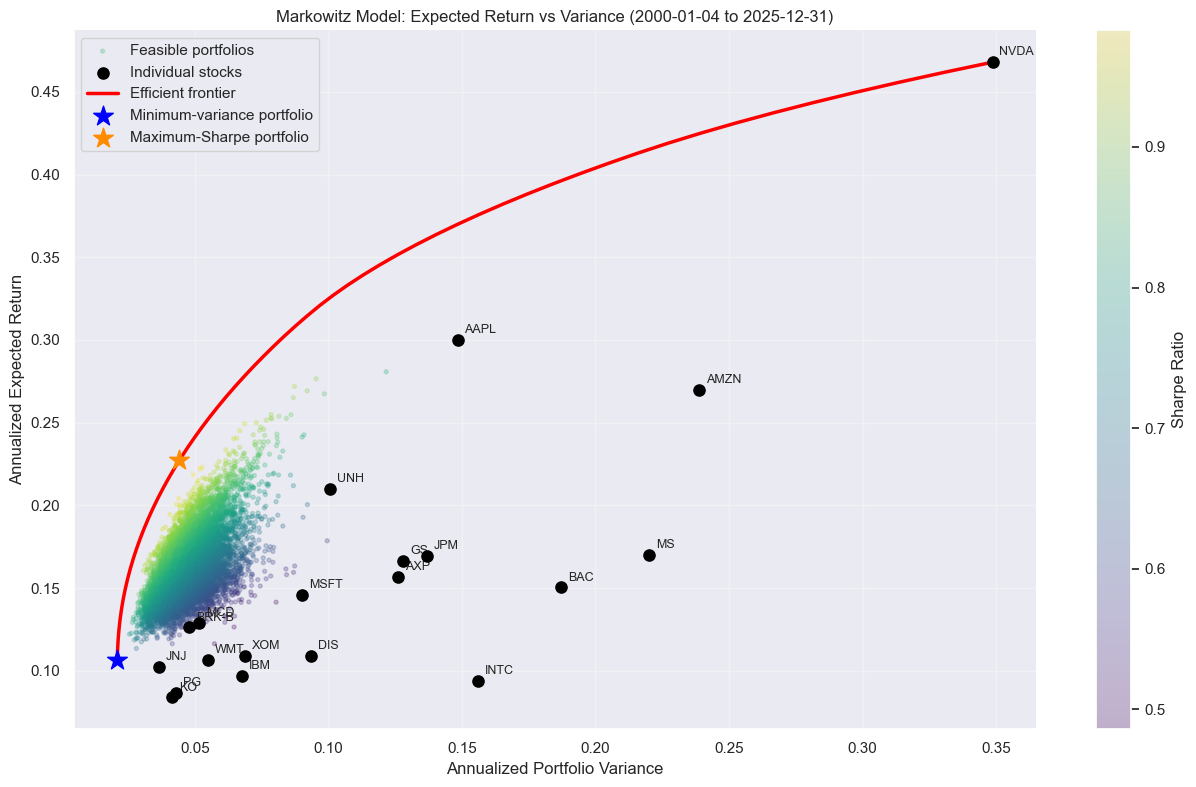

Individual stock statistics:


,Expected Return (%),Variance,Volatility (%)
NVDA,46.7991,0.3486,59.0466
AAPL,30.0030,0.1483,38.5158
AMZN,26.9526,0.2388,48.8677
UNH,21.0171,0.1005,31.7003
MS,16.9816,0.2199,46.8986
JPM,16.9556,0.1368,36.9836
GS,16.6120,0.1279,35.7646
AXP,15.6572,0.1259,35.4864
BAC,15.0344,0.1870,43.2429
MSFT,14.5550,0.0900,30.0046


Optimized portfolio statistics:


,Portfolio,Expected Return (%),Variance,Volatility (%),Sharpe Ratio
0,Minimum variance,10.6308,0.0210,14.4868,0.7338
1,Maximum Sharpe,22.7163,0.0442,21.0181,1.0808


Optimized portfolio weights (only stocks with weight > 0.01%):


,Minimum-variance weight (%),Maximum-Sharpe weight (%)
UNH,0.00,19.79
AAPL,0.07,17.79
JNJ,23.93,15.72
NVDA,0.00,15.20
MCD,12.18,13.47
BRK-B,16.98,9.70
AMZN,0.51,4.19
WMT,12.50,2.36
PG,13.05,1.78
IBM,5.03,0.00


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# ----------------------------------------------------------------------
# Settings
# ----------------------------------------------------------------------
ANALYSIS_START = "2000-01-01"   # change to "2025-01-01" to reproduce your one-year version
ANALYSIS_END   = "2026-01-01"
TD = 252
N_RANDOM = 10000
N_FRONTIER = 60
RF = 0.0                        # risk-free rate for max-Sharpe (0 to match your original code)

# ----------------------------------------------------------------------
# Load data saved by cell 1
# ----------------------------------------------------------------------
prices = pd.read_csv("us_stock_data/adj_close_wide.csv", index_col="Date", parse_dates=True)
prices = prices.loc[ANALYSIS_START:ANALYSIS_END].sort_index()

daily_returns = prices.pct_change(fill_method=None).dropna(how="all")
daily_returns = daily_returns.dropna(axis=1, how="all")
daily_returns = daily_returns.dropna()          # same dates for every stock

assets = list(daily_returns.columns)
n = len(assets)
returns_array = (daily_returns.mean() * TD).to_numpy()
covariance_array = (daily_returns.cov() * TD).to_numpy()
print(f"{n} stocks | {daily_returns.index[0].date()} to {daily_returns.index[-1].date()} "
      f"| {len(daily_returns)} daily observations")

# ----------------------------------------------------------------------
# Portfolio functions and constraints (long-only, fully invested)
# ----------------------------------------------------------------------
def port_return(w):
    return float(w @ returns_array)

def port_variance(w):
    return float(w @ covariance_array @ w)

def port_vol(w):
    return np.sqrt(max(port_variance(w), 0.0))

def neg_sharpe(w):
    v = port_vol(w)
    return -(port_return(w) - RF) / v if v > 0 else 0.0

budget = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0}
bounds = tuple((0.0, 1.0) for _ in range(n))
w0 = np.full(n, 1.0 / n)

# ----------------------------------------------------------------------
# Minimum-variance and maximum-Sharpe portfolios
# ----------------------------------------------------------------------
res_minvar = minimize(port_variance, w0, method="SLSQP", bounds=bounds,
                      constraints=(budget,), options={"maxiter": 1000, "ftol": 1e-12})
if not res_minvar.success:
    raise RuntimeError(f"Minimum-variance optimization failed: {res_minvar.message}")
w_minvar = res_minvar.x
ret_minvar, var_minvar = port_return(w_minvar), port_variance(w_minvar)

res_maxsh = minimize(neg_sharpe, w0, method="SLSQP", bounds=bounds,
                     constraints=(budget,), options={"maxiter": 1000, "ftol": 1e-12})
if not res_maxsh.success:
    raise RuntimeError(f"Maximum-Sharpe optimization failed: {res_maxsh.message}")
w_maxsh = res_maxsh.x
ret_maxsh, var_maxsh = port_return(w_maxsh), port_variance(w_maxsh)
sharpe_maxsh = (ret_maxsh - RF) / np.sqrt(var_maxsh)

# ----------------------------------------------------------------------
# Efficient frontier (fix target return, minimise variance)
# ----------------------------------------------------------------------
targets = np.linspace(ret_minvar, float(returns_array.max()), N_FRONTIER)
f_ret, f_var = [], []
for tr in targets:
    cons = (budget,
            {"type": "eq", "fun": lambda w, tr=tr: port_return(w) - tr})
    r = minimize(port_variance, w0, method="SLSQP", bounds=bounds, constraints=cons,
                 options={"maxiter": 1000, "ftol": 1e-12})
    if r.success:
        f_ret.append(port_return(r.x))
        f_var.append(port_variance(r.x))
f_ret, f_var = np.asarray(f_ret), np.asarray(f_var)

# ----------------------------------------------------------------------
# Random long-only portfolios (feasible set)
# ----------------------------------------------------------------------
rng = np.random.default_rng(42)
rw = rng.dirichlet(np.ones(n), size=N_RANDOM)
r_ret = rw @ returns_array
r_var = np.einsum("ij,jk,ik->i", rw, covariance_array, rw)
r_sharpe = (r_ret - RF) / np.sqrt(np.maximum(r_var, 1e-15))

# ----------------------------------------------------------------------
# Plot: expected return vs variance
# ----------------------------------------------------------------------
plt.figure(figsize=(13, 8))
sc = plt.scatter(r_var, r_ret, c=r_sharpe, cmap="viridis", s=8, alpha=0.25,
                 label="Feasible portfolios")
plt.scatter(np.diag(covariance_array), returns_array, color="black", s=65, zorder=4,
            label="Individual stocks")
for name, v, r in zip(assets, np.diag(covariance_array), returns_array):
    plt.annotate(name, (v, r), xytext=(5, 5), textcoords="offset points", fontsize=9)

if len(f_var) > 0:
    o = np.argsort(f_var)
    plt.plot(f_var[o], f_ret[o], color="red", lw=2.5, label="Efficient frontier")

plt.scatter(var_minvar, ret_minvar, color="blue", marker="*", s=220, zorder=5,
            label="Minimum-variance portfolio")
plt.scatter(var_maxsh, ret_maxsh, color="darkorange", marker="*", s=220, zorder=5,
            label="Maximum-Sharpe portfolio")

plt.xlabel("Annualized Portfolio Variance")
plt.ylabel("Annualized Expected Return")
plt.title(f"Markowitz Model: Expected Return vs Variance "
          f"({daily_returns.index[0].date()} to {daily_returns.index[-1].date()})")
plt.colorbar(sc, label="Sharpe Ratio")
plt.grid(True, alpha=0.3)
plt.legend(loc="best")
plt.tight_layout()
plt.savefig("markowitz_frontier.png", dpi=300, bbox_inches="tight")
plt.show()

# ----------------------------------------------------------------------
# Tables
# ----------------------------------------------------------------------
ind_stats = pd.DataFrame({
    "Expected Return (%)": returns_array * 100,
    "Variance": np.diag(covariance_array),
    "Volatility (%)": np.sqrt(np.diag(covariance_array)) * 100,
}, index=assets).sort_values("Expected Return (%)", ascending=False)

port_stats = pd.DataFrame({
    "Portfolio": ["Minimum variance", "Maximum Sharpe"],
    "Expected Return (%)": [ret_minvar * 100, ret_maxsh * 100],
    "Variance": [var_minvar, var_maxsh],
    "Volatility (%)": [np.sqrt(var_minvar) * 100, np.sqrt(var_maxsh) * 100],
    "Sharpe Ratio": [(ret_minvar - RF) / np.sqrt(var_minvar), sharpe_maxsh],
})

weights = pd.DataFrame({
    "Minimum-variance weight (%)": w_minvar * 100,
    "Maximum-Sharpe weight (%)": w_maxsh * 100,
}, index=assets)
weights = weights[(weights > 0.01).any(axis=1)].sort_values("Maximum-Sharpe weight (%)", ascending=False)

print("Individual stock statistics:")
display(ind_stats.round(4))
print("Optimized portfolio statistics:")
display(port_stats.round(4))
print("Optimized portfolio weights (only stocks with weight > 0.01%):")
display(weights.round(2))

20 stocks | 2000-01-04 to 2025-12-31 | 6538 daily returns (0 rows dropped for missing values)


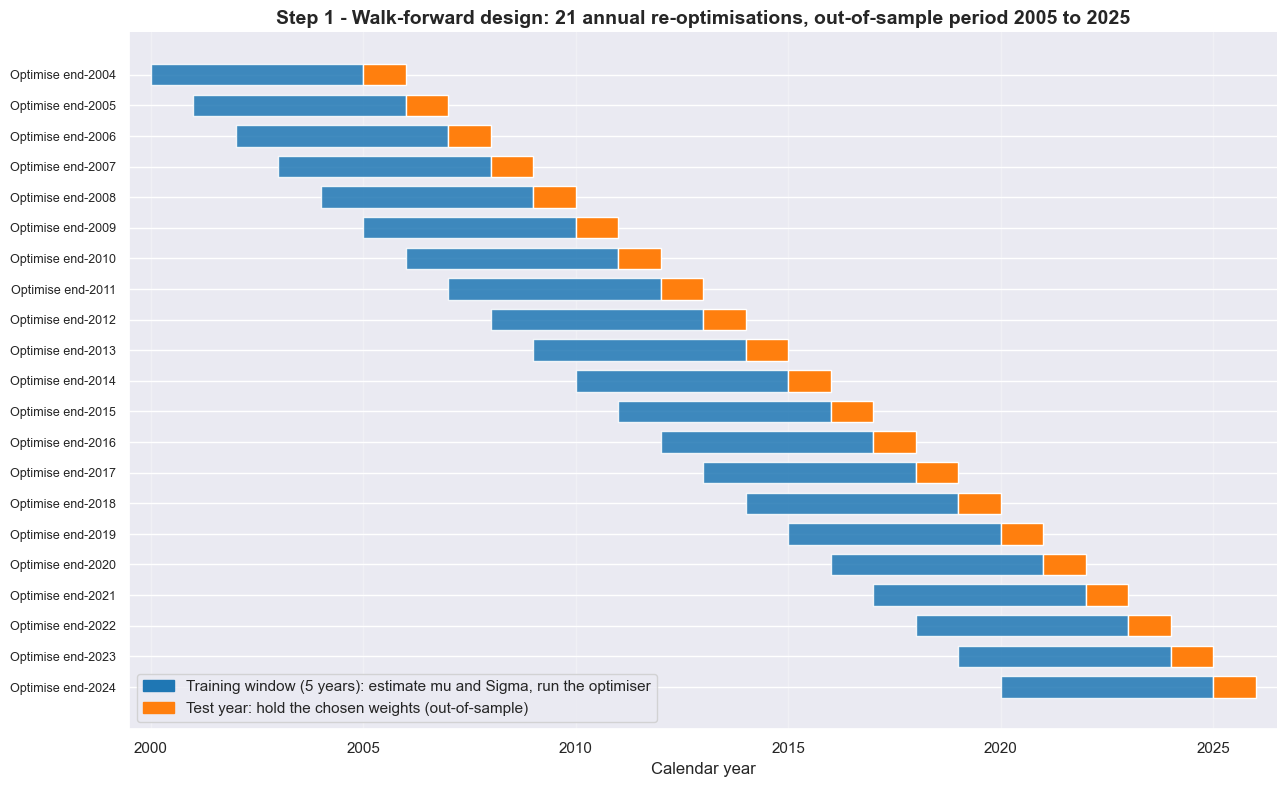

Training window   : 5 years (about 1260 daily observations for 20 stocks)
Rebalancing       : once a year, at the last trading day of each year
Out-of-sample span: 2005 to 2025 (21 test years)
Weight cap        : 20% per stock | transaction cost: 10 bps per unit traded


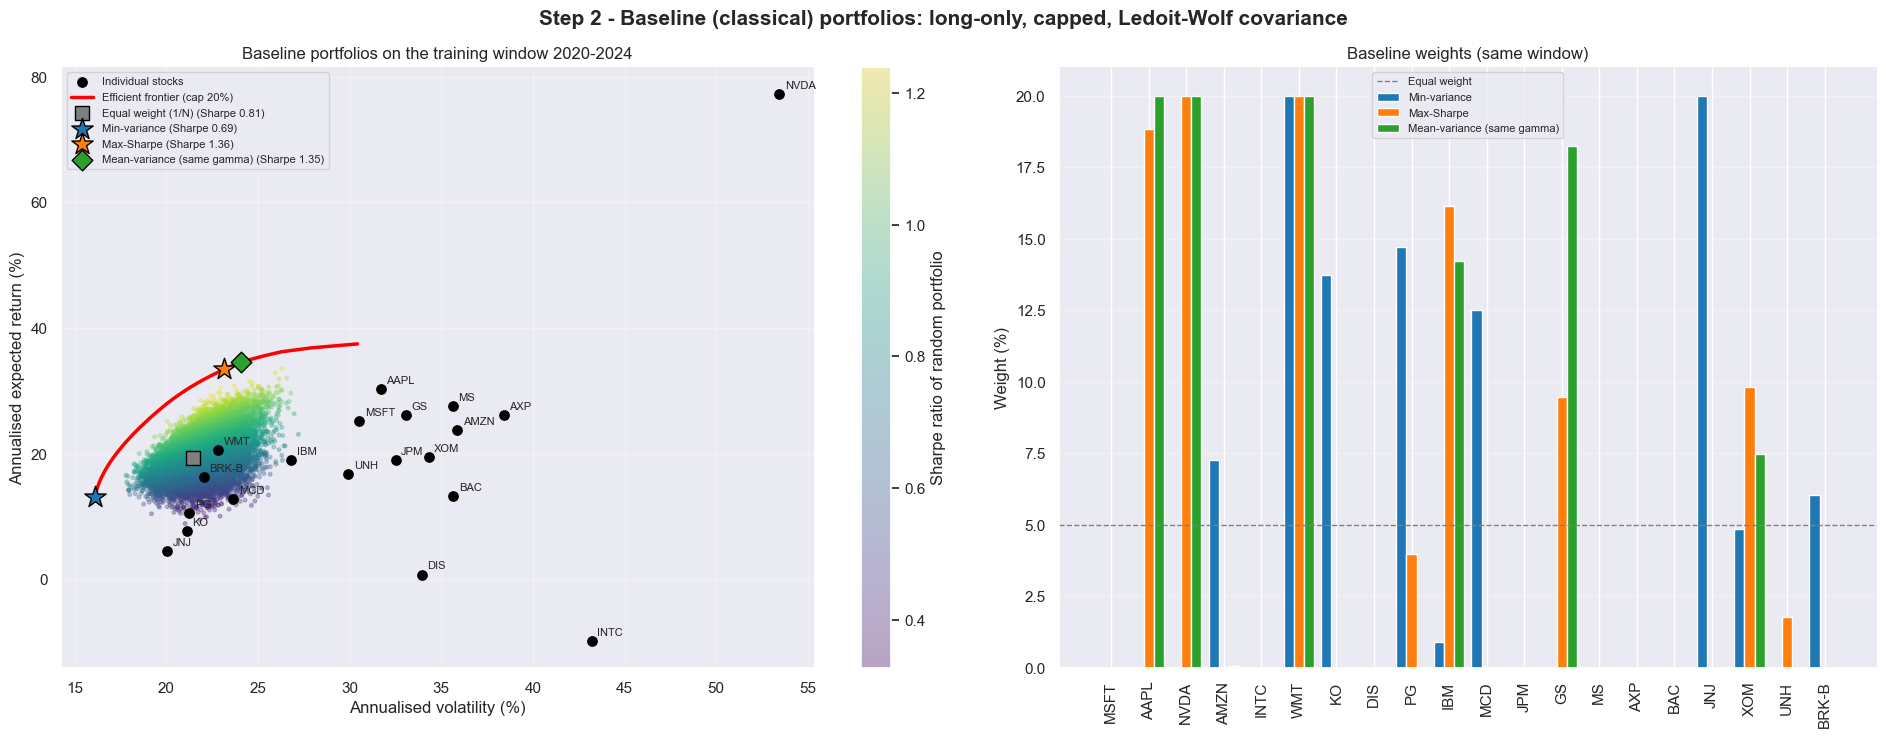

In-sample statistics of the baselines (training window ending 2024; Ledoit-Wolf shrinkage = 0.023):


,Exp. return (%),Volatility (%),Sharpe,Stocks held (>0.5%),Largest weight (%)
EW,19.363,21.458,0.809,20,5.0
MinVar,13.038,16.112,0.685,9,20.0
MaxSharpe,33.422,23.152,1.357,8,20.0
MeanVar,34.553,24.090,1.351,6,20.0


Check passed: QUBO energy == mean-variance objective + penalty for 200 random bit strings (both formulations).

QUBO-W : 20 stocks x 3 bits = 60 binary variables | bit weights (in units of 5.0% ) = [1, 2, 1] | max weight per stock = 20%
QUBO-S : 20 binary variables (1 = stock selected), exactly K = 8 stocks, equal weights 1/K
Penalty strengths  P(W) = 30.88 | P(S) = 0.19


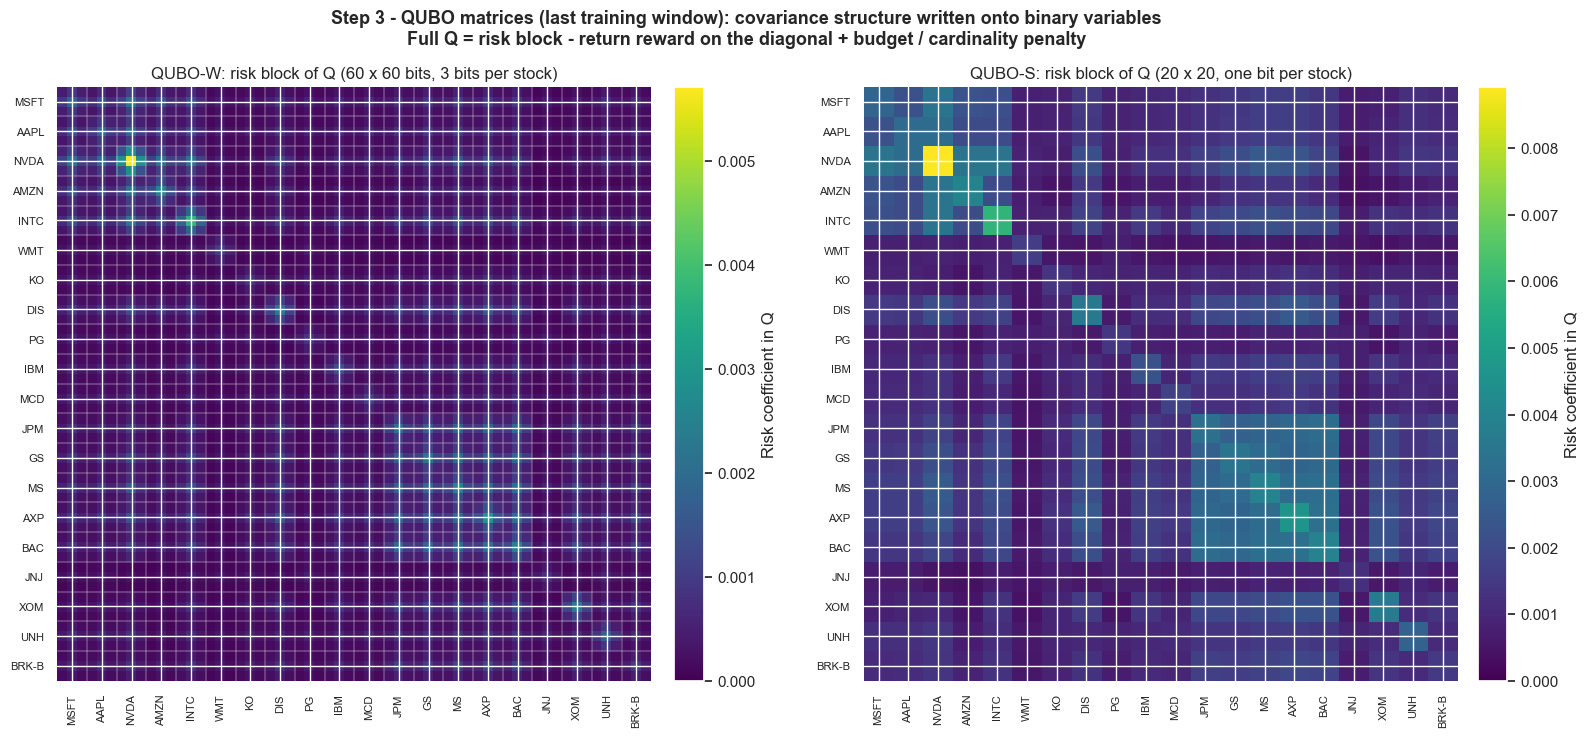

Solved 21 training windows in 48 s (128 chains x 150 sweeps per QUBO)



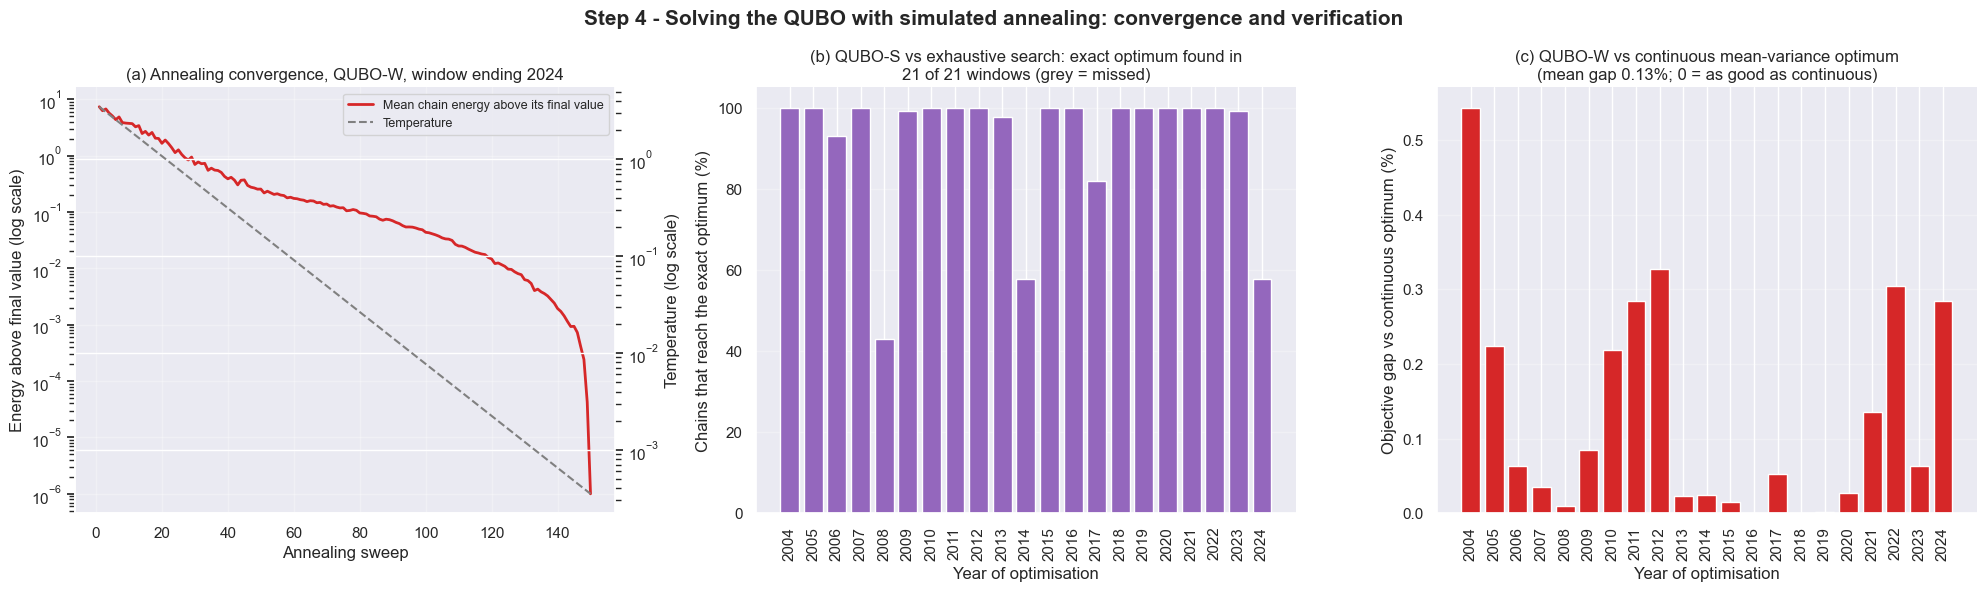

,Solver diagnostics
QUBO-W: chains ending budget-feasible (%),100.0
QUBO-W: mean gap vs continuous (%),0.129702
QUBO-S: chains ending cardinality-feasible (%),100.0
QUBO-S: windows where exact optimum found,21/21
QUBO-S: mean chain hit-rate (%),91.889881


Walk-forward finished in 0 s | out-of-sample 2005-01-03 to 2025-12-31 (5283 trading days, 21 annual rebalances)

Out-of-sample performance after transaction costs (10 bps per unit traded), risk-free rate 2%:


,CAGR (%),Ann. return (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Calmar,Final wealth (x),Avg annual turnover (%),Avg stocks held (>0.5%),Avg largest weight (%),Effective N (1/sum w^2)
EW,16.663,17.372,19.774,0.777,1.116,-49.557,0.336,25.304,9.288,20.000,5.00,20.000
MinVar,10.098,10.662,14.419,0.601,0.855,-38.316,0.264,7.514,10.953,8.905,19.85,6.699
MaxSharpe,19.190,19.523,19.805,0.885,1.277,-42.940,0.447,39.654,30.964,7.333,20.00,5.900
MeanVar,20.590,21.230,22.355,0.860,1.243,-53.149,0.387,50.659,32.312,6.571,20.00,5.506
QUBO-W,20.397,21.076,22.389,0.852,1.231,-52.832,0.386,48.981,32.290,6.286,20.00,5.546
QUBO-S,20.838,21.045,20.541,0.927,1.341,-54.505,0.382,52.882,29.167,8.000,12.50,8.000


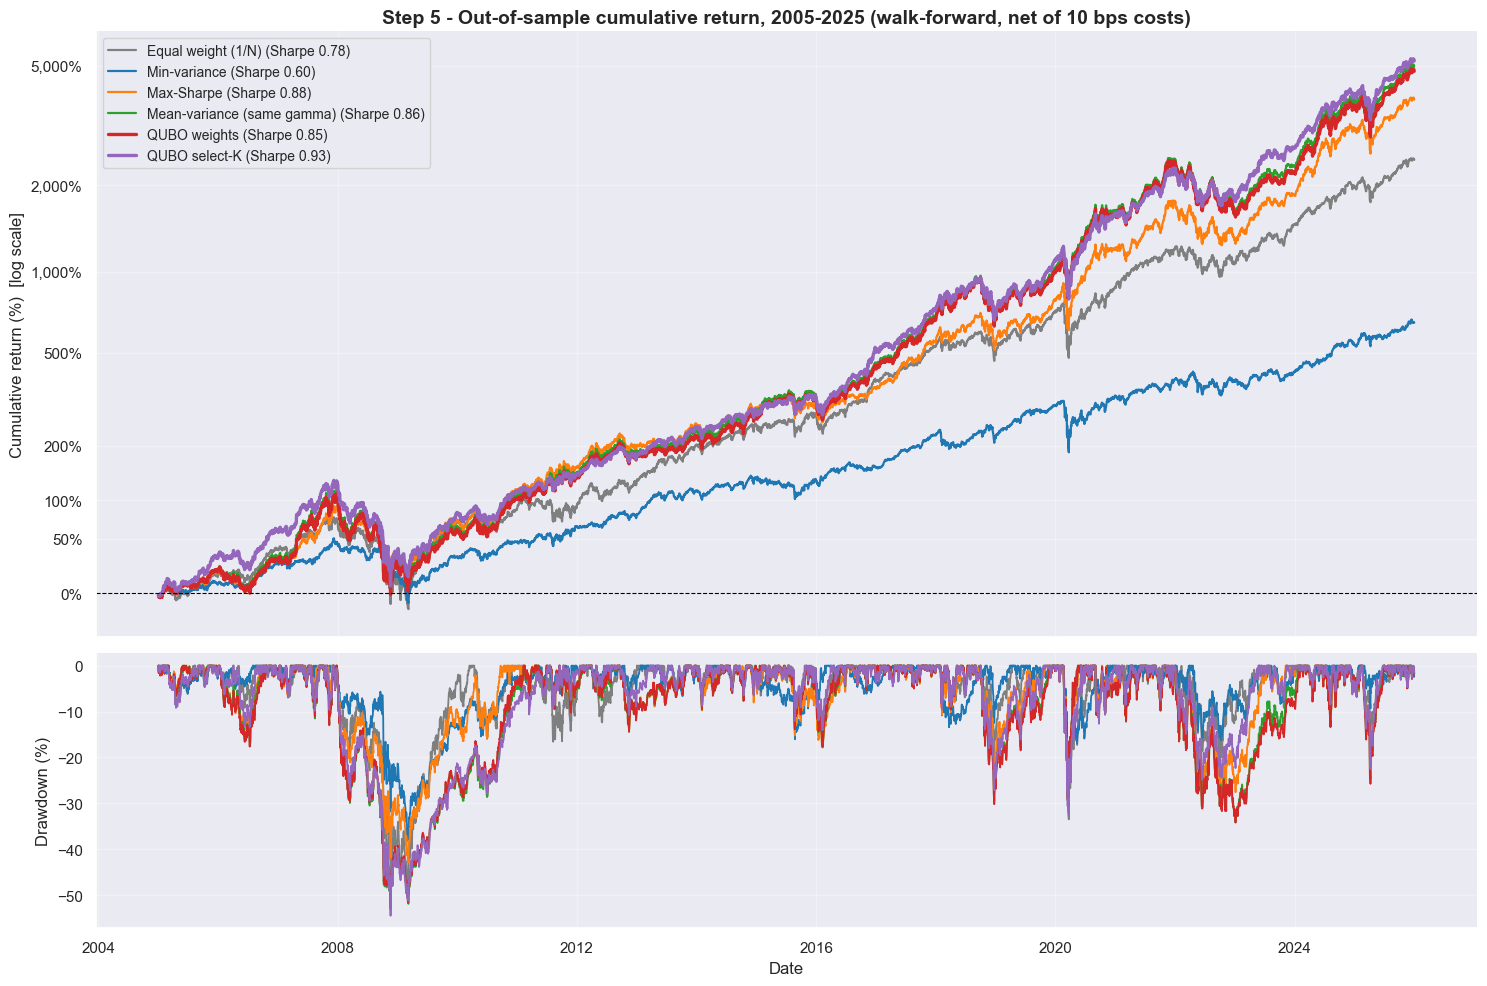

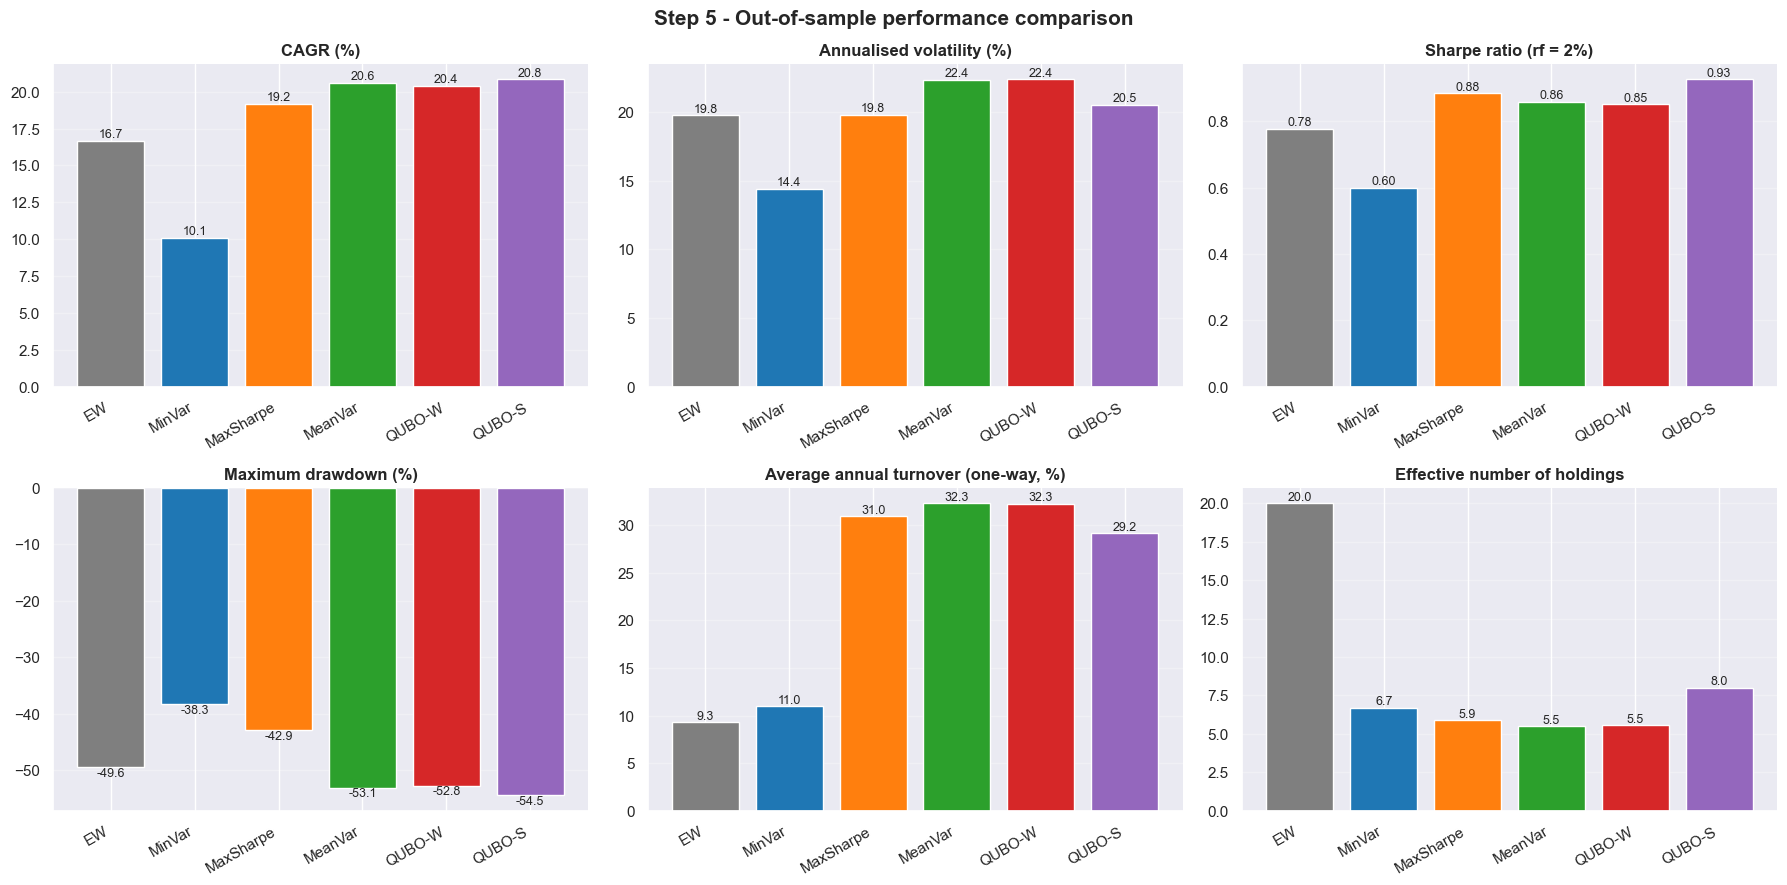

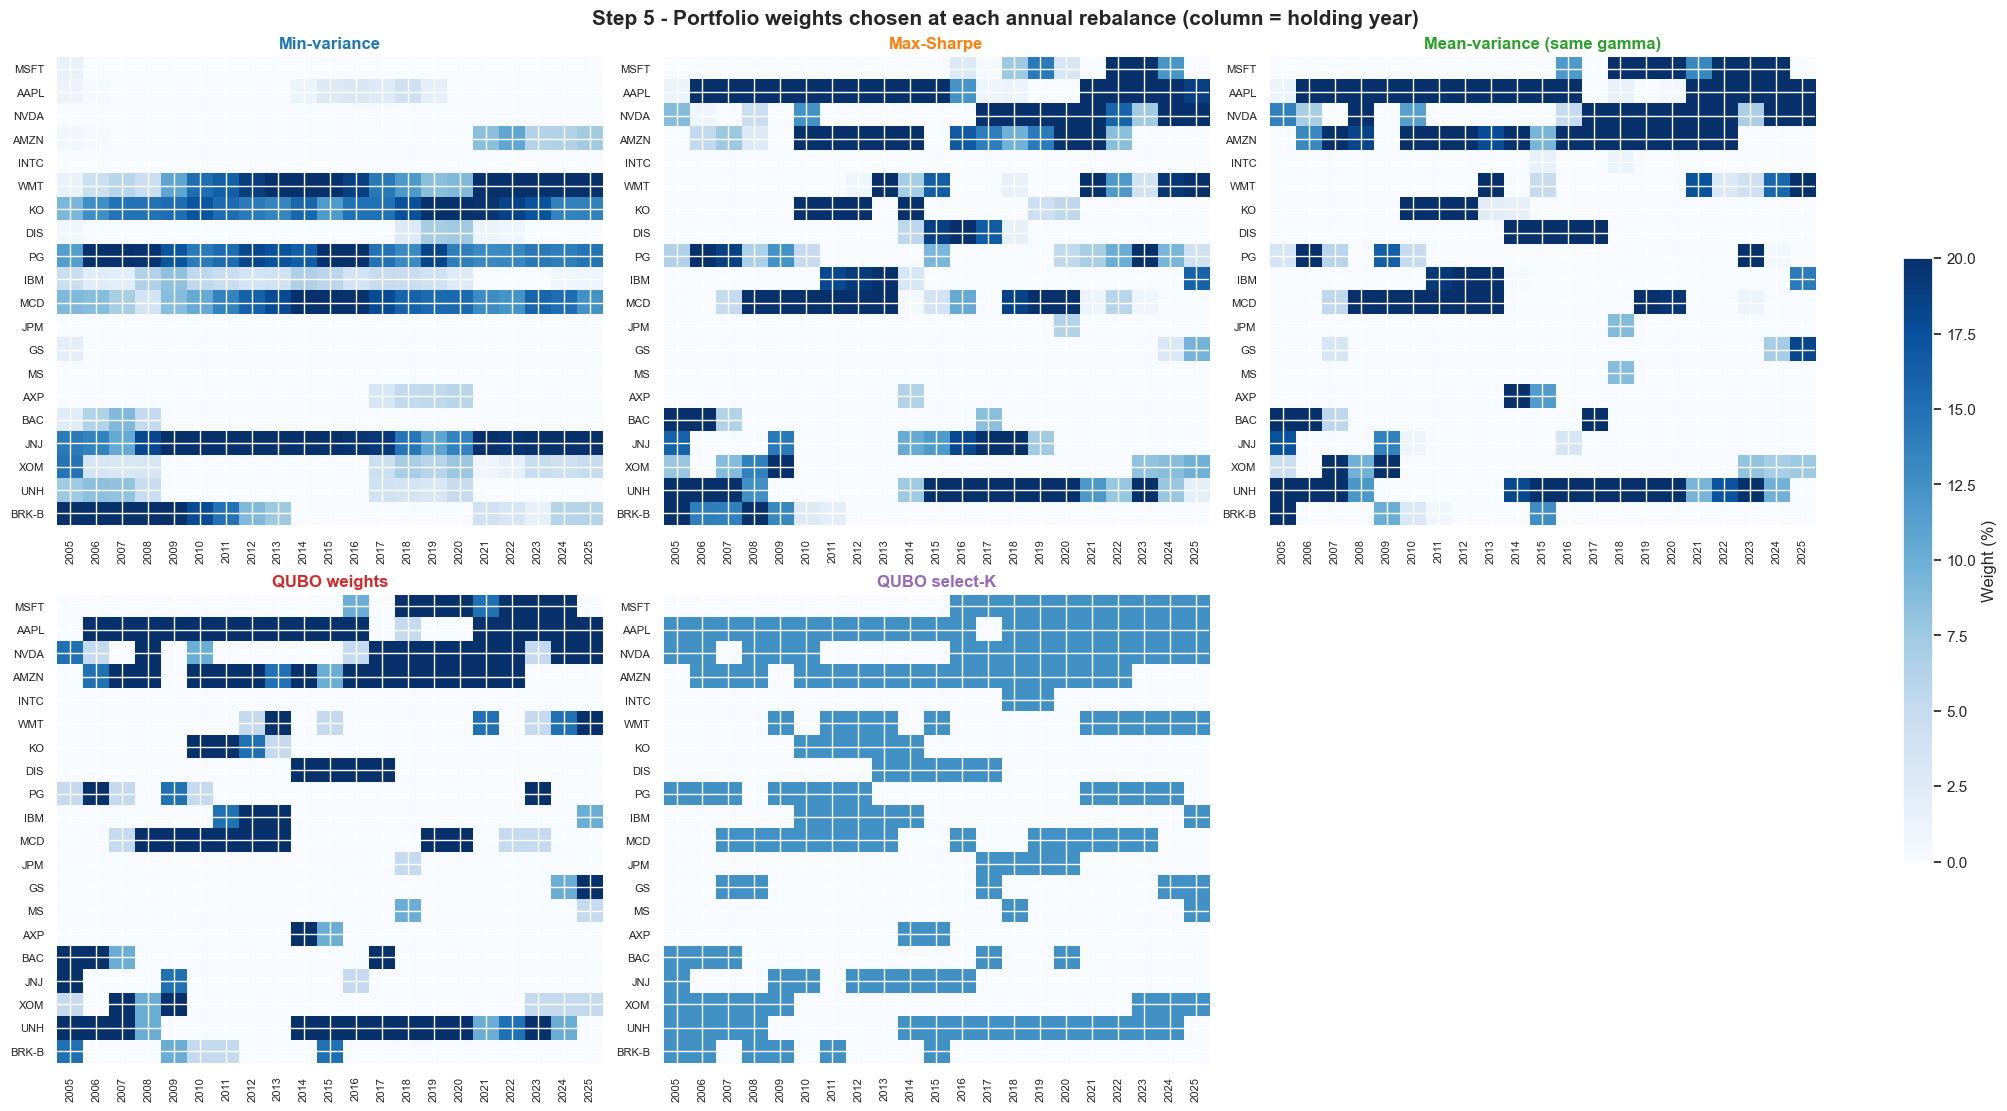

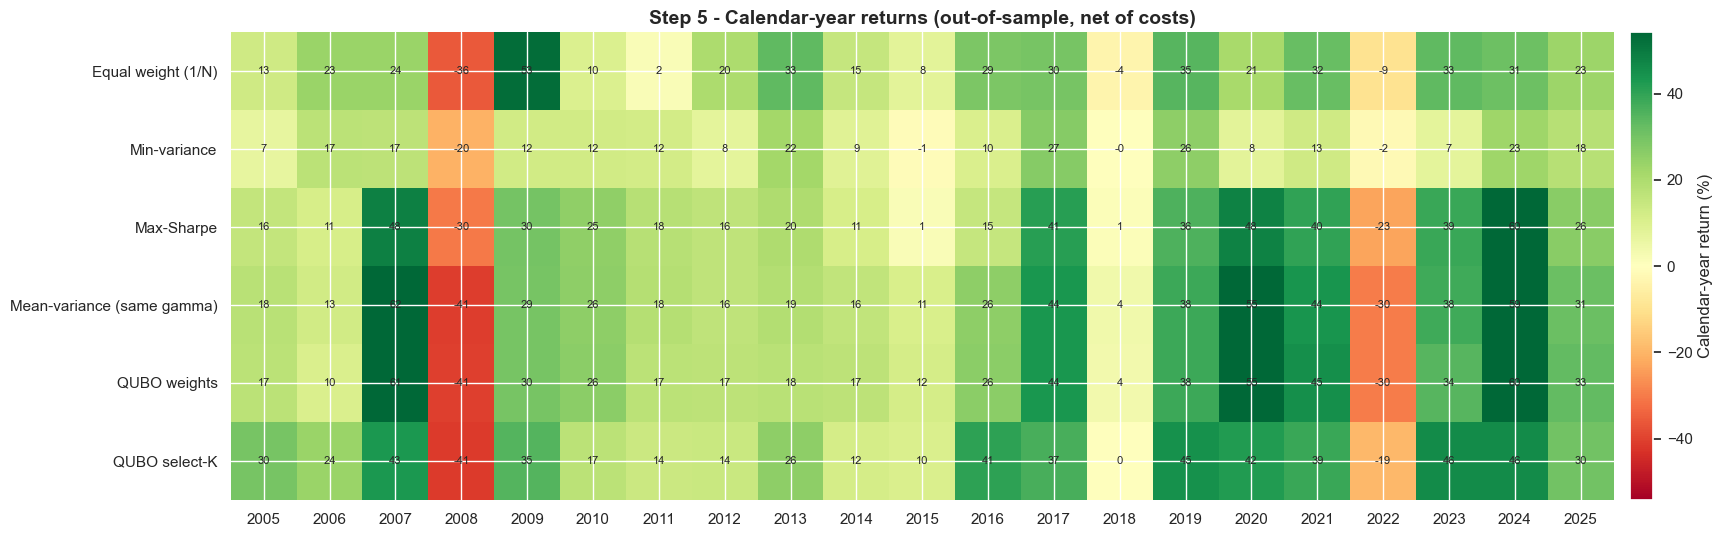

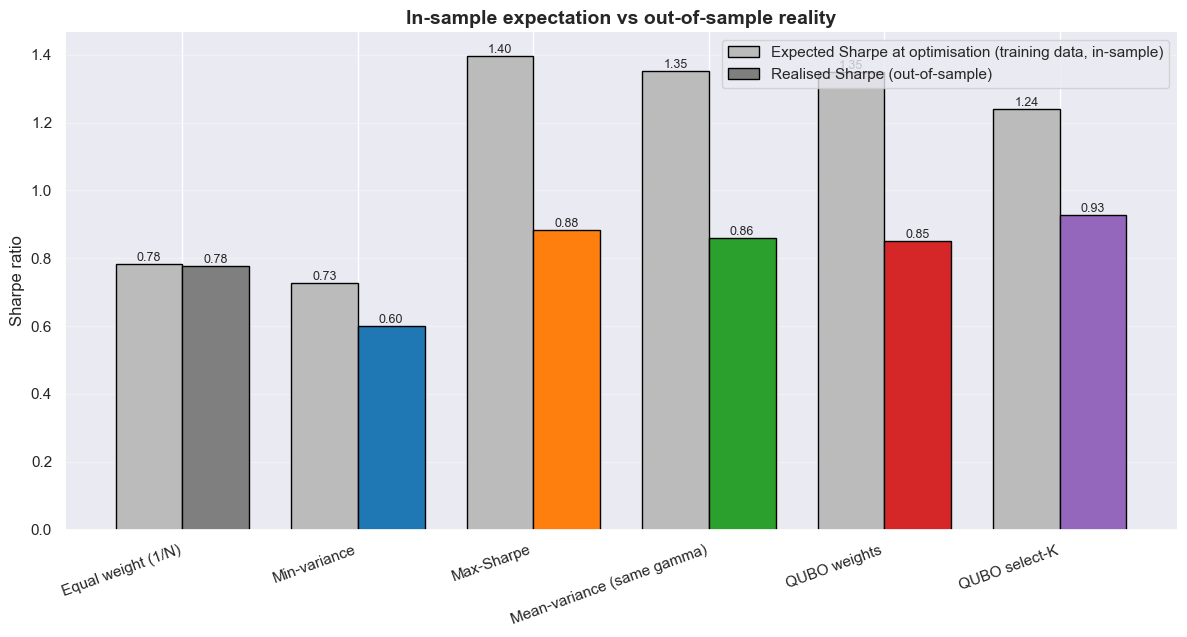

,In-sample Sharpe,Out-of-sample Sharpe,Optimism gap
EW,0.782,0.777,0.004
MinVar,0.727,0.601,0.127
MaxSharpe,1.396,0.885,0.512
MeanVar,1.351,0.860,0.491
QUBO-W,1.348,0.852,0.496
QUBO-S,1.240,0.927,0.313


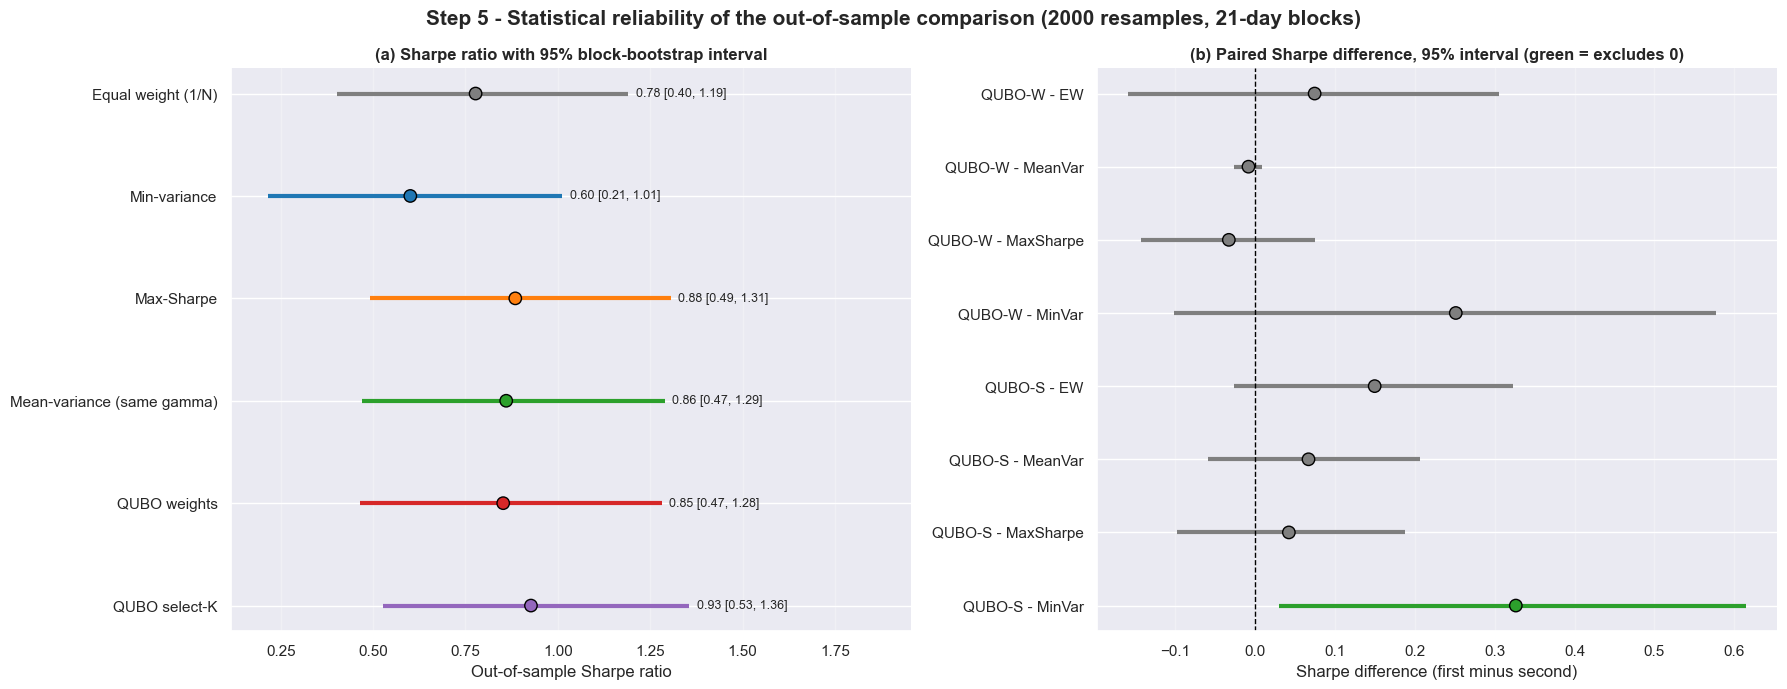

,Sharpe,CI low,CI high
Strategy,,,
EW,0.777,0.402,1.191
MinVar,0.601,0.215,1.012
MaxSharpe,0.885,0.492,1.306
MeanVar,0.860,0.471,1.290
QUBO-W,0.852,0.466,1.282
QUBO-S,0.927,0.527,1.356


,Sharpe difference,CI low,CI high,Significant (CI excludes 0)
Comparison,,,,
QUBO-W - EW,0.075,-0.159,0.306,False
QUBO-W - MeanVar,-0.008,-0.026,0.009,False
QUBO-W - MaxSharpe,-0.033,-0.143,0.075,False
QUBO-W - MinVar,0.251,-0.102,0.577,False
QUBO-S - EW,0.150,-0.027,0.323,False
QUBO-S - MeanVar,0.067,-0.059,0.206,False
QUBO-S - MaxSharpe,0.042,-0.098,0.187,False
QUBO-S - MinVar,0.326,0.031,0.615,True


Robustness runs finished in 342 s



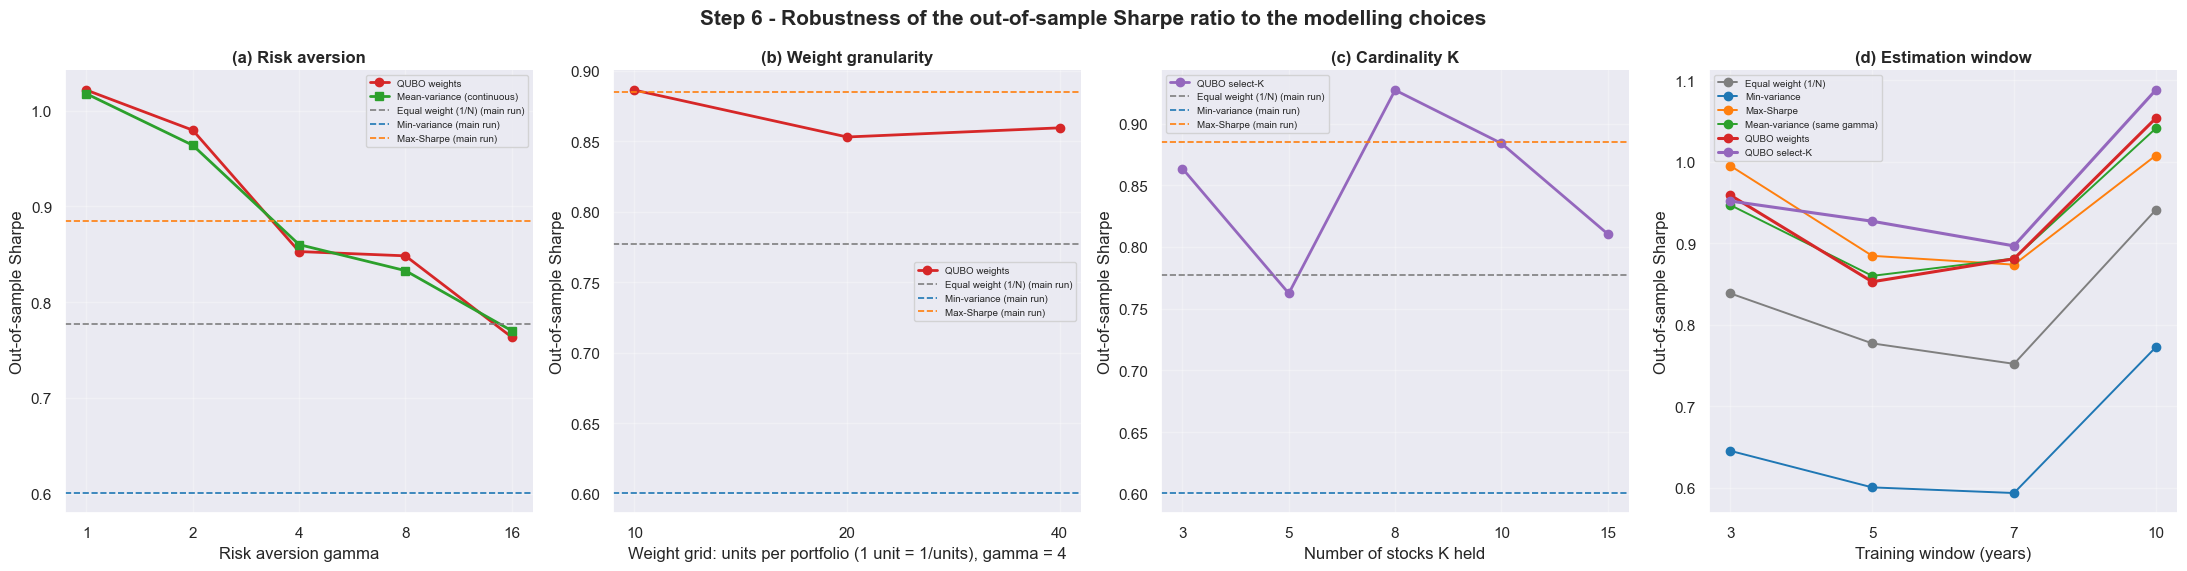

Out-of-sample Sharpe vs gamma:


,QUBO-W,MeanVar
1,1.022,1.018
2,0.980,0.964
4,0.853,0.860
8,0.848,0.833
16,0.764,0.770


Out-of-sample Sharpe vs units:


,QUBO-W
10,0.886
20,0.853
40,0.859


Out-of-sample Sharpe vs k:


,QUBO-S
3,0.864
5,0.762
8,0.927
10,0.884
15,0.811


Out-of-sample Sharpe vs train:


,EW,MinVar,MaxSharpe,MeanVar,QUBO-W,QUBO-S
3,0.839,0.645,0.995,0.947,0.959,0.952
5,0.777,0.601,0.885,0.860,0.853,0.927
7,0.752,0.594,0.874,0.881,0.881,0.897
10,0.941,0.773,1.008,1.041,1.053,1.088


,Sharpe 95% CI,CAGR (%),Volatility (%),Sharpe,Sortino,Max drawdown (%),Calmar,Avg annual turnover (%),Effective N (1/sum w^2)
Equal weight (1/N),"[0.40, 1.19]",16.663,19.774,0.777,1.116,-49.557,0.336,9.288,20.000
Min-variance,"[0.21, 1.01]",10.098,14.419,0.601,0.855,-38.316,0.264,10.953,6.699
Max-Sharpe,"[0.49, 1.31]",19.190,19.805,0.885,1.277,-42.940,0.447,30.964,5.900
Mean-variance (same gamma),"[0.47, 1.29]",20.590,22.355,0.860,1.243,-53.149,0.387,32.312,5.506
QUBO weights,"[0.47, 1.28]",20.397,22.389,0.852,1.231,-52.832,0.386,32.290,5.546
QUBO select-K,"[0.53, 1.36]",20.838,20.541,0.927,1.341,-54.505,0.382,29.167,8.000


Highest out-of-sample Sharpe: QUBO select-K (0.93)
  QUBO-W vs EW: Sharpe difference +0.07 [-0.16, +0.31] -> NOT statistically distinguishable
  QUBO-W vs MeanVar: Sharpe difference -0.01 [-0.03, +0.01] -> NOT statistically distinguishable
  QUBO-W vs MaxSharpe: Sharpe difference -0.03 [-0.14, +0.08] -> NOT statistically distinguishable
  QUBO-W vs MinVar: Sharpe difference +0.25 [-0.10, +0.58] -> NOT statistically distinguishable
  QUBO-S vs EW: Sharpe difference +0.15 [-0.03, +0.32] -> NOT statistically distinguishable
  QUBO-S vs MeanVar: Sharpe difference +0.07 [-0.06, +0.21] -> NOT statistically distinguishable
  QUBO-S vs MaxSharpe: Sharpe difference +0.04 [-0.10, +0.19] -> NOT statistically distinguishable
  QUBO-S vs MinVar: Sharpe difference +0.33 [+0.03, +0.61] -> statistically distinguishable

All figures (PNG, 300 dpi) and tables (CSV) are saved in ./qubo_project_outputs/


In [18]:
# Same code as the notebook, as a plain script (run cell 1 first to create the CSV)

# =============================================================================
# CELL 2 | Settings, data loading and helper functions
# (uses the adj_close_wide.csv written by cell 1)
# =============================================================================
import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------------- user settings ---------------------------------
DATA_FILE = "us_stock_data/adj_close_wide.csv"   # written by cell 1
OUT_DIR   = "qubo_project_outputs"               # every figure / table is saved here
TD        = 252                                  # trading days per year
RF        = 0.02                                 # annual risk-free rate (same as cell 3)
SEED      = 42

CFG = dict(
    train_years = 5,      # length of the training window (calendar years)
    cap         = 0.20,   # maximum weight of any single stock (all weight-based strategies)
    gamma       = 4.0,    # risk aversion in the mean-variance / QUBO objective
    units       = 20,     # weight grid: one unit = 1/units of the portfolio (20 -> 5 %)
    k_select    = 8,      # number of stocks held by the QUBO "select K" variant
    tc          = 0.001,  # transaction cost: 10 bps on every unit of traded weight
    pen_mult    = 2.0,    # strength of the budget / cardinality penalty in the QUBO
    chains      = 128,    # parallel simulated-annealing chains
    sweeps      = 150,    # annealing sweeps per chain
    qubo_w      = True,   # run the QUBO weight-encoding strategy
    qubo_s      = True,   # run the QUBO select-K strategy
    exact       = True,   # verify select-K against exhaustive enumeration
)

STRATS = ["EW", "MinVar", "MaxSharpe", "MeanVar", "QUBO-W", "QUBO-S"]
COLORS = {"EW": "#7f7f7f", "MinVar": "#1f77b4", "MaxSharpe": "#ff7f0e",
          "MeanVar": "#2ca02c", "QUBO-W": "#d62728", "QUBO-S": "#9467bd"}
LABELS = {"EW": "Equal weight (1/N)", "MinVar": "Min-variance", "MaxSharpe": "Max-Sharpe",
          "MeanVar": "Mean-variance (same gamma)", "QUBO-W": "QUBO weights", "QUBO-S": "QUBO select-K"}

os.makedirs(OUT_DIR, exist_ok=True)

def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

# ------------------------------- data ----------------------------------------
prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index()
returns = prices.pct_change().iloc[1:]
rows_before = len(returns)
returns = returns.dropna()                       # keep only days on which every stock traded
tickers = list(returns.columns)
N = len(tickers)
print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | "
      f"{len(returns)} daily returns ({rows_before - len(returns)} rows dropped for missing values)")

# ------------------------------ helpers --------------------------------------
def ledoit_wolf_cov(X):
    """Ledoit-Wolf shrinkage of the sample covariance towards a scaled identity matrix.
    X: (T x n) array of daily returns. Returns (shrunk covariance, shrinkage intensity)."""
    X = X - X.mean(axis=0)
    T, n = X.shape
    S = X.T @ X / T
    m = np.trace(S) / n
    d2 = np.sum((S - m * np.eye(n)) ** 2)
    b2 = (np.sum(np.sum(X ** 2, axis=1) ** 2) - T * np.sum(S ** 2)) / T ** 2
    b2 = min(b2, d2)
    shrink = b2 / d2 if d2 > 0 else 0.0
    return (1 - shrink) * S + shrink * m * np.eye(n), shrink

def estimate_inputs(train):
    """Annualised mean vector and Ledoit-Wolf covariance from a training window."""
    X = train.to_numpy()
    cov_d, shrink = ledoit_wolf_cov(X)
    return X.mean(axis=0) * TD, cov_d * TD, shrink

def rebalance_years(train_years):
    """Years Y at whose end we re-optimise; the portfolio is then held during year Y+1."""
    y0, y1 = returns.index[0].year, returns.index[-1].year
    out = []
    for Y in range(y0 + train_years - 1, y1):
        if len(train_window(Y, train_years)) >= 0.8 * train_years * TD and len(test_window(Y)) > 0:
            out.append(Y)
    return out

def train_window(Y, train_years):
    return returns.loc[f"{Y - train_years + 1}-01-01":f"{Y}-12-31"]

def test_window(Y):
    return returns.loc[f"{Y + 1}-01-01":f"{Y + 1}-12-31"]

def perf_metrics(r, rf=RF):
    """Performance statistics of a daily (net) return series."""
    r = r.dropna()
    n = len(r)
    wealth = np.concatenate([[1.0], (1 + r).cumprod().to_numpy()])
    drawdown = wealth / np.maximum.accumulate(wealth) - 1
    cagr = wealth[-1] ** (TD / n) - 1
    ann_ret = r.mean() * TD
    vol = r.std() * np.sqrt(TD)
    downside = np.minimum(r - rf / TD, 0)
    return {
        "CAGR (%)": cagr * 100,
        "Ann. return (%)": ann_ret * 100,
        "Volatility (%)": vol * 100,
        "Sharpe": (ann_ret - rf) / vol,
        "Sortino": (ann_ret - rf) / (np.sqrt((downside ** 2).mean()) * np.sqrt(TD)),
        "Max drawdown (%)": drawdown.min() * 100,
        "Calmar": cagr / abs(drawdown.min()),
        "Final wealth (x)": wealth[-1],
    }


# =============================================================================
# CELL 3 | STEP 1: Train / test design (walk-forward)
# =============================================================================
REB_YEARS = rebalance_years(CFG["train_years"])
TY = CFG["train_years"]

fig, ax = plt.subplots(figsize=(13, 8))
for i, Y in enumerate(REB_YEARS):
    ax.barh(i, TY, left=Y - TY + 1, color="#1f77b4", alpha=0.85, height=0.7)
    ax.barh(i, 1, left=Y + 1, color="#ff7f0e", height=0.7)
ax.set_yticks(range(len(REB_YEARS)))
ax.set_yticklabels([f"Optimise end-{Y}" for Y in REB_YEARS], fontsize=9)
ax.invert_yaxis()
ax.set_xlim(REB_YEARS[0] - TY + 1 - 0.5, REB_YEARS[-1] + 2.5)
ax.set_xlabel("Calendar year")
ax.grid(True, axis="x", alpha=0.3)
ax.legend(handles=[Patch(color="#1f77b4", label=f"Training window ({TY} years): estimate mu and Sigma, run the optimiser"),
                   Patch(color="#ff7f0e", label="Test year: hold the chosen weights (out-of-sample)")],
          loc="lower left")
ax.set_title(f"Step 1 - Walk-forward design: {len(REB_YEARS)} annual re-optimisations, "
             f"out-of-sample period {REB_YEARS[0] + 1} to {REB_YEARS[-1] + 1}",
             fontsize=14, fontweight="bold")
plt.tight_layout()
savefig("step1_walk_forward_design")
plt.show()

print(f"Training window   : {TY} years (about {TY * TD} daily observations for {N} stocks)")
print(f"Rebalancing       : once a year, at the last trading day of each year")
print(f"Out-of-sample span: {REB_YEARS[0] + 1} to {REB_YEARS[-1] + 1} ({len(REB_YEARS)} test years)")
print(f"Weight cap        : {CFG['cap']:.0%} per stock | transaction cost: {CFG['tc'] * 1e4:.0f} bps per unit traded")


# =============================================================================
# CELL 4 | STEP 2: Baseline portfolios (the benchmarks QUBO has to beat)
#   EW = equal weight | MinVar = minimum variance | MaxSharpe = tangency portfolio
#   MeanVar = mean-variance utility with the SAME risk aversion as the QUBO
# All weight-based baselines are long-only, fully invested, capped at CFG["cap"].
# =============================================================================
def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:                                  # solver failure -> fall back to 1/N
        return equal_weight(n)
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, gamma, cap):
    """minimise  gamma/2 * w'Sigma w - mu'w   (the continuous version of the QUBO objective)"""
    n = len(mu)
    return _slsqp(lambda w: 0.5 * gamma * w @ Sigma @ w - mu @ w,
                  lambda w: gamma * Sigma @ w - mu, n, cap,
                  [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w):
        return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def mv_objective(w, mu, Sigma, gamma):
    return 0.5 * gamma * w @ Sigma @ w - mu @ w

def port_stats(w, mu, Sigma):
    """(expected return, volatility, Sharpe) of weights w under the given inputs."""
    ret, vol = mu @ w, np.sqrt(w @ Sigma @ w)
    return ret, vol, (ret - RF) / vol

def frontier_points(mu, Sigma, cap, n_pts=40):
    """Long-only efficient frontier with the weight cap."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:                                    # highest return reachable under the cap
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((np.sqrt(res.fun), tr))
    pts.append((np.sqrt(w_hi @ Sigma @ w_hi), mu @ w_hi))
    return np.array(pts)

# ------------------ demonstration on the last training window ------------------
DEMO_Y = REB_YEARS[-1]
mu_d, Sig_d, shrink_d = estimate_inputs(train_window(DEMO_Y, CFG["train_years"]))
base_w = {
    "EW": equal_weight(N),
    "MinVar": min_variance(Sig_d, CFG["cap"]),
    "MaxSharpe": max_sharpe(mu_d, Sig_d, CFG["cap"]),
    "MeanVar": mean_variance(mu_d, Sig_d, CFG["gamma"], CFG["cap"]),
}

rng_d = np.random.default_rng(SEED)
rw = rng_d.dirichlet(np.ones(N), size=20000)
rw = rw[rw.max(axis=1) <= CFG["cap"]]                 # random portfolios that respect the cap
r_ret, r_vol = rw @ mu_d, np.sqrt(np.einsum("ij,jk,ik->i", rw, Sig_d, rw))
fr = frontier_points(mu_d, Sig_d, CFG["cap"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(19, 7.5), gridspec_kw={"width_ratios": [1.15, 1]})
sc = ax1.scatter(r_vol * 100, r_ret * 100, c=(r_ret - RF) / r_vol, cmap="viridis", s=7, alpha=0.3)
ax1.scatter(np.sqrt(np.diag(Sig_d)) * 100, mu_d * 100, color="black", s=45, zorder=4, label="Individual stocks")
for t, v, r in zip(tickers, np.sqrt(np.diag(Sig_d)), mu_d):
    ax1.annotate(t, (v * 100, r * 100), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax1.plot(fr[:, 0] * 100, fr[:, 1] * 100, color="red", lw=2.5, label=f"Efficient frontier (cap {CFG['cap']:.0%})")
for name, marker in [("EW", "s"), ("MinVar", "*"), ("MaxSharpe", "*"), ("MeanVar", "D")]:
    rt, vl, sh = port_stats(base_w[name], mu_d, Sig_d)
    ax1.scatter(vl * 100, rt * 100, color=COLORS[name], marker=marker, s=260 if marker == "*" else 110,
                edgecolor="black", zorder=6, label=f"{LABELS[name]} (Sharpe {sh:.2f})")
plt.colorbar(sc, ax=ax1, label="Sharpe ratio of random portfolio")
ax1.set_xlabel("Annualised volatility (%)"); ax1.set_ylabel("Annualised expected return (%)")
ax1.set_title(f"Baseline portfolios on the training window {DEMO_Y - CFG['train_years'] + 1}-{DEMO_Y}")
ax1.grid(True, alpha=0.3); ax1.legend(fontsize=8, loc="best")

x = np.arange(N); bw = 0.27
for k, name in enumerate(["MinVar", "MaxSharpe", "MeanVar"]):
    ax2.bar(x + (k - 1) * bw, base_w[name] * 100, bw, color=COLORS[name], label=LABELS[name])
ax2.axhline(100 / N, color="grey", ls="--", lw=1, label="Equal weight")
ax2.set_xticks(x); ax2.set_xticklabels(tickers, rotation=90)
ax2.set_ylabel("Weight (%)"); ax2.set_title("Baseline weights (same window)")
ax2.grid(True, axis="y", alpha=0.3); ax2.legend(fontsize=8)
fig.suptitle("Step 2 - Baseline (classical) portfolios: long-only, capped, Ledoit-Wolf covariance",
             fontsize=15, fontweight="bold")
plt.tight_layout()
savefig("step2_baselines")
plt.show()

tab = pd.DataFrame({n: dict(zip(["Exp. return (%)", "Volatility (%)", "Sharpe"],
                                [v * (100 if i < 2 else 1) for i, v in enumerate(port_stats(w, mu_d, Sig_d))]))
                    for n, w in base_w.items()}).T
tab["Stocks held (>0.5%)"] = [int((base_w[n] > 0.005).sum()) for n in tab.index]
tab["Largest weight (%)"] = [base_w[n].max() * 100 for n in tab.index]
print(f"In-sample statistics of the baselines (training window ending {DEMO_Y}; Ledoit-Wolf shrinkage = {shrink_d:.3f}):")
display(tab.round(3))


# =============================================================================
# CELL 5 | STEP 3: QUBO formulation
#
# QUBO-W (weight encoding)   w_i = (sum_k a_k * x_ik) / UNITS   with binary bits x_ik
#     minimise  gamma/2 * w'Sigma w - mu'w + P * (sum(w) - 1)^2
#     => energy(x) = x'Qx + const, with  Q = gamma/2 * A'Sigma A - diag(A'mu) + P * (c c' - 2 diag(c))
#     A maps bits to weights, c = A'1 is the weight carried by each bit.
#     The bit weights a_k are chosen so that no stock can exceed the weight cap.
#
# QUBO-S (select K stocks)   z_i in {0,1}, w_i = z_i / K
#     minimise  gamma/2 * w'Sigma w - mu'w + P * (sum(z) - K)^2
# =============================================================================
def bit_weights(cap_units):
    """Bounded binary encoding: bit weights sum to cap_units and reach every integer 0..cap_units."""
    m = int(np.floor(np.log2(cap_units)))
    return np.array([2 ** k for k in range(m)] + [cap_units - (2 ** m - 1)], dtype=float)

def build_qubo_weights(mu, Sigma, gamma, units, cap, pen_mult):
    n = len(mu)
    cap_u = int(np.floor(cap * units + 1e-9))
    a = bit_weights(cap_u)
    nb = len(a)
    A = np.zeros((n, n * nb))
    for i in range(n):
        A[i, i * nb:(i + 1) * nb] = a / units
    c = A.sum(axis=0)                                          # A'1
    scale = max(np.abs(mu).max(), 0.5 * gamma * np.diag(Sigma).max())
    P = pen_mult * scale * units                               # violating the budget by one unit must cost more than it can gain
    Q = 0.5 * gamma * (A.T @ Sigma @ A) - np.diag(A.T @ mu) + P * (np.outer(c, c) - 2 * np.diag(c))
    return dict(Q=Q, const=P, A=A, a=a, nb=nb, n=n, cap_u=cap_u, units=units, P=P)

def build_qubo_select(mu, Sigma, gamma, k, pen_mult):
    n = len(mu)
    P = pen_mult * max(np.abs(mu).max() / k, 0.5 * gamma * np.diag(Sigma).max() / k ** 2)
    Q = 0.5 * gamma / k ** 2 * Sigma - np.diag(mu / k) + P * (np.ones((n, n)) - 2 * k * np.eye(n))
    return dict(Q=Q, const=P * k ** 2, n=n, k=k, P=P)

# ------------------------ demonstration + correctness check --------------------
qw = build_qubo_weights(mu_d, Sig_d, CFG["gamma"], CFG["units"], CFG["cap"], CFG["pen_mult"])
qs = build_qubo_select(mu_d, Sig_d, CFG["gamma"], CFG["k_select"], CFG["pen_mult"])

rng_c = np.random.default_rng(1)
for _ in range(200):                                           # the QUBO energy must equal the original objective
    x = rng_c.integers(0, 2, qw["Q"].shape[0]).astype(float)
    w = qw["A"] @ x
    assert np.isclose(x @ qw["Q"] @ x + qw["const"],
                      mv_objective(w, mu_d, Sig_d, CFG["gamma"]) + qw["P"] * (w.sum() - 1) ** 2)
    z = rng_c.integers(0, 2, N).astype(float)
    assert np.isclose(z @ qs["Q"] @ z + qs["const"],
                      mv_objective(z / CFG["k_select"], mu_d, Sig_d, CFG["gamma"]) + qs["P"] * (z.sum() - CFG["k_select"]) ** 2)
print("Check passed: QUBO energy == mean-variance objective + penalty for 200 random bit strings (both formulations).\n")

print(f"QUBO-W : {N} stocks x {qw['nb']} bits = {qw['Q'].shape[0]} binary variables | "
      f"bit weights (in units of {100 / CFG['units']:.1f}% ) = {qw['a'].astype(int).tolist()} | max weight per stock = {qw['cap_u'] / CFG['units']:.0%}")
print(f"QUBO-S : {N} binary variables (1 = stock selected), exactly K = {CFG['k_select']} stocks, equal weights 1/K")
print(f"Penalty strengths  P(W) = {qw['P']:.2f} | P(S) = {qs['P']:.2f}")

# The full Q is dominated by the penalty term, so the plot shows its informative part: the risk (covariance) block
# that is written onto the binary variables.  Full Q = risk block - return reward (diagonal) + penalty P*(c c' - 2 diag c).
risk_w = 0.5 * CFG["gamma"] * (qw["A"].T @ Sig_d @ qw["A"])
risk_s = 0.5 * CFG["gamma"] / CFG["k_select"] ** 2 * Sig_d
nvar = qw["Q"].shape[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 7.5), gridspec_kw={"width_ratios": [1.15, 1]})
for ax, Qm in [(ax1, risk_w), (ax2, risk_s)]:
    im = ax.imshow(Qm, cmap="viridis", vmin=0)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label="Risk coefficient in Q")
    for sp in ax.spines.values(): sp.set_visible(False)
ax1.set_title(f"QUBO-W: risk block of Q ({nvar} x {nvar} bits, {qw['nb']} bits per stock)")
ax1.set_xticks(np.arange(N) * qw["nb"] + (qw["nb"] - 1) / 2); ax1.set_xticklabels(tickers, rotation=90, fontsize=8)
ax1.set_yticks(np.arange(N) * qw["nb"] + (qw["nb"] - 1) / 2); ax1.set_yticklabels(tickers, fontsize=8)
for b in range(1, N):
    ax1.axhline(b * qw["nb"] - 0.5, color="white", lw=0.3); ax1.axvline(b * qw["nb"] - 0.5, color="white", lw=0.3)
ax2.set_title(f"QUBO-S: risk block of Q ({N} x {N}, one bit per stock)")
ax2.set_xticks(range(N)); ax2.set_xticklabels(tickers, rotation=90, fontsize=8)
ax2.set_yticks(range(N)); ax2.set_yticklabels(tickers, fontsize=8)
fig.suptitle("Step 3 - QUBO matrices (last training window): covariance structure written onto binary variables\n"
             "Full Q = risk block - return reward on the diagonal + budget / cardinality penalty", fontsize=13, fontweight="bold")
plt.tight_layout()
savefig("step3_qubo_matrices")
plt.show()


# =============================================================================
# CELL 6 | STEP 4: Solving the QUBO (simulated annealing) and verifying the solver
#
#  * simulated_annealing : parallel single-bit-flip annealing on x'Qx (pure NumPy, no extra packages)
#  * repair_units        : if a chain ends with a slightly violated budget, add / remove units greedily
#  * solve_window        : optimise every strategy for one training window (results are cached)
#  * verification        : QUBO-S vs exhaustive enumeration of all C(N,K) portfolios (exact optimum),
#                          QUBO-W vs the continuous mean-variance optimum (discretisation gap)
# =============================================================================
def simulated_annealing(Q, n_chains=128, n_sweeps=150, rng=None, t_hi=None, t_lo=None, pair_moves=True):
    """Minimise x'Qx over x in {0,1}^n with n_chains independent annealing runs in parallel.
    Each sweep proposes n single-bit flips and (optionally) n two-bit flips. The two-bit moves let a
    chain swap one stock / one weight unit for another without passing through a heavily penalised state.
    Returns final states X (chains x n), energies E (chains) and (temperatures, mean energy per sweep)."""
    rng = rng if rng is not None else np.random.default_rng(SEED)
    Q = 0.5 * (Q + Q.T)
    n = Q.shape[0]
    d = np.diag(Q).copy()
    off = Q - np.diag(d)
    X = rng.integers(0, 2, size=(n_chains, n)).astype(float)
    H = X @ off                                            # local fields
    E = np.einsum("ri,ri->r", X @ Q, X)
    if t_hi is None:                                       # temperature range from the typical single-flip energy change
        t_hi = np.median(np.abs((1 - 2 * X) * (d + 2 * H)))
    if t_lo is None:
        t_lo = t_hi * 1e-4
    temps = np.geomspace(t_hi, t_lo, n_sweeps)
    trace = np.empty(n_sweeps)
    for s, T in enumerate(temps):
        U1 = rng.random((n, n_chains))
        for j, i in enumerate(rng.permutation(n)):         # single-bit flips
            delta = 1 - 2 * X[:, i]                        # +1: 0 -> 1, -1: 1 -> 0
            dE = delta * (d[i] + 2 * H[:, i])
            acc = (dE <= 0) | (U1[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                m = acc * delta
                X[:, i] += m
                H += m[:, None] * off[i]
                E += acc * dE
        if pair_moves:
            U2 = rng.random((n, n_chains))
            pairs = np.array([rng.choice(n, 2, replace=False) for _ in range(n)])
            for j, (i, k) in enumerate(pairs):             # two-bit flips (i and k together)
                di, dk = 1 - 2 * X[:, i], 1 - 2 * X[:, k]
                dE = di * (d[i] + 2 * H[:, i]) + dk * (d[k] + 2 * H[:, k]) + 2 * off[i, k] * di * dk
                acc = (dE <= 0) | (U2[j] < np.exp(-np.maximum(dE, 0) / T))
                if acc.any():
                    mi, mk = acc * di, acc * dk
                    X[:, i] += mi
                    X[:, k] += mk
                    H += mi[:, None] * off[i] + mk[:, None] * off[k]
                    E += acc * dE
        trace[s] = E.mean()
    E = np.einsum("ri,ri->r", X @ Q, X)
    return X, E, (temps, trace)

def repair_units(u, f, total, cap_u):
    """Greedy repair: add / remove single units until sum(u) == total, always picking the best objective."""
    u = u.copy()
    while u.sum() > total:
        cand = np.flatnonzero(u > 0)
        vals = []
        for i in cand:
            u[i] -= 1; vals.append(f(u)); u[i] += 1
        u[cand[int(np.argmin(vals))]] -= 1
    while u.sum() < total:
        cand = np.flatnonzero(u < cap_u)
        vals = []
        for i in cand:
            u[i] += 1; vals.append(f(u)); u[i] -= 1
        u[cand[int(np.argmin(vals))]] += 1
    return u

def decode_weights(X, E, q, mu, Sigma, gamma, top=10):
    n, nb, U = q["n"], q["nb"], q["units"]
    units_all = np.rint(X.reshape(len(X), n, nb) @ q["a"]).astype(int)
    feasible = units_all.sum(axis=1) == U
    f = lambda uu: mv_objective(uu / U, mu, Sigma, gamma)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(units_all[r], f, U, q["cap_u"])
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / U, dict(feasible_rate=float(feasible.mean()))

def decode_select(X, E, q, mu, Sigma, gamma, top=10):
    k = q["k"]
    feasible = X.sum(axis=1) == k
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(X[r].astype(int), f, k, 1)
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / k, dict(feasible_rate=float(feasible.mean()), feasible=feasible)

def exact_select(mu, Sigma, gamma, k):
    """Exhaustive search over all C(N,k) equal-weight portfolios (feasible for N = 20)."""
    combos = np.array(list(itertools.combinations(range(len(mu)), k)))
    var = Sigma[combos[:, :, None], combos[:, None, :]].sum(axis=(1, 2)) / k ** 2
    f = 0.5 * gamma * var - mu[combos].sum(axis=1) / k
    j = int(np.argmin(f))
    return combos[j], float(f[j])

SOLVE_CACHE = {}

def solve_window(Y, cfg):
    """Estimate mu / Sigma on the training window ending in year Y and optimise every strategy."""
    key = (Y,) + tuple(sorted(cfg.items()))
    if key in SOLVE_CACHE:
        return SOLVE_CACHE[key]
    mu, Sigma, shrink = estimate_inputs(train_window(Y, cfg["train_years"]))
    n, cap, gamma = len(mu), cfg["cap"], cfg["gamma"]
    rng = np.random.default_rng(SEED + Y)
    weights = {"EW": equal_weight(n),
               "MinVar": min_variance(Sigma, cap),
               "MaxSharpe": max_sharpe(mu, Sigma, cap),
               "MeanVar": mean_variance(mu, Sigma, gamma, cap)}
    diag = dict(lw_shrink=shrink)
    if cfg["qubo_w"]:
        q = build_qubo_weights(mu, Sigma, gamma, cfg["units"], cap, cfg["pen_mult"])
        X, E, (temps, trace) = simulated_annealing(q["Q"], cfg["chains"], cfg["sweeps"], rng=rng)
        w, info = decode_weights(X, E, q, mu, Sigma, gamma)
        weights["QUBO-W"] = w
        f_q, f_c = mv_objective(w, mu, Sigma, gamma), mv_objective(weights["MeanVar"], mu, Sigma, gamma)
        diag.update(w_feasible=info["feasible_rate"], w_obj=f_q, w_obj_cont=f_c,
                    w_gap_pct=(f_q - f_c) / abs(f_c) * 100, trace=(temps, trace))
    if cfg["qubo_s"]:
        q = build_qubo_select(mu, Sigma, gamma, cfg["k_select"], cfg["pen_mult"])
        X, E, _ = simulated_annealing(q["Q"], cfg["chains"], cfg["sweeps"], rng=rng)
        w, info = decode_select(X, E, q, mu, Sigma, gamma)
        weights["QUBO-S"] = w
        diag.update(s_feasible=info["feasible_rate"], s_obj=mv_objective(w, mu, Sigma, gamma))
        if cfg["exact"]:
            _, f_ex = exact_select(mu, Sigma, gamma, cfg["k_select"])
            Wf = X[info["feasible"]] / cfg["k_select"]
            f_ch = 0.5 * gamma * np.einsum("ri,ij,rj->r", Wf, Sigma, Wf) - Wf @ mu
            diag.update(s_obj_exact=f_ex, s_hit_rate=float(np.mean(f_ch <= f_ex + 1e-10)) if len(f_ch) else 0.0,
                        s_found_opt=bool(diag["s_obj"] <= f_ex + 1e-10))
    out = dict(weights=weights, mu=mu, Sigma=Sigma, diag=diag)
    SOLVE_CACHE[key] = out
    return out

# ------------------------- run every window + verification ----------------------
t0 = time.time()
val = pd.DataFrame({Y: solve_window(Y, CFG)["diag"] for Y in REB_YEARS}).T
print(f"Solved {len(REB_YEARS)} training windows in {time.time() - t0:.0f} s "
      f"({CFG['chains']} chains x {CFG['sweeps']} sweeps per QUBO)\n")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
# (a) annealing convergence on the demo window
temps, trace = solve_window(DEMO_Y, CFG)["diag"]["trace"]
ax = axes[0]
ax.plot(np.arange(1, len(trace) + 1), trace - trace.min() + 1e-6, color=COLORS["QUBO-W"], lw=2, label="Mean chain energy above its final value")
ax.set_yscale("log"); ax.set_xlabel("Annealing sweep"); ax.set_ylabel("Energy above final value (log scale)")
ax2 = ax.twinx(); ax2.plot(np.arange(1, len(temps) + 1), temps, color="grey", ls="--", label="Temperature")
ax2.set_yscale("log"); ax2.set_ylabel("Temperature (log scale)"); ax2.spines["right"].set_visible(True)
ax.set_title(f"(a) Annealing convergence, QUBO-W, window ending {DEMO_Y}")
ax.grid(True, alpha=0.3)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=9)
# (b) QUBO-S vs exact enumeration
ax = axes[1]
if CFG["exact"]:
    ax.bar(val.index.astype(str), val["s_hit_rate"].astype(float) * 100, color=np.where(val["s_found_opt"].astype(bool), COLORS["QUBO-S"], "#bbbbbb"))
    ax.set_ylabel("Chains that reach the exact optimum (%)"); ax.set_ylim(0, 105)
    ax.set_title(f"(b) QUBO-S vs exhaustive search: exact optimum found in\n{int(val['s_found_opt'].sum())} of {len(val)} windows (grey = missed)")
ax.set_xlabel("Year of optimisation"); ax.tick_params(axis="x", rotation=90); ax.grid(True, axis="y", alpha=0.3)
# (c) QUBO-W discretisation gap
ax = axes[2]
ax.bar(val.index.astype(str), val["w_gap_pct"].astype(float), color=COLORS["QUBO-W"])
ax.set_ylabel("Objective gap vs continuous optimum (%)")
ax.set_title(f"(c) QUBO-W vs continuous mean-variance optimum\n(mean gap {val['w_gap_pct'].astype(float).mean():.2f}%; 0 = as good as continuous)")
ax.set_xlabel("Year of optimisation"); ax.tick_params(axis="x", rotation=90); ax.grid(True, axis="y", alpha=0.3)
fig.suptitle("Step 4 - Solving the QUBO with simulated annealing: convergence and verification", fontsize=15, fontweight="bold")
plt.tight_layout()
savefig("step4_solver_verification")
plt.show()

ver = pd.DataFrame({
    "QUBO-W: chains ending budget-feasible (%)": [val["w_feasible"].astype(float).mean() * 100],
    "QUBO-W: mean gap vs continuous (%)": [val["w_gap_pct"].astype(float).mean()],
    "QUBO-S: chains ending cardinality-feasible (%)": [val["s_feasible"].astype(float).mean() * 100],
    "QUBO-S: windows where exact optimum found": [f"{int(val['s_found_opt'].sum())}/{len(val)}" if CFG["exact"] else "n/a"],
    "QUBO-S: mean chain hit-rate (%)": [val["s_hit_rate"].astype(float).mean() * 100 if CFG["exact"] else np.nan],
}, index=["Solver diagnostics"]).T
display(ver.round(2))


# =============================================================================
# CELL 7 | STEP 5a: Out-of-sample walk-forward backtest
#   every year-end: estimate on the last TRAIN_YEARS -> optimise every strategy -> hold through next year
#   weights drift inside the year (buy and hold) and are reset at the next rebalance;
#   transaction cost = CFG["tc"] x traded weight, charged on the first day of the year.
# =============================================================================
def hold_period(R, w):
    """Buy-and-hold one year. R: (days x stocks) daily returns. Returns daily portfolio returns and end-of-year weights."""
    growth = np.cumprod(1 + R, axis=0)
    value = growth @ w
    prev = np.concatenate([[1.0], value[:-1]])
    return value / prev - 1, w * growth[-1] / value[-1]

def active_strategies(cfg):
    return [s for s in STRATS if (s != "QUBO-W" or cfg["qubo_w"]) and (s != "QUBO-S" or cfg["qubo_s"])]

def walk_forward(cfg):
    names = active_strategies(cfg)
    years = rebalance_years(cfg["train_years"])
    rets = {s: [] for s in names}
    W = {s: {} for s in names}; TO = {s: {} for s in names}; PRED = {s: {} for s in names}
    w_prev = {s: np.zeros(N) for s in names}
    for Y in years:
        sol = solve_window(Y, cfg)
        test = test_window(Y)
        for s in names:
            w = sol["weights"][s]
            turnover = np.abs(w - w_prev[s]).sum()            # sum |w_new - w_drifted_old|
            rp, w_end = hold_period(test.to_numpy(), w)
            rp[0] -= cfg["tc"] * turnover
            rets[s].append(pd.Series(rp, index=test.index))
            W[s][Y + 1] = w
            TO[s][Y + 1] = turnover
            PRED[s][Y + 1] = port_stats(w, sol["mu"], sol["Sigma"])[2]   # Sharpe the optimiser expected (in-sample)
            w_prev[s] = w_end
    return dict(ret=pd.DataFrame({s: pd.concat(rets[s]) for s in names}),
                weights={s: pd.DataFrame(W[s], index=tickers).T for s in names},
                turnover=pd.DataFrame(TO), pred_sharpe=pd.DataFrame(PRED), years=years)

def metrics_table(res):
    rows = {}
    for s in res["ret"].columns:
        m = perf_metrics(res["ret"][s])
        w = res["weights"][s]
        m["Avg annual turnover (%)"] = res["turnover"][s].iloc[1:].mean() / 2 * 100     # one-way, excluding the initial purchase
        m["Avg stocks held (>0.5%)"] = (w > 0.005).sum(axis=1).mean()
        m["Avg largest weight (%)"] = w.max(axis=1).mean() * 100
        m["Effective N (1/sum w^2)"] = (1 / (w ** 2).sum(axis=1)).mean()
        rows[s] = m
    return pd.DataFrame(rows).T

t0 = time.time()
RES = walk_forward(CFG)
METRICS = metrics_table(RES)
print(f"Walk-forward finished in {time.time() - t0:.0f} s | out-of-sample {RES['ret'].index[0].date()} to "
      f"{RES['ret'].index[-1].date()} ({len(RES['ret'])} trading days, {len(RES['years'])} annual rebalances)\n")
print(f"Out-of-sample performance after transaction costs ({CFG['tc'] * 1e4:.0f} bps per unit traded), risk-free rate {RF:.0%}:")
display(METRICS.round(3))


# =============================================================================
# CELL 8 | STEP 5b: Out-of-sample charts
# =============================================================================
ret = RES["ret"]
names = list(ret.columns)
wealth = (1 + ret).cumprod()

def ret_axis(ax, lo, hi):
    """Log axis of the wealth index, with tick labels shown as round cumulative-return percentages."""
    pcts = np.array([-75, -50, 0, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000, 100000])
    ticks = 1 + pcts / 100
    keep = (ticks >= lo) & (ticks <= hi)
    ax.set_yticks(ticks[keep]); ax.yaxis.set_minor_formatter(mtick.NullFormatter())
    ax.set_yticklabels([f"{p:,.0f}%" for p in pcts[keep]])

# ---- Figure 5a: cumulative return and drawdown ----
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
for s in names:
    ax1.plot(wealth.index, wealth[s], color=COLORS[s], lw=2.4 if s.startswith("QUBO") else 1.6,
             label=f"{LABELS[s]} (Sharpe {METRICS.loc[s, 'Sharpe']:.2f})")
    dd = wealth[s] / np.maximum.accumulate(wealth[s]) - 1
    ax2.plot(dd.index, dd * 100, color=COLORS[s], lw=1.3)
ax1.set_yscale("log"); ax1.axhline(1, color="black", lw=0.8, ls="--")
ret_axis(ax1, wealth.min().min() * 0.9, wealth.max().max() * 1.1)
ax1.set_ylabel("Cumulative return (%)  [log scale]"); ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper left", fontsize=10)
ax1.set_title(f"Step 5 - Out-of-sample cumulative return, {ret.index[0].year}-{ret.index[-1].year} "
              f"(walk-forward, net of {CFG['tc'] * 1e4:.0f} bps costs)", fontsize=14, fontweight="bold")
ax2.set_ylabel("Drawdown (%)"); ax2.set_xlabel("Date"); ax2.grid(True, alpha=0.3)
plt.tight_layout(); savefig("step5a_cumulative_return_drawdown"); plt.show()

# ---- Figure 5b: metric comparison ----
panels = [("CAGR (%)", "CAGR (%)"), ("Volatility (%)", "Annualised volatility (%)"), ("Sharpe", f"Sharpe ratio (rf = {RF:.0%})"),
          ("Max drawdown (%)", "Maximum drawdown (%)"), ("Avg annual turnover (%)", "Average annual turnover (one-way, %)"),
          ("Effective N (1/sum w^2)", "Effective number of holdings")]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (col, title) in zip(axes.flat, panels):
    vals = METRICS.loc[names, col].astype(float)
    ax.bar(range(len(names)), vals, color=[COLORS[s] for s in names])
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=30, ha="right")
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.2f}" if col in ("Sharpe",) else f"{v:.1f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
    ax.set_title(title, fontweight="bold"); ax.grid(True, axis="y", alpha=0.3)
fig.suptitle("Step 5 - Out-of-sample performance comparison", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("step5b_metric_comparison"); plt.show()

# ---- Figure 5c: weights over time ----
wnames = [s for s in names if s != "EW"]
fig, axes = plt.subplots(2, 3, figsize=(20, 11), constrained_layout=True)
for ax, s in zip(axes.flat, wnames):
    wdf = RES["weights"][s] * 100
    im = ax.imshow(wdf.T.values, aspect="auto", cmap="Blues", vmin=0, vmax=CFG["cap"] * 100)
    ax.set_xticks(range(len(wdf))); ax.set_xticklabels(wdf.index, rotation=90, fontsize=8)
    ax.set_yticks(range(N)); ax.set_yticklabels(tickers, fontsize=8)
    ax.set_title(LABELS[s], fontweight="bold", color=COLORS[s])
    for sp in ax.spines.values(): sp.set_visible(False)
for ax in list(axes.flat)[len(wnames):]:
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.6, label="Weight (%)")
fig.suptitle("Step 5 - Portfolio weights chosen at each annual rebalance (column = holding year)", fontsize=15, fontweight="bold")
savefig("step5c_weights_over_time"); plt.show()

# ---- Figure 5d: calendar-year returns ----
annual = ret.groupby(ret.index.year).apply(lambda x: (1 + x).prod() - 1).T * 100
fig, ax = plt.subplots(figsize=(19, 5.5))
lim = np.nanpercentile(np.abs(annual.values), 95)
im = ax.imshow(annual.values, aspect="auto", cmap="RdYlGn", norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim))
ax.set_xticks(range(annual.shape[1])); ax.set_xticklabels(annual.columns)
ax.set_yticks(range(len(annual))); ax.set_yticklabels([LABELS[s] for s in annual.index])
for i in range(annual.shape[0]):
    for j in range(annual.shape[1]):
        ax.text(j, i, f"{annual.iat[i, j]:.0f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, pad=0.01, label="Calendar-year return (%)")
ax.set_title("Step 5 - Calendar-year returns (out-of-sample, net of costs)", fontsize=14, fontweight="bold")
for sp in ax.spines.values(): sp.set_visible(False)
plt.tight_layout(); savefig("step5d_calendar_year_returns"); plt.show()

# ---- Figure 5e: in-sample expectation vs out-of-sample reality ----
pred = RES["pred_sharpe"].mean()
real = METRICS["Sharpe"].astype(float)
x = np.arange(len(names)); bw = 0.38
fig, ax = plt.subplots(figsize=(12, 6.5))
ax.bar(x - bw / 2, pred[names], bw, color="#bbbbbb", edgecolor="black", label="Expected Sharpe at optimisation (training data, in-sample)")
ax.bar(x + bw / 2, real[names], bw, color=[COLORS[s] for s in names], edgecolor="black", label="Realised Sharpe (out-of-sample)")
for i, s in enumerate(names):
    ax.text(i - bw / 2, pred[s], f"{pred[s]:.2f}", ha="center", va="bottom", fontsize=9)
    ax.text(i + bw / 2, real[s], f"{real[s]:.2f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([LABELS[s] for s in names], rotation=20, ha="right")
ax.set_ylabel("Sharpe ratio"); ax.grid(True, axis="y", alpha=0.3); ax.legend()
ax.set_title("In-sample expectation vs out-of-sample reality", fontsize=14, fontweight="bold")
plt.tight_layout(); savefig("step5e_in_vs_out_of_sample"); plt.show()
gap = pd.DataFrame({"In-sample Sharpe": pred[names], "Out-of-sample Sharpe": real[names]})
gap["Optimism gap"] = gap["In-sample Sharpe"] - gap["Out-of-sample Sharpe"]
display(gap.round(3))


# =============================================================================
# CELL 9 | STEP 5c: Is the difference statistically meaningful?
# Paired circular block bootstrap of the OUT-OF-SAMPLE daily returns: both strategies are resampled with
# the same dates, so the confidence interval of the Sharpe DIFFERENCE reflects only the gap between them.
# =============================================================================
N_BOOT, BLOCK = 2000, 21
rng_b = np.random.default_rng(SEED)
T_oos = len(RES["ret"])
starts = rng_b.integers(0, T_oos, size=(N_BOOT, int(np.ceil(T_oos / BLOCK))))
idx_b = ((starts[:, :, None] + np.arange(BLOCK)).reshape(N_BOOT, -1)[:, :T_oos]) % T_oos

def boot_sharpe(r):
    s = r.to_numpy()[idx_b]
    return (s.mean(axis=1) * TD - RF) / (s.std(axis=1, ddof=1) * np.sqrt(TD))

boot = {s: boot_sharpe(RES["ret"][s]) for s in RES["ret"].columns}
real_sh = METRICS["Sharpe"].astype(float)

# (a) Sharpe ratios with 95 % intervals
rows = []
for s in RES["ret"].columns:
    lo, hi = np.percentile(boot[s], [2.5, 97.5])
    rows.append((s, real_sh[s], lo, hi))
ci = pd.DataFrame(rows, columns=["Strategy", "Sharpe", "CI low", "CI high"]).set_index("Strategy")

# (b) paired differences
pairs = [("QUBO-W", "EW"), ("QUBO-W", "MeanVar"), ("QUBO-W", "MaxSharpe"), ("QUBO-W", "MinVar"),
         ("QUBO-S", "EW"), ("QUBO-S", "MeanVar"), ("QUBO-S", "MaxSharpe"), ("QUBO-S", "MinVar")]
pairs = [(a, b) for a, b in pairs if a in boot and b in boot]
drows = []
for a, b in pairs:
    dist = boot[a] - boot[b]
    lo, hi = np.percentile(dist, [2.5, 97.5])
    drows.append((f"{a} - {b}", real_sh[a] - real_sh[b], lo, hi, bool(lo > 0 or hi < 0)))
diff = pd.DataFrame(drows, columns=["Comparison", "Sharpe difference", "CI low", "CI high", "Significant (CI excludes 0)"]).set_index("Comparison")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))
yy = np.arange(len(ci))
ax1.hlines(yy, ci["CI low"], ci["CI high"], color=[COLORS[s] for s in ci.index], lw=3)
ax1.scatter(ci["Sharpe"], yy, color=[COLORS[s] for s in ci.index], s=80, edgecolor="black", zorder=3)
ax1.set_yticks(yy); ax1.set_yticklabels([LABELS[s] for s in ci.index]); ax1.invert_yaxis()
for i, s in enumerate(ci.index):
    ax1.text(ci.loc[s, "CI high"] + 0.02, i, f"{ci.loc[s, 'Sharpe']:.2f} [{ci.loc[s, 'CI low']:.2f}, {ci.loc[s, 'CI high']:.2f}]", va="center", fontsize=9)
ax1.set_xlim(ci["CI low"].min() - 0.1, ci["CI high"].max() + 0.6)
ax1.set_xlabel("Out-of-sample Sharpe ratio"); ax1.grid(True, axis="x", alpha=0.3)
ax1.set_title("(a) Sharpe ratio with 95% block-bootstrap interval", fontweight="bold")

yy = np.arange(len(diff))
cols = np.where(diff["Significant (CI excludes 0)"], "#2ca02c", "#7f7f7f")
ax2.hlines(yy, diff["CI low"], diff["CI high"], color=cols, lw=3)
ax2.scatter(diff["Sharpe difference"], yy, color=cols, s=80, edgecolor="black", zorder=3)
ax2.axvline(0, color="black", ls="--", lw=1)
ax2.set_yticks(yy); ax2.set_yticklabels(diff.index); ax2.invert_yaxis()
ax2.set_xlabel("Sharpe difference (first minus second)"); ax2.grid(True, axis="x", alpha=0.3)
ax2.set_title("(b) Paired Sharpe difference, 95% interval (green = excludes 0)", fontweight="bold")
fig.suptitle(f"Step 5 - Statistical reliability of the out-of-sample comparison ({N_BOOT} resamples, {BLOCK}-day blocks)",
             fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("step5f_bootstrap_sharpe"); plt.show()
display(ci.round(3)); display(diff.round(3))


# =============================================================================
# CELL 10 | STEP 6: Robustness - does the conclusion survive other parameter choices?
# Re-runs the whole walk-forward for: risk aversion gamma, weight-grid size, number of stocks K, training length.
# (Uses fewer annealing sweeps than the main run to stay fast.)
# =============================================================================
QUICK = False                       # True -> smaller grids, finishes in a fraction of the time
ROB = dict(CFG, chains=64, sweeps=100, exact=False)
if QUICK:
    GRID = dict(gamma=[2, 4, 8], units=[10, 20], k=[5, 8, 12], train=[3, 5, 7])
else:
    GRID = dict(gamma=[1, 2, 4, 8, 16], units=[10, 20, 40], k=[3, 5, 8, 10, 15], train=[3, 5, 7, 10])

def sharpe_of(cfg, name):
    r = walk_forward(cfg)
    return perf_metrics(r["ret"][name])["Sharpe"], r

t0 = time.time()
rob = {}
# (i) risk aversion (compares QUBO-W with its continuous counterpart MeanVar)
rob["gamma"] = pd.DataFrame({g_: {**{n: sharpe_of(dict(ROB, gamma=g_, qubo_s=False), n)[0] for n in ["QUBO-W"]},
                                  "MeanVar": perf_metrics(walk_forward(dict(ROB, gamma=g_, qubo_w=False, qubo_s=False))["ret"]["MeanVar"])["Sharpe"]}
                             for g_ in GRID["gamma"]}).T
# (ii) weight grid (units)
rob["units"] = pd.DataFrame({u: {"QUBO-W": sharpe_of(dict(ROB, units=u, qubo_s=False), "QUBO-W")[0]} for u in GRID["units"]}).T
# (iii) number of stocks held
rob["k"] = pd.DataFrame({k_: {"QUBO-S": sharpe_of(dict(ROB, k_select=k_, qubo_w=False), "QUBO-S")[0]} for k_ in GRID["k"]}).T
# (iv) training window length (all strategies)
tr = {}
for ty in GRID["train"]:
    r = walk_forward(dict(ROB, train_years=ty))
    tr[ty] = {s: perf_metrics(r["ret"][s])["Sharpe"] for s in r["ret"].columns}
rob["train"] = pd.DataFrame(tr).T
print(f"Robustness runs finished in {time.time() - t0:.0f} s\n")

# EW / MinVar / MaxSharpe reference lines from the main run
ref = {s: METRICS.loc[s, "Sharpe"] for s in ["EW", "MinVar", "MaxSharpe"]}
fig, axes = plt.subplots(1, 4, figsize=(22, 5.8))
ax = axes[0]
ax.plot(rob["gamma"].index.astype(str), rob["gamma"]["QUBO-W"], marker="o", color=COLORS["QUBO-W"], lw=2, label=LABELS["QUBO-W"])
ax.plot(rob["gamma"].index.astype(str), rob["gamma"]["MeanVar"], marker="s", color=COLORS["MeanVar"], lw=2, label="Mean-variance (continuous)")
ax.set_xlabel("Risk aversion gamma"); ax.set_title("(a) Risk aversion", fontweight="bold")
ax = axes[1]
ax.plot(rob["units"].index.astype(str), rob["units"]["QUBO-W"], marker="o", color=COLORS["QUBO-W"], lw=2, label=LABELS["QUBO-W"])
ax.set_xlabel(f"Weight grid: units per portfolio (1 unit = 1/units), gamma = {CFG['gamma']:g}"); ax.set_title("(b) Weight granularity", fontweight="bold")
ax = axes[2]
ax.plot(rob["k"].index.astype(str), rob["k"]["QUBO-S"], marker="o", color=COLORS["QUBO-S"], lw=2, label=LABELS["QUBO-S"])
ax.set_xlabel("Number of stocks K held"); ax.set_title("(c) Cardinality K", fontweight="bold")
ax = axes[3]
for s in rob["train"].columns:
    ax.plot(rob["train"].index.astype(str), rob["train"][s], marker="o", color=COLORS[s], lw=2.2 if s.startswith("QUBO") else 1.4, label=LABELS[s])
ax.set_xlabel("Training window (years)"); ax.set_title("(d) Estimation window", fontweight="bold")
for i, ax in enumerate(axes):
    if i < 3:
        for s, c in ref.items():
            ax.axhline(ref[s], color=COLORS[s], ls="--", lw=1.2, label=f"{LABELS[s]} (main run)")
    ax.set_ylabel("Out-of-sample Sharpe"); ax.grid(True, alpha=0.3); ax.legend(fontsize=7, loc="best")
fig.suptitle("Step 6 - Robustness of the out-of-sample Sharpe ratio to the modelling choices", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("step6_robustness"); plt.show()
for k_, v in rob.items():
    print(f"Out-of-sample Sharpe vs {k_}:"); display(v.round(3))


# =============================================================================
# CELL 11 | STEP 7: Final summary + save every table
# =============================================================================
summary = METRICS[["CAGR (%)", "Volatility (%)", "Sharpe", "Sortino", "Max drawdown (%)", "Calmar",
                   "Avg annual turnover (%)", "Effective N (1/sum w^2)"]].astype(float).round(3)
summary.insert(0, "Sharpe 95% CI", [f"[{ci.loc[s, 'CI low']:.2f}, {ci.loc[s, 'CI high']:.2f}]" for s in summary.index])
summary.index = [LABELS[s] for s in summary.index]
display(summary)

summary.to_csv(f"{OUT_DIR}/summary_metrics.csv")
METRICS.to_csv(f"{OUT_DIR}/metrics_full.csv")
diff.to_csv(f"{OUT_DIR}/sharpe_differences_bootstrap.csv")
RES["ret"].to_csv(f"{OUT_DIR}/oos_daily_returns.csv")
for s, w in RES["weights"].items():
    w.to_csv(f"{OUT_DIR}/weights_{s}.csv")
for k_, v in rob.items():
    v.to_csv(f"{OUT_DIR}/robustness_{k_}.csv")
val.drop(columns=["trace"]).to_csv(f"{OUT_DIR}/solver_verification.csv")

best = METRICS["Sharpe"].astype(float).idxmax()
print(f"Highest out-of-sample Sharpe: {LABELS[best]} ({METRICS.loc[best, 'Sharpe']:.2f})")
for a, b in pairs:
    row = diff.loc[f"{a} - {b}"]
    verdict = "statistically distinguishable" if row["Significant (CI excludes 0)"] else "NOT statistically distinguishable"
    print(f"  {a} vs {b}: Sharpe difference {row['Sharpe difference']:+.2f} "
          f"[{row['CI low']:+.2f}, {row['CI high']:+.2f}] -> {verdict}")
print(f"\nAll figures (PNG, 300 dpi) and tables (CSV) are saved in ./{OUT_DIR}/")